In [ ]:
# ================================================================
# BIOETHANOL / PRETREATMENT YIELD MODELLING  (v2)
# Multi-target | paper-grouped repeated CV | glass-box models
# ================================================================
# Paste into ONE Google Colab cell. Optional glass-box EBM:
#     !pip install interpret
# ================================================================
import re
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution
from sklearn.base import clone, BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor,
                              GradientBoostingRegressor,
                              HistGradientBoostingRegressor)
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
warnings.filterwarnings("ignore")

try:
    from interpret.glassbox import ExplainableBoostingRegressor
    HAS_EBM = True
except Exception:
    HAS_EBM = False
    print("NOTE: 'interpret' not installed -> EBM skipped. "
          "Run:  !pip install interpret")

# ---------------------------------------------------
# 1. CONFIGURATION
# ---------------------------------------------------
FILE_NAME = "/FINAL DATASET.csv"
SHEET_NAME = 0
TARGET = "Target_Yield_percent"
YIELD_TYPE_COLUMN = "Target_Yield_Type"
BIOMASS_COL, TYPE_COL, METHOD_COL = "Biomass_Type", "Pretreatment_Type", "Pretreatment_Method"
PAPER_COL = "Paper_ID"
SEVERITY_COL = "Energy_Proxy_Severity_Factor"

# Each entry = one modelling run. One yield type  -> separate model.
# Several yield types -> POOLED model (yield type becomes a feature).
RUNS = [
    ["Cellulose Conversion %"],
    ["Glucose Yield %"],
    ["Ethanol Yield %"],
    ["Sugar Recovery %"],
    ["Cellulose Conversion %", "Glucose Yield %", "Sugar Recovery %", "Ethanol Yield %"],
]
OPTIMIZABLE_YIELD_TYPES = ["Glucose Yield %", "Ethanol Yield %",
                           "Sugar Recovery %", "Cellulose Conversion %"]
DROP_OUT_OF_RANGE = True      # drop yields <0 or >100 (mixed units) before modelling
MIN_ROWS_PER_RUN = 30
RANDOM_STATE = 42
N_FOLDS = 5
N_REPEATS = 3                 # repeated paper-grouped CV (more stable than 1 run)
OPTIMIZE_MIN_R2 = 0.30        # optimise only if validated R2 reaches this
MIN_COMPLETENESS = 0.20
MIN_ROWS_PER_COMBINATION = 5
MIN_VALUES_FOR_OPTIMIZATION = 5
LOWER_PERCENTILE, UPPER_PERCENTILE = 5, 95
OPTIMIZER_MAXITER, OPTIMIZER_POPSIZE = 60, 10
MIN_ROWS_PER_FLAG = 5         # a method component needs this many rows to get a 0/1 flag

# Very high-cardinality one-hots hurt on small data. Biomass is replaced by
# Biomass_Class; the specific method is replaced by 0/1 component flags.
USE_BIOMASS_ONEHOT = False
USE_METHOD_ONEHOT = False
USE_TYPE_ONEHOT = True

CATEGORICAL_BASE = ["Catalyst_Chemical", "Biomass_Class"]
NUMERIC_BASE = ["Cellulose_wt_percent", "Hemicellulose_wt_percent",
                "Lignin_wt_percent", "Moisture_wt_percent",
                "Temperature_C", "Pressure_MPa", "Time_min",
                "Solid_Loading_percent", "Chemical_Concentration_percent",
                "pH", "Energy_Proxy_Severity_Factor",
                "Lignin_Cellulose_ratio", "Log_Time"]
RAW_NUMERIC = ["Cellulose_wt_percent", "Hemicellulose_wt_percent",
               "Lignin_wt_percent", "Moisture_wt_percent", "Temperature_C",
               "Pressure_MPa", "Time_min", "Solid_Loading_percent",
               "Chemical_Concentration_percent", "pH", SEVERITY_COL]
OPTIMIZABLE_COLUMNS = ["Temperature_C", "Time_min",
                       "Chemical_Concentration_percent", "Solid_Loading_percent"]
COMPOSITION_COLUMNS = ["Cellulose_wt_percent", "Hemicellulose_wt_percent",
                       "Lignin_wt_percent", "Moisture_wt_percent"]
SEVERITY_TYPES = ["Thermal", "Physicochemical"]
SEVERITY_TERMS = ["hydrothermal", "steam explosion", "steam treatment",
                  "liquid hot water", "hot water", "autohydrolysis"]

# Heuristic biomass classes - CHECK these against your biomass list.
BIOMASS_CLASS_RULES = [
    ("Algae", ["algae", "macroalgae", "microalgae", "seaweed", "azolla", "spirulina"]),
    ("Softwood", ["softwood", "pine", "spruce", "fir", "cedar"]),
    ("Hardwood", ["hardwood", "poplar", "eucalyptus", "birch", "willow", "oak", "beech"]),
    ("Fruit_shell_food_waste", ["peel", "fruit bunch", "shell", "pomace", "kitchen", "food waste"]),
    ("Grass_straw_agro_residue", ["straw", "stover", "bagasse", "grass", "stalk", "stillage",
                                  "spent grain", "bran", "husk", "sugarcane", "switchgrass",
                                  "miscanthus", "cob", "hull"]),
]

def slug(s):
    return re.sub(r"[^A-Za-z0-9]+", "_", str(s)).strip("_")

# ---------------------------------------------------
# 2. LOAD
# ---------------------------------------------------
def find_file():
    for c in [FILE_NAME, "/content/" + FILE_NAME, "/content/drive/MyDrive/" + FILE_NAME]:
        if Path(c).exists():
            return Path(c)
    try:
        from google.colab import files
        print("Dataset not found. Please upload it now...")
        return Path(list(files.upload().keys())[0])
    except ImportError:
        raise FileNotFoundError(f"Dataset not found: {FILE_NAME}")

def load_dataset():
    path = find_file()
    na = ["NaN", "nan", ""]
    if path.suffix.lower() == ".csv":
        try:
            df = pd.read_csv(path, na_values=na, keep_default_na=False, encoding="utf-8")
        except UnicodeDecodeError:
            print("!! UTF-8 failed, retrying with cp1252")
            df = pd.read_csv(path, na_values=na, keep_default_na=False, encoding="cp1252")
    else:
        df = pd.read_excel(path, sheet_name=SHEET_NAME, na_values=na, keep_default_na=False)
    df.columns = df.columns.astype(str).str.strip()
    print("Dataset shape:", df.shape)
    return df

# ---------------------------------------------------
# 3. GLOBAL CLEANING + FEATURE ENGINEERING (all yield types, ~all papers)
# ---------------------------------------------------
def severity_applicable(method, ptype):
    m = str(method).lower()
    return (str(ptype) in SEVERITY_TYPES and "+" not in m
            and any(t in m for t in SEVERITY_TERMS))

def sat_pressure_mpa(T):
    T = np.asarray(T, float)
    p = np.where(T < 100, 10 ** (8.07131 - 1730.63 / (233.426 + T)),
                 10 ** (8.14019 - 1810.94 / (244.485 + T)))
    return p * 0.000133322

def biomass_class(name):
    n = str(name).lower()
    for cls, kws in BIOMASS_CLASS_RULES:
        for kw in kws:
            if re.search(r"\b" + re.escape(kw) + r"s?\b", n):
                return cls
    return "Other"

def add_derived(frame):
    if {"Lignin_wt_percent", "Cellulose_wt_percent"} <= set(frame.columns):
        c = frame["Cellulose_wt_percent"].where(frame["Cellulose_wt_percent"] > 0)
        frame["Lignin_Cellulose_ratio"] = frame["Lignin_wt_percent"] / c
    if "Time_min" in frame.columns:
        frame["Log_Time"] = np.log1p(frame["Time_min"].clip(lower=0))
    return frame

def clean_global(raw):
    df = raw.copy()
    required = [TARGET, YIELD_TYPE_COLUMN, BIOMASS_COL, TYPE_COL, METHOD_COL, PAPER_COL]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Required columns missing: {missing}")
    for c in df.columns:
        df[c] = df[c].apply(lambda x: x.strip() if isinstance(x, str) else x)
        df[c] = df[c].replace("", np.nan)
    # stray repeated header rows (your counts showed 'Target_Yield_Type': 1)
    n0 = len(df)
    df = df[(df[YIELD_TYPE_COLUMN] != YIELD_TYPE_COLUMN) & (df[PAPER_COL] != PAPER_COL)]
    if len(df) < n0:
        print(f"Removed {n0 - len(df)} stray header row(s) inside the data.")
    for c in RAW_NUMERIC + [TARGET]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.dropna(subset=[TARGET, BIOMASS_COL, TYPE_COL, METHOD_COL]).reset_index(drop=True)

    # composition: fill from the SAME biomass type (feature-only, no target used)
    for c in COMPOSITION_COLUMNS:
        if c in df.columns:
            df[c] = df[c].fillna(df.groupby(BIOMASS_COL)[c].transform("median"))
    # pressure from temperature for steam/hot-water methods (saturated steam)
    if "Pressure_MPa" in df.columns and "Temperature_C" in df.columns:
        steam = df[METHOD_COL].str.lower().apply(lambda m: any(t in m for t in SEVERITY_TERMS))
        mask = (df["Pressure_MPa"].isna() & df["Temperature_C"].ge(100)
                & steam & df[TYPE_COL].isin(SEVERITY_TYPES))
        df.loc[mask, "Pressure_MPa"] = sat_pressure_mpa(df.loc[mask, "Temperature_C"])
        print(f"Pressure filled from temperature for {int(mask.sum())} rows.")
    # severity log10(R0) for single thermal methods
    if SEVERITY_COL in df.columns:
        app = df.apply(lambda r: severity_applicable(r[METHOD_COL], r[TYPE_COL]), axis=1)
        mask = (df[SEVERITY_COL].isna() & app
                & df["Time_min"].notna() & df["Temperature_C"].notna())
        df.loc[mask, SEVERITY_COL] = np.log10(
            df.loc[mask, "Time_min"] * np.exp((df.loc[mask, "Temperature_C"] - 100) / 14.75))
        print(f"Severity factor computed for {int(mask.sum())} rows.")

    df = add_derived(df)
    df["Biomass_Class"] = df[BIOMASS_COL].apply(biomass_class)

    # multi-hot method components: "A + B" shares signal with "A" and "B"
    tokens = df[METHOD_COL].str.split("+").explode().str.strip()
    counts = tokens.value_counts()
    flag_cols = []
    for t, cnt in counts.items():
        if cnt >= MIN_ROWS_PER_FLAG and t.lower() != "none":
            col = "M_" + slug(t)
            df[col] = df[METHOD_COL].apply(
                lambda m, t=t: int(t in [x.strip() for x in str(m).split("+")]))
            flag_cols.append(col)
    print("Method component flags:", flag_cols)

    cov = (df.groupby(YIELD_TYPE_COLUMN)
             .agg(Rows=(TARGET, "size"), Papers=(PAPER_COL, "nunique"),
                  Biomass=(BIOMASS_COL, "nunique"))
             .sort_values("Papers", ascending=False))
    print("\nDATA COVERAGE PER YIELD TYPE")
    print(cov.to_string())
    print(f"TOTAL: {len(df)} rows, {df[PAPER_COL].nunique()} papers")
    print("Biomass classes:", df["Biomass_Class"].value_counts().to_dict())
    return df, flag_cols

def subset_for_run(clean, yield_types):
    df = clean[clean[YIELD_TYPE_COLUMN].isin(yield_types)].copy()
    odd = ((df[TARGET] < 0) | (df[TARGET] > 100)).sum()
    if odd:
        if DROP_OUT_OF_RANGE:
            df = df[(df[TARGET] >= 0) & (df[TARGET] <= 100)]
            print(f"!! Dropped {odd} rows with yield outside 0-100% (likely mixed units).")
        else:
            print(f"!! {odd} rows outside 0-100% kept.")
    df = df.reset_index(drop=True)
    if len(df) < MIN_ROWS_PER_RUN:
        raise ValueError(f"only {len(df)} usable rows")
    print(f"Rows: {len(df)} | Papers: {df[PAPER_COL].nunique()} | "
          f"Biomass: {df[BIOMASS_COL].nunique()} | Methods: {df[METHOD_COL].nunique()}")
    print(f"Target mean {df[TARGET].mean():.1f}, SD {df[TARGET].std():.1f}")
    return df

# ---------------------------------------------------
# 4. FEATURES + PIPELINES
# ---------------------------------------------------
def select_features(df, flag_cols, pooled):
    cat_cand = list(CATEGORICAL_BASE)
    if USE_BIOMASS_ONEHOT: cat_cand.append(BIOMASS_COL)
    if USE_TYPE_ONEHOT: cat_cand.append(TYPE_COL)
    if USE_METHOD_ONEHOT: cat_cand.append(METHOD_COL)
    if pooled: cat_cand.append(YIELD_TYPE_COLUMN)
    num_cand = NUMERIC_BASE + flag_cols
    categorical, numeric = [], []
    print("\nPREDICTORS")
    for col in cat_cand + num_cand:
        if col not in df.columns:
            continue
        frac = df[col].notna().mean()
        const = df[col].nunique(dropna=True) < 2
        keep = frac >= MIN_COMPLETENESS and not const
        if not keep:
            print(f"  [dropped] {col:<34s} {frac:6.1%} filled{'  (constant)' if const else ''}")
            continue
        (categorical if col in cat_cand else numeric).append(col)
    print("  categorical:", categorical)
    print("  numeric    :", numeric)
    return {"categorical": categorical, "numeric": numeric, "all": categorical + numeric}

class EBMRegressorWrapper(BaseEstimator, RegressorMixin):
    """sklearn-style wrapper: EBM handles NaN & categories natively."""
    def __init__(self, cat_cols=None, interactions=3, learning_rate=0.02,
                 max_bins=32, min_samples_leaf=5, outer_bags=4, random_state=42):
        self.cat_cols = cat_cols
        self.interactions = interactions
        self.learning_rate = learning_rate
        self.max_bins = max_bins
        self.min_samples_leaf = min_samples_leaf
        self.outer_bags = outer_bags
        self.random_state = random_state
    def _prep(self, X):
        X = X.copy()
        cats = list(self.cat_cols or [])
        for c in X.columns:
            if c in cats:
                X[c] = X[c].fillna("Unknown").astype(str)
            else:
                X[c] = pd.to_numeric(X[c], errors="coerce").astype(float)
        return X
    def fit(self, X, y):
        self.model_ = ExplainableBoostingRegressor(
            interactions=self.interactions, learning_rate=self.learning_rate,
            max_bins=self.max_bins, min_samples_leaf=self.min_samples_leaf,
            outer_bags=self.outer_bags, random_state=self.random_state)
        self.model_.fit(self._prep(X), np.asarray(y))
        return self
    def predict(self, X):
        return self.model_.predict(self._prep(X))

def make_pipeline(model, features):
    if isinstance(model, EBMRegressorWrapper):
        return model
    num = Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                    ("scaler", StandardScaler())])
    cat = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
                    ("encoder", OneHotEncoder(handle_unknown="ignore"))])
    pre = ColumnTransformer([("numeric", num, features["numeric"]),
                             ("categorical", cat, features["categorical"])])
    return Pipeline([("preprocessor", pre), ("model", model)])

def get_models(features):
    m = {
        "Mean baseline": DummyRegressor(strategy="mean"),
        "Ridge (glass-box)": RidgeCV(alphas=np.logspace(-1, 3, 20)),
        "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                               random_state=RANDOM_STATE, n_jobs=-1),
        "Extra Trees": ExtraTreesRegressor(n_estimators=300, min_samples_leaf=3,
                                           random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.04,
                                                       max_depth=3, subsample=0.8,
                                                       random_state=RANDOM_STATE),
        "HistGradientBoosting": HistGradientBoostingRegressor(
            max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=10,
            l2_regularization=1.0, random_state=RANDOM_STATE),
    }
    if HAS_EBM:
        m["EBM (glass-box)"] = EBMRegressorWrapper(cat_cols=features["categorical"],
                                                   random_state=RANDOM_STATE)
    return m

# ---------------------------------------------------
# 5. REPEATED PAPER-GROUPED VALIDATION
# ---------------------------------------------------
def grouped_splits(groups, n_splits, seed):
    """Whole groups (papers) are held out; assignment reshuffled per seed."""
    uniq = np.unique(groups)
    rng = np.random.RandomState(seed)
    rng.shuffle(uniq)
    fold_of = {g: i % n_splits for i, g in enumerate(uniq)}
    f = np.array([fold_of[g] for g in groups])
    for k in range(n_splits):
        yield np.where(f != k)[0], np.where(f == k)[0]

def get_groups(df):
    if df[PAPER_COL].notna().all() and df[PAPER_COL].nunique() >= 3:
        return df[PAPER_COL].astype(str).to_numpy(), "Paper-grouped"
    print("WARNING: Paper_ID unusable; row-level CV. Scores will be OPTIMISTIC.")
    return np.arange(len(df)).astype(str), "Row-level"

def train_and_compare(df, features, prefix):
    X, y = df[features["all"]], df[TARGET]
    groups, cv_name = get_groups(df)
    n_splits = min(N_FOLDS, len(np.unique(groups)))
    print(f"\nValidation: {cv_name}, {n_splits} folds x {N_REPEATS} repeats "
          f"({len(np.unique(groups))} groups)")
    rows, oof_store = [], {}
    for name, model in get_models(features).items():
        print("Evaluating:", name)
        try:
            r2s, rmses, maes, errs, last = [], [], [], [], None
            for r in range(N_REPEATS):
                pred = np.full(len(y), np.nan)
                for tr, te in grouped_splits(groups, n_splits, RANDOM_STATE + r):
                    fit = make_pipeline(clone(model), features).fit(X.iloc[tr], y.iloc[tr])
                    pred[te] = fit.predict(X.iloc[te])
                pred = np.clip(pred, 0, 100)
                r2s.append(r2_score(y, pred))
                rmses.append(np.sqrt(mean_squared_error(y, pred)))
                maes.append(mean_absolute_error(y, pred))
                errs.append(np.abs(y.to_numpy() - pred))
                last = pred
        except Exception as exc:
            print(f"  skipped {name}: {exc}")
            continue
        oof_store[name] = np.concatenate(errs)
        rows.append({"Model": name, "Validation": cv_name,
                     "R2_mean": np.mean(r2s), "R2_SD_over_repeats": np.std(r2s),
                     "RMSE": np.mean(rmses), "MAE": np.mean(maes)})
    comp = pd.DataFrame(rows).sort_values(["R2_mean", "RMSE"], ascending=[False, True]).reset_index(drop=True)
    base_r2 = comp.loc[comp["Model"] == "Mean baseline", "R2_mean"].iloc[0]
    comp["R2_gain_vs_baseline"] = comp["R2_mean"] - base_r2
    comp.to_csv(f"{prefix}_model_comparison.csv", index=False)
    print("\nMODEL COMPARISON (out-of-fold, paper-grouped)")
    print(comp.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
    cand = comp[comp["Model"] != "Mean baseline"]
    best_name = cand.iloc[0]["Model"]
    best_r2, best_rmse = cand.iloc[0]["R2_mean"], cand.iloc[0]["RMSE"]
    if best_r2 <= base_r2 + 0.02:
        print("WARNING: no model clearly beats the mean baseline. Predictions are unreliable.")
    elif best_r2 < 0.3:
        print("WARNING: low validated R2. Treat results as exploratory.")
    half_width = float(np.percentile(oof_store[best_name], 90))
    print(f"Best: {best_name} | R2 {best_r2:.3f} | RMSE {best_rmse:.2f} | "
          f"90% of errors within +/- {half_width:.1f} points")
    validate_unseen_biomass(df, features, best_name, prefix)
    fitted = make_pipeline(get_models(features)[best_name], features).fit(X, y)
    return best_name, fitted, half_width, best_r2, best_rmse, base_r2

def validate_unseen_biomass(df, features, model_name, prefix):
    if df[BIOMASS_COL].nunique() < N_FOLDS:
        return
    X, y = df[features["all"]], df[TARGET]
    groups = df[BIOMASS_COL].astype(str).to_numpy()
    pred = np.full(len(y), np.nan)
    for tr, te in grouped_splits(groups, N_FOLDS, RANDOM_STATE):
        try:
            fit = make_pipeline(clone(get_models(features)[model_name]), features)
            fit.fit(X.iloc[tr], y.iloc[tr])
            pred[te] = np.clip(fit.predict(X.iloc[te]), 0, 100)
        except Exception as exc:
            print("Unseen-biomass fold failed:", exc)
    ok = ~np.isnan(pred)
    if ok.sum() >= 2:
        r2 = r2_score(y[ok], pred[ok])
        rmse = np.sqrt(mean_squared_error(y[ok], pred[ok]))
        print(f"Unseen-biomass transfer: R2 {r2:.3f} | RMSE {rmse:.2f}")
        pd.DataFrame([{"R2": r2, "RMSE": rmse, "Rows": int(ok.sum())}]).to_csv(
            f"{prefix}_unseen_biomass_validation.csv", index=False)

# ---------------------------------------------------
# 6. GLASS-BOX EXPLANATIONS
# ---------------------------------------------------
def explain_glassbox(df, features, prefix):
    X, y = df[features["all"]], df[TARGET]
    ridge = make_pipeline(RidgeCV(alphas=np.logspace(-1, 3, 20)), features).fit(X, y)
    names = ridge.named_steps["preprocessor"].get_feature_names_out()
    coef = pd.DataFrame({
        "Feature": [n.replace("numeric__", "").replace("categorical__", "") for n in names],
        "Coefficient": ridge.named_steps["model"].coef_})
    coef = coef.reindex(coef["Coefficient"].abs().sort_values(ascending=False).index)
    coef.to_csv(f"{prefix}_ridge_coefficients.csv", index=False)
    print("\nRIDGE: yield-% change per +1 SD (numeric) or per category (one-hot)")
    print(coef.head(15).to_string(index=False, float_format=lambda v: f"{v:+.2f}"))

    if HAS_EBM:
        try:
            w = EBMRegressorWrapper(cat_cols=features["categorical"],
                                    random_state=RANDOM_STATE).fit(X, y)
            expl = w.model_.explain_global()
            d = expl.data()
            imp = pd.DataFrame({"Term": d["names"], "Importance": d["scores"]}
                               ).sort_values("Importance", ascending=False)
            imp.to_csv(f"{prefix}_ebm_term_importance.csv", index=False)
            print("\nEBM TERM IMPORTANCE (top 12)")
            print(imp.head(12).to_string(index=False, float_format=lambda v: f"{v:.2f}"))
            top = imp.head(9)["Term"].tolist()
            fig, axes = plt.subplots(3, 3, figsize=(15, 11))
            for ax in axes.ravel():
                ax.axis("off")
            for ax, term in zip(axes.ravel(), top):
                ax.axis("on")
                sd = expl.data(d["names"].index(term))
                x, s = list(sd["names"]), list(sd["scores"])
                if sd.get("type") != "univariate":
                    ax.set_title(term + " (interaction)", fontsize=9)
                    continue
                if len(x) == len(s) + 1:
                    ax.step(x, s + [s[-1]], where="post")
                else:
                    ax.bar(range(len(x)), s)
                    ax.set_xticks(range(len(x)))
                    ax.set_xticklabels(x, rotation=60, ha="right", fontsize=7)
                ax.axhline(0, color="grey", lw=0.5)
                ax.set_title(term, fontsize=9)
                ax.set_ylabel("effect on yield (%)")
            plt.tight_layout()
            plt.savefig(f"{prefix}_ebm_shapes.png", dpi=200)
            plt.show()
        except Exception as exc:
            print("EBM explanation failed:", exc)

def export_tree_importance(model, prefix):
    est = model.named_steps["model"] if hasattr(model, "named_steps") else None
    if est is None or not hasattr(est, "feature_importances_"):
        return
    names = model.named_steps["preprocessor"].get_feature_names_out()
    t = pd.DataFrame({"Feature": names, "Importance": est.feature_importances_})
    t["Feature"] = t["Feature"].str.replace("numeric__", "", regex=False).str.replace("categorical__", "", regex=False)
    t.sort_values("Importance", ascending=False).head(25).to_csv(f"{prefix}_feature_importance.csv", index=False)

# ---------------------------------------------------
# 7. OPTIMISATION (single yield type, only if the model is validated)
# ---------------------------------------------------
def safe_median(s):
    v = pd.to_numeric(s, errors="coerce").dropna()
    return float(v.median()) if len(v) else np.nan

def safe_mode(s):
    v = s.dropna()
    return v.mode().iloc[0] if len(v) else np.nan

def get_bounds(series):
    v = pd.to_numeric(series, errors="coerce").dropna()
    v = v[np.isfinite(v)]
    if len(v) < MIN_VALUES_FOR_OPTIMIZATION or v.nunique() < MIN_VALUES_FOR_OPTIMIZATION:
        return None
    lo, hi = np.percentile(v, [LOWER_PERCENTILE, UPPER_PERCENTILE])
    return (float(lo), float(hi)) if np.isfinite(lo) and np.isfinite(hi) and hi > lo else None

def optimize_all_combinations(df, features, model, half_width, prefix):
    combos = df[[BIOMASS_COL, TYPE_COL, METHOD_COL]].drop_duplicates()
    print(f"\nOptimising {len(combos)} biomass x method combinations...")
    results = []
    for _, cid in combos.iterrows():
        biomass, ptype, method = cid[BIOMASS_COL], cid[TYPE_COL], cid[METHOD_COL]
        combo = df[(df[BIOMASS_COL] == biomass) & (df[TYPE_COL] == ptype) & (df[METHOD_COL] == method)]
        method_data = df[(df[TYPE_COL] == ptype) & (df[METHOD_COL] == method)]
        biomass_data = df[df[BIOMASS_COL] == biomass]
        n = len(combo)
        support = "ADEQUATE" if n >= MIN_ROWS_PER_COMBINATION else "LOW"
        baseline = {}
        for col in features["categorical"]:
            if col == BIOMASS_COL: baseline[col] = biomass
            elif col == TYPE_COL: baseline[col] = ptype
            elif col == METHOD_COL: baseline[col] = method
            else:
                v = safe_mode(combo[col])
                baseline[col] = v if pd.notna(v) else safe_mode(method_data[col])
        for col in features["numeric"]:
            if col in COMPOSITION_COLUMNS:
                baseline[col] = safe_median(biomass_data[col])
            else:
                v = safe_median(combo[col])
                baseline[col] = v if pd.notna(v) else safe_median(method_data[col])
        bounds_by_col, bsrc = {}, {}
        for col in OPTIMIZABLE_COLUMNS:
            if col not in features["numeric"]:
                continue
            b, src = get_bounds(combo[col]), "biomass-method"
            if b is None:
                b, src = get_bounds(method_data[col]), "method-level"
            if b is not None:
                bounds_by_col[col], bsrc[col] = b, src
        names = list(bounds_by_col)
        bounds = [bounds_by_col[c] for c in names]
        recompute_sev = (SEVERITY_COL in features["numeric"]
                         and severity_applicable(method, ptype)
                         and method_data[SEVERITY_COL].notna().mean() >= 0.5
                         and {"Time_min", "Temperature_C"} <= set(features["all"]))

        def make_frame(x, n_rows):
            frame = pd.DataFrame({c: [baseline[c]] * n_rows for c in features["all"]})
            for i, col in enumerate(names):
                frame[col] = x[i]
            for col in features["numeric"]:
                frame[col] = pd.to_numeric(frame[col], errors="coerce")
            if recompute_sev:
                with np.errstate(over="ignore", invalid="ignore"):
                    frame[SEVERITY_COL] = np.log10(
                        frame["Time_min"] * np.exp((frame["Temperature_C"] - 100) / 14.75))
            tmp = add_derived(frame.copy())
            for c in ("Lignin_Cellulose_ratio", "Log_Time"):
                if c in features["all"] and c in tmp.columns:
                    frame[c] = tmp[c]
            for col in features["categorical"]:
                frame[col] = frame[col].astype(object)
            return frame[features["all"]]

        def objective(x):
            x = np.asarray(x)
            if x.ndim == 1:
                x = x.reshape(-1, 1)
            return -np.clip(model.predict(make_frame(x, x.shape[1])), 0, 100)

        if names:
            try:
                res = differential_evolution(objective, bounds, seed=RANDOM_STATE,
                                             maxiter=OPTIMIZER_MAXITER, popsize=OPTIMIZER_POPSIZE,
                                             tol=1e-6, polish=False, vectorized=True,
                                             updating="deferred")
                best_x, predicted = np.asarray(res.x), float(-res.fun)
                status = "OPTIMIZED" if support == "ADEQUATE" else "OPTIMIZED_LOW_SUPPORT"
            except Exception as exc:
                print(f"Optimisation failed {biomass}/{method}: {exc}")
                best_x, predicted, status = np.array([]), np.nan, "OPTIMIZATION_FAILED"
        else:
            best_x = np.array([])
            predicted = float(np.clip(model.predict(make_frame(np.empty((0, 1)), 1))[0], 0, 100))
            status = "PREDICTION_ONLY_NO_SUPPORTED_RANGE"
        rec = {"Biomass_Type": biomass, "Pretreatment_Type": ptype, "Pretreatment_Method": method,
               "Observed_rows": n, "Support_status": support, "Optimization_status": status,
               "Predicted_Yield_percent": predicted,
               "Interval_low_90pct": max(0.0, predicted - half_width),
               "Interval_high_90pct": min(100.0, predicted + half_width),
               "Observed_max_yield": combo[TARGET].max(),
               "Observed_mean_yield": combo[TARGET].mean(),
               "Optimized_variables": "; ".join(names)}
        for col, val in zip(names, best_x):
            rec[f"Optimal_{col}"] = float(val)
            rec[f"Bounds_{col}"] = f"{bounds_by_col[col][0]:.4g} to {bounds_by_col[col][1]:.4g}"
        for col in features["numeric"]:
            if col not in names:
                rec[f"Held_{col}"] = baseline[col]
        results.append(rec)
    out = pd.DataFrame(results).sort_values([BIOMASS_COL, "Predicted_Yield_percent"],
                                            ascending=[True, False])
    out.to_csv(f"{prefix}_all_biomass_method_optimization.csv", index=False)
    picks = []
    for _, g in out.dropna(subset=["Predicted_Yield_percent"]).groupby(BIOMASS_COL):
        ad = g[g["Support_status"] == "ADEQUATE"]
        pool = ad if len(ad) else g
        row = pool.loc[pool["Predicted_Yield_percent"].idxmax()].copy()
        row["Chosen_from"] = "ADEQUATE" if len(ad) else "LOW-support only"
        picks.append(row)
    best = pd.DataFrame(picks)
    best.to_csv(f"{prefix}_best_method_per_biomass.csv", index=False)
    print(best[["Biomass_Type", "Pretreatment_Method", "Predicted_Yield_percent",
                "Interval_low_90pct", "Interval_high_90pct", "Observed_rows",
                "Chosen_from"]].to_string(index=False, float_format=lambda v: f"{v:.1f}"))

# ---------------------------------------------------
# 8. MAIN
# ---------------------------------------------------
def main():
    raw = load_dataset()
    clean, flag_cols = clean_global(raw)
    summary = []
    for yield_types in RUNS:
        pooled = len(yield_types) > 1
        label = "POOLED" if pooled else yield_types[0]
        prefix = slug(label)
        print("\n" + "=" * 70 + f"\nRUN: {label}\n" + "=" * 70)
        try:
            df = subset_for_run(clean, yield_types)
            features = select_features(df, flag_cols, pooled)
            if not features["numeric"] and not features["categorical"]:
                raise ValueError("no usable predictors")
            name, model, hw, r2, rmse, base = train_and_compare(df, features, prefix)
        except Exception as exc:
            print(f"RUN SKIPPED ({label}): {exc}")
            continue
        explain_glassbox(df, features, prefix)
        export_tree_importance(model, prefix)
        if (not pooled and yield_types[0] in OPTIMIZABLE_YIELD_TYPES
                and r2 >= OPTIMIZE_MIN_R2):
            optimize_all_combinations(df, features, model, hw, prefix)
        else:
            print("\nOptimisation SKIPPED (pooled run, non-optimisable yield, "
                  f"or validated R2 < {OPTIMIZE_MIN_R2}).")
        summary.append({"Run": label, "Rows": len(df), "Papers": df[PAPER_COL].nunique(),
                        "Best_model": name, "R2": r2, "RMSE": rmse,
                        "Baseline_R2": base, "Gain_vs_baseline": r2 - base})
    if summary:
        s = pd.DataFrame(summary)
        s.to_csv("summary_all_runs.csv", index=False)
        print("\n" + "=" * 70 + "\nSUMMARY OF ALL RUNS (paper-grouped validation)\n" + "=" * 70)
        print(s.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
    try:
        from google.colab import files
        for f in Path(".").glob("*.csv"):
            files.download(str(f))
        for f in Path(".").glob("*.png"):
            files.download(str(f))
    except Exception:
        pass

if __name__ == "__main__":
    main()

NOTE: 'interpret' not installed -> EBM skipped. Run:  !pip install interpret
!! UTF-8 failed, retrying with cp1252
Dataset shape: (1231, 19)
Removed 1 stray header row(s) inside the data.
Pressure filled from temperature for 107 rows.
Severity factor computed for 34 rows.
Method component flags: ['M_Dilute_Acid', 'M_Alkaline', 'M_Organosolv', 'M_Deep_Eutectic_Solvent', 'M_Liquid_Hot_Water', 'M_Microwave', 'M_Ozonolysis', 'M_Steam_Explosion', 'M_Fungal', 'M_Ionic_Liquid', 'M_Ultrasound', 'M_Milling', 'M_Extrusion']

DATA COVERAGE PER YIELD TYPE
                             Rows  Papers  Biomass
Target_Yield_Type                                 
Cellulose Conversion %        266      48       31
Sugar Recovery %              183      35       27
Lignin Removal %              328      35       28
Glucose Yield %               168      32       20
Ethanol Yield %               138      30       23
Solid Recovery %               95      13       11
Theoretical Ethanol Yield %     7       1 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

NOTE: 'interpret' not installed -> EBM skipped. Run:  !pip install interpret
!! UTF-8 failed, retrying with cp1252
Dataset shape: (1231, 19)
Removed 1 stray header row(s) inside the data.
Pressure filled from temperature for 107 rows.
Severity factor computed for 34 rows.
Catalyst classes: {'Acid': 418, 'Alkali': 216, 'None': 205, 'DES_or_IonicLiquid': 188, 'Ozone_based': 85, 'Other': 21, 'Peroxide_based': 20, 'Acid+Alkali': 19, 'Organic_solvent': 13}
Method component flags: ['M_Dilute_Acid', 'M_Alkaline', 'M_Organosolv', 'M_Deep_Eutectic_Solvent', 'M_Liquid_Hot_Water', 'M_Microwave', 'M_Ozonolysis', 'M_Steam_Explosion', 'M_Fungal', 'M_Ionic_Liquid', 'M_Ultrasound', 'M_Milling', 'M_Extrusion']

DATA COVERAGE PER YIELD TYPE
                             Rows  Papers  Biomass
Target_Yield_Type                                 
Cellulose Conversion %        266      48       31
Sugar Recovery %              183      35       27
Lignin Removal %              328      35       28
Glucose Yiel

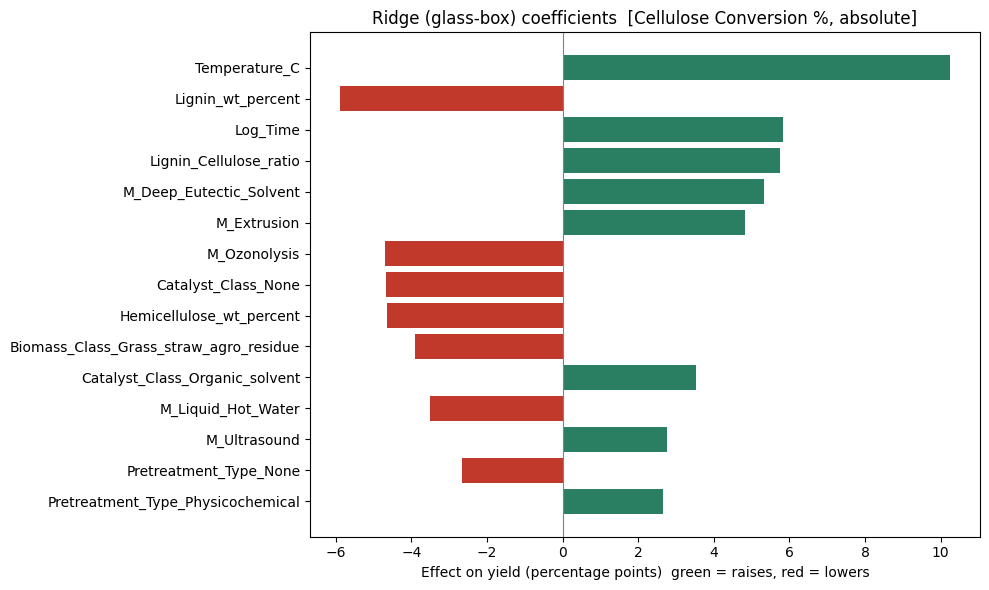

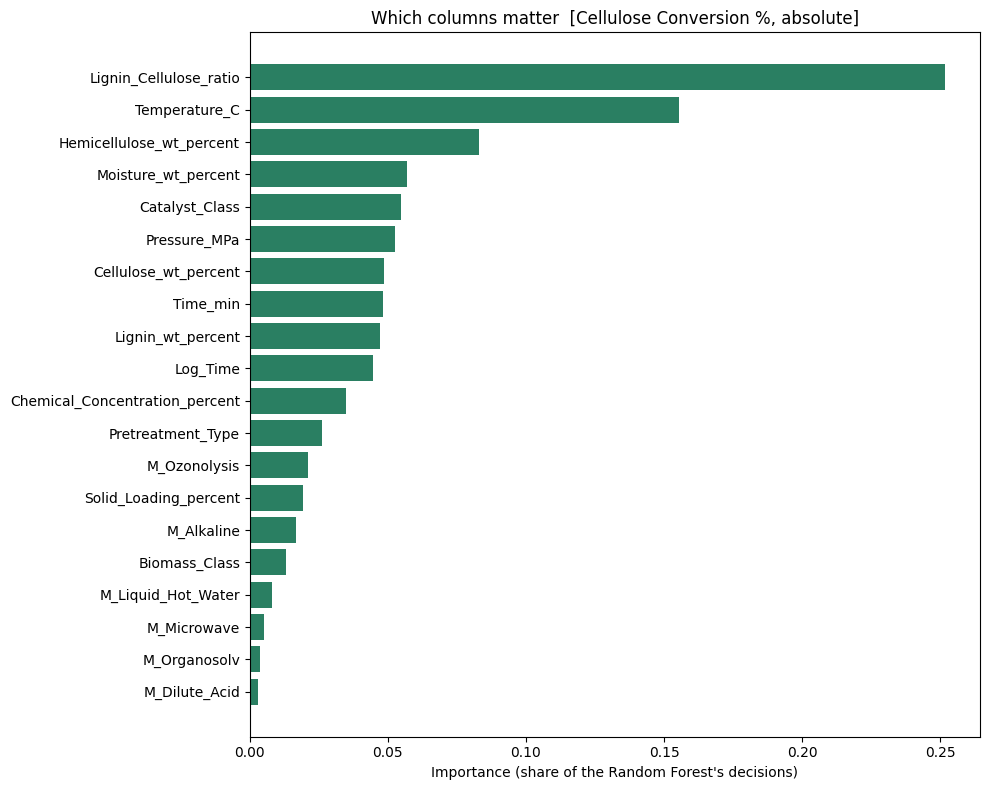


TOP COLUMNS: Lignin_Cellulose_ratio, Temperature_C, Hemicellulose_wt_percent, Moisture_wt_percent, Catalyst_Class, Pressure_MPa, Cellulose_wt_percent, Time_min

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

RUN: Glucose Yield % | mode: absolute
Rows: 168 | Papers: 32 | Biomass: 20 | Methods: 24
Target mean 62.8, SD 23.7

PREDICTORS
  [dropped] pH                                   5.4% filled
  [dropped] Energy_Proxy_Severity_Factor        17.9% filled
  categorical: ['Catalyst_Class', 'Biomass_Class', 'Pretreatment_Type']
  numeric    : ['Cellulose_wt_percent', 'Hemicellulose_wt_percent', 'Lignin_wt_percent', 'Moisture_wt_percent', 'Temperature_C', 'Pressure_MPa', 'Time_min', 'Solid_Loading_percent', 'Chemical_Concentration_percent', 'Lignin_Cellulose_ratio', 'Log_Time', 'M_Dilute_Acid', 'M_Alkaline', 'M_Organosolv', 'M_Deep_Eutectic_Solvent', 'M_Liquid_Hot_Water', 'M_Microwave', 'M_Ozonolysis', 'M_Steam_Explosion', 'M_Fungal', 'M_Ionic_Liquid',

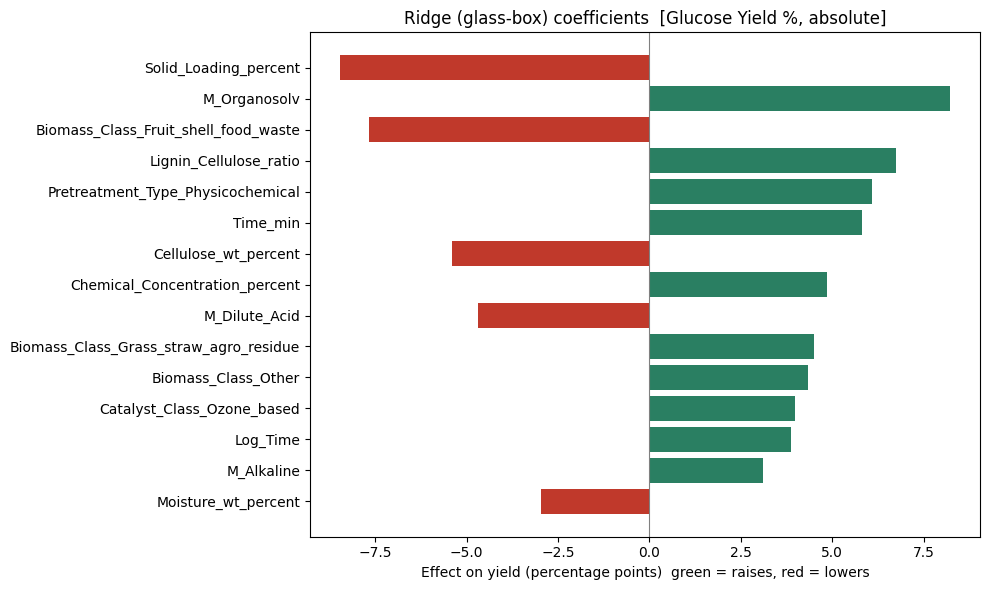

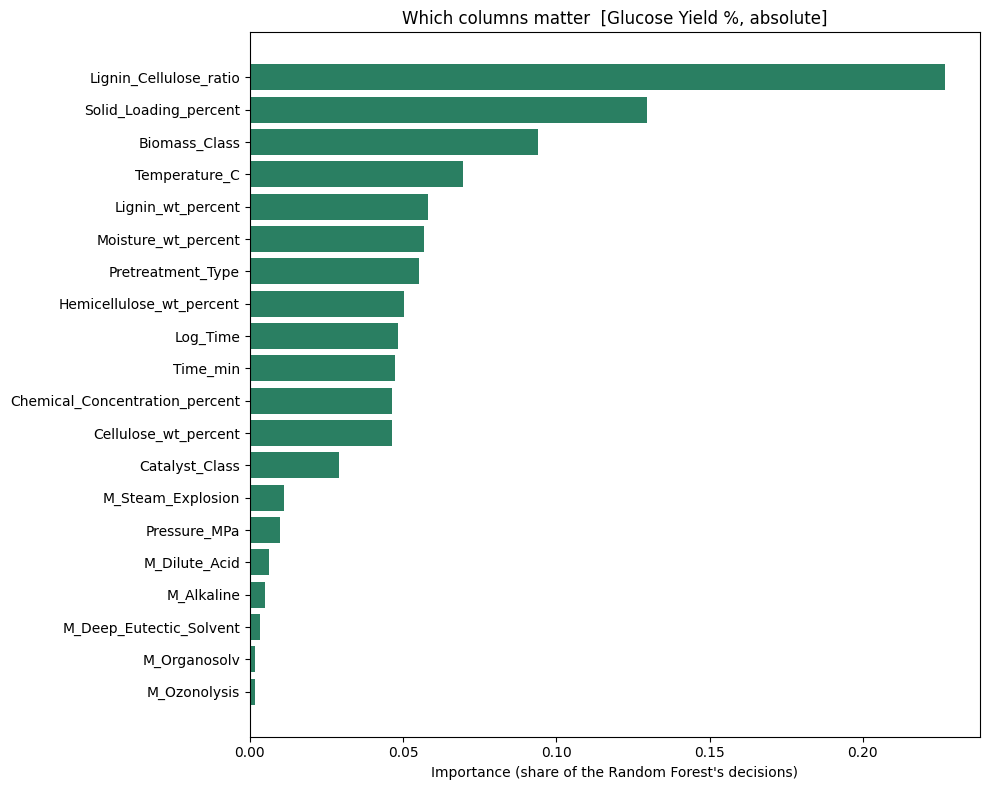


TOP COLUMNS: Lignin_Cellulose_ratio, Solid_Loading_percent, Biomass_Class, Temperature_C, Lignin_wt_percent, Moisture_wt_percent, Pretreatment_Type, Hemicellulose_wt_percent

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

RUN: Sugar Recovery % | mode: absolute
!! Dropped 10 rows with yield outside 0-100% (likely mixed units).
Rows: 173 | Papers: 34 | Biomass: 26 | Methods: 18
Target mean 51.0, SD 32.5

PREDICTORS
  [dropped] Pressure_MPa                        11.0% filled
  [dropped] pH                                  11.6% filled
  [dropped] Energy_Proxy_Severity_Factor         3.5% filled
  [dropped] M_Microwave                        100.0% filled  (constant)
  categorical: ['Catalyst_Class', 'Biomass_Class', 'Pretreatment_Type']
  numeric    : ['Cellulose_wt_percent', 'Hemicellulose_wt_percent', 'Lignin_wt_percent', 'Moisture_wt_percent', 'Temperature_C', 'Time_min', 'Solid_Loading_percent', 'Chemical_Concentration_percent', 'Lignin_Cellulo

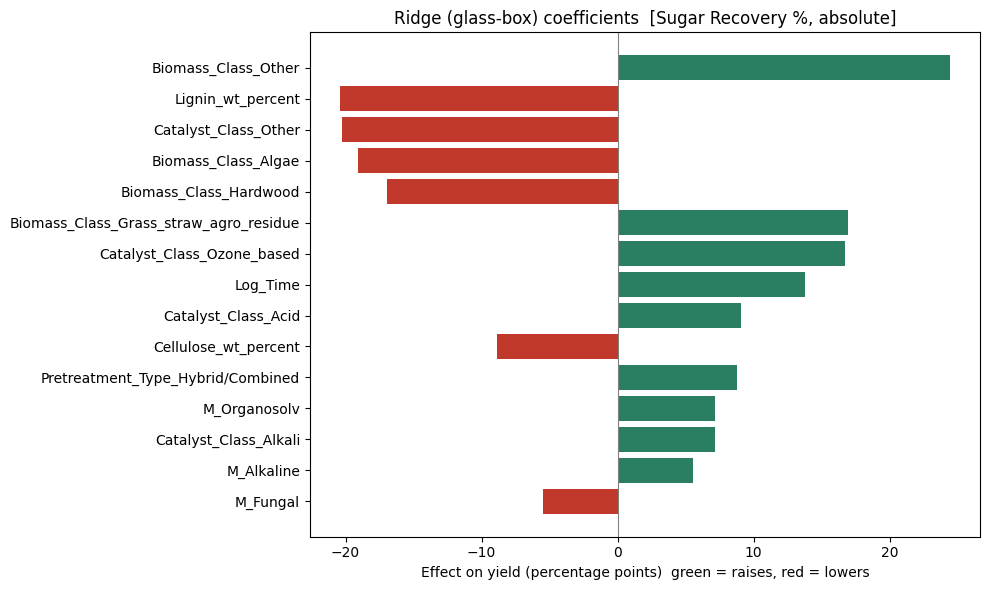

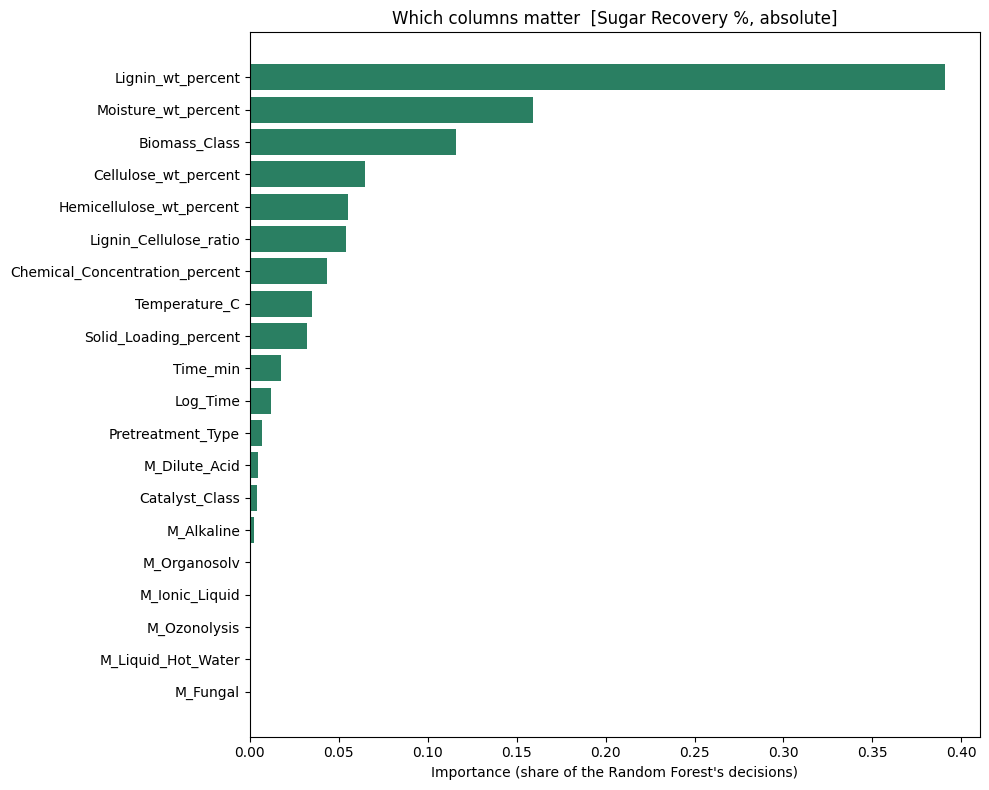


TOP COLUMNS: Lignin_wt_percent, Moisture_wt_percent, Biomass_Class, Cellulose_wt_percent, Hemicellulose_wt_percent, Lignin_Cellulose_ratio, Chemical_Concentration_percent, Temperature_C

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

RUN: POOLED | mode: absolute
!! Dropped 10 rows with yield outside 0-100% (likely mixed units).
Rows: 607 | Papers: 98 | Biomass: 52 | Methods: 43
Target mean 58.8, SD 26.7

PREDICTORS
  [dropped] pH                                  11.5% filled
  [dropped] Energy_Proxy_Severity_Factor        12.5% filled
  categorical: ['Catalyst_Class', 'Biomass_Class', 'Pretreatment_Type', 'Target_Yield_Type']
  numeric    : ['Cellulose_wt_percent', 'Hemicellulose_wt_percent', 'Lignin_wt_percent', 'Moisture_wt_percent', 'Temperature_C', 'Pressure_MPa', 'Time_min', 'Solid_Loading_percent', 'Chemical_Concentration_percent', 'Lignin_Cellulose_ratio', 'Log_Time', 'M_Dilute_Acid', 'M_Alkaline', 'M_Organosolv', 'M_Deep_Eutectic_Solvent'

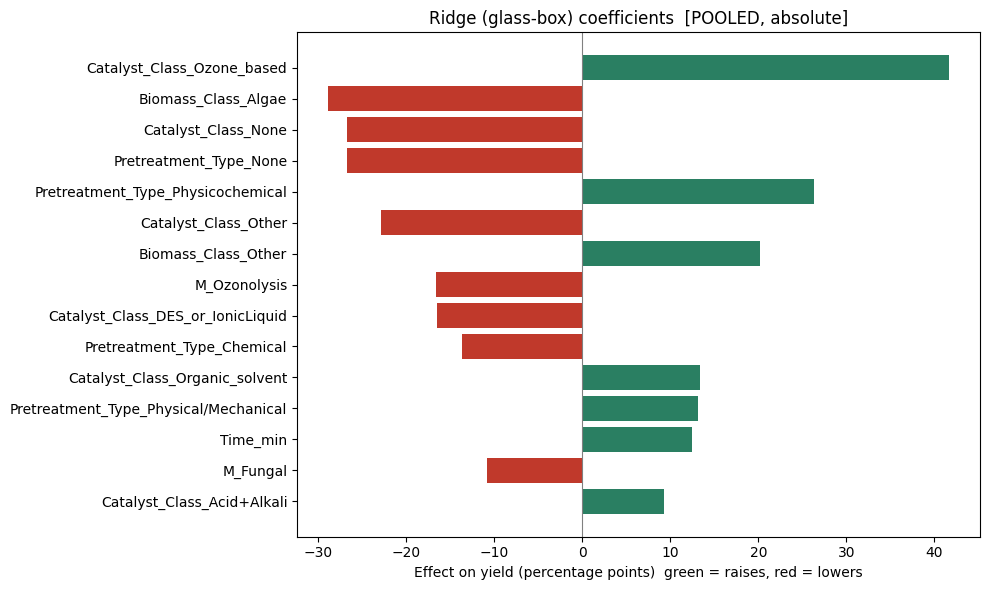

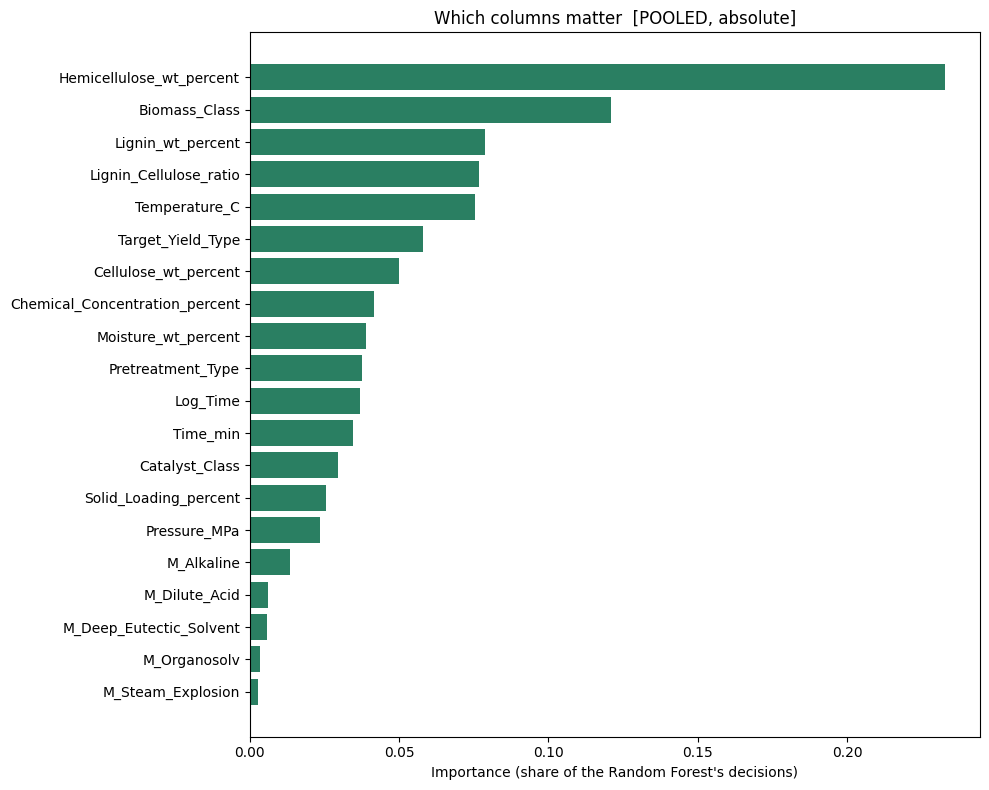


TOP COLUMNS: Hemicellulose_wt_percent, Biomass_Class, Lignin_wt_percent, Lignin_Cellulose_ratio, Temperature_C, Target_Yield_Type, Cellulose_wt_percent, Chemical_Concentration_percent

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

RUN: Cellulose Conversion % | mode: within_paper
WITHIN-PAPER mode: target = yield minus that paper's mean (only papers with >=2 rows). R2/RMSE refer to this deviation.
Rows: 251 | Papers: 33 | Biomass: 23 | Methods: 27
Target mean -0.0, SD 15.5

PREDICTORS
  [dropped] pH                                  15.5% filled
  [dropped] Energy_Proxy_Severity_Factor        14.7% filled
  categorical: ['Catalyst_Class', 'Biomass_Class', 'Pretreatment_Type']
  numeric    : ['Cellulose_wt_percent', 'Hemicellulose_wt_percent', 'Lignin_wt_percent', 'Moisture_wt_percent', 'Temperature_C', 'Pressure_MPa', 'Time_min', 'Solid_Loading_percent', 'Chemical_Concentration_percent', 'Lignin_Cellulose_ratio', 'Log_Time', 'M_Dilute_Acid', 'M_Al

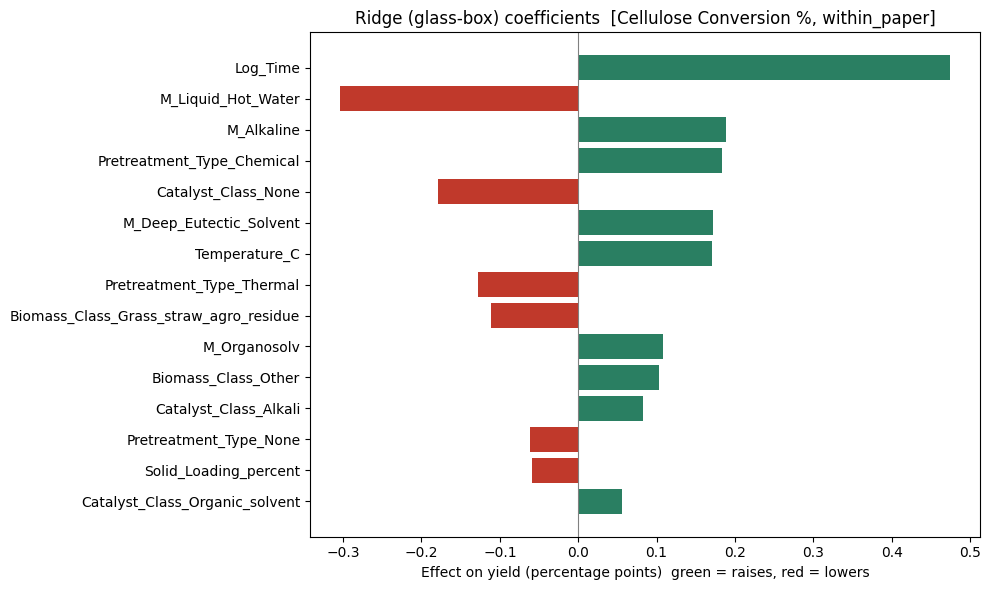

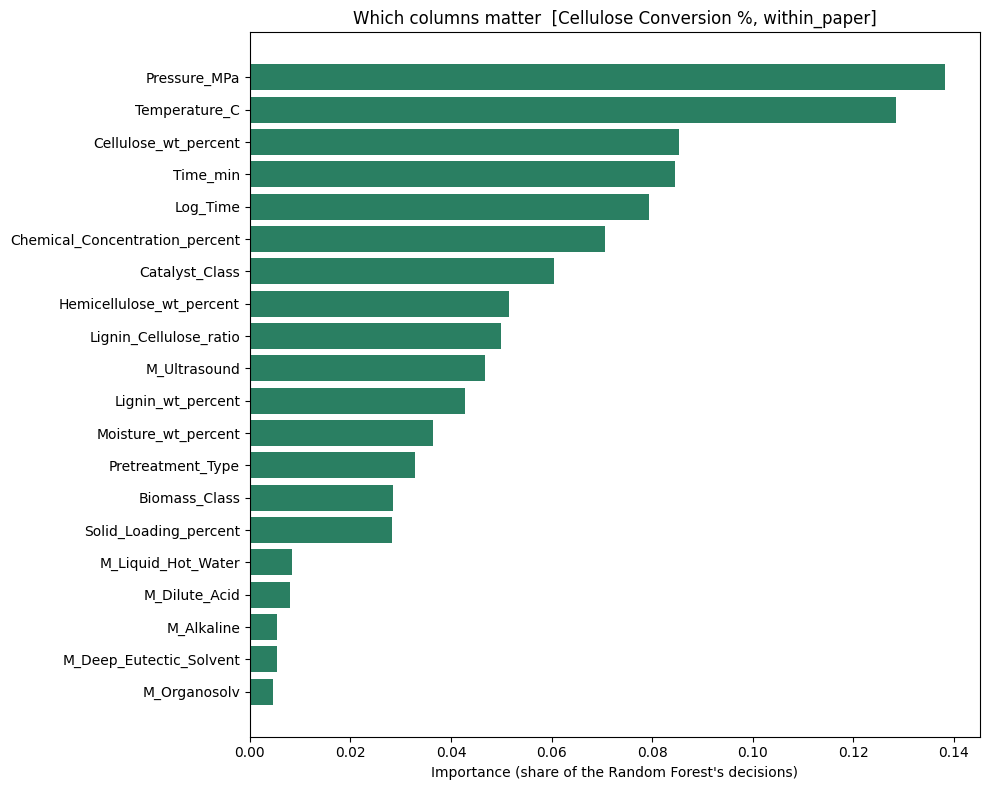


TOP COLUMNS: Pressure_MPa, Temperature_C, Cellulose_wt_percent, Time_min, Log_Time, Chemical_Concentration_percent, Catalyst_Class, Hemicellulose_wt_percent

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

RUN: Glucose Yield % | mode: within_paper
WITHIN-PAPER mode: target = yield minus that paper's mean (only papers with >=2 rows). R2/RMSE refer to this deviation.
Rows: 159 | Papers: 23 | Biomass: 17 | Methods: 19
Target mean -0.0, SD 14.3

PREDICTORS
  [dropped] pH                                   4.4% filled
  [dropped] Energy_Proxy_Severity_Factor        18.9% filled
  [dropped] M_Extrusion                        100.0% filled  (constant)
  categorical: ['Catalyst_Class', 'Biomass_Class', 'Pretreatment_Type']
  numeric    : ['Cellulose_wt_percent', 'Hemicellulose_wt_percent', 'Lignin_wt_percent', 'Moisture_wt_percent', 'Temperature_C', 'Pressure_MPa', 'Time_min', 'Solid_Loading_percent', 'Chemical_Concentration_percent', 'Lignin_Cellulose_rat

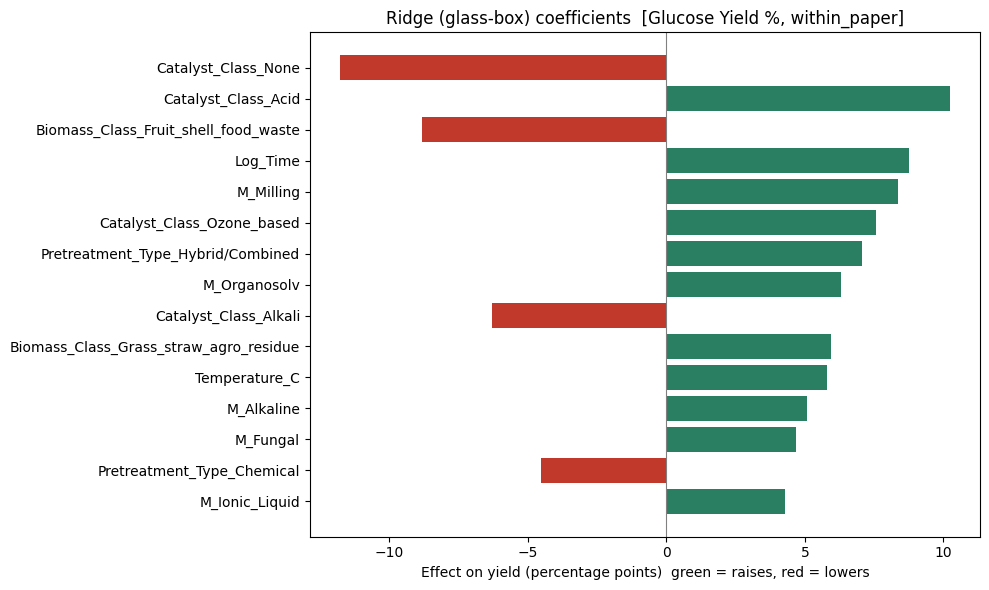

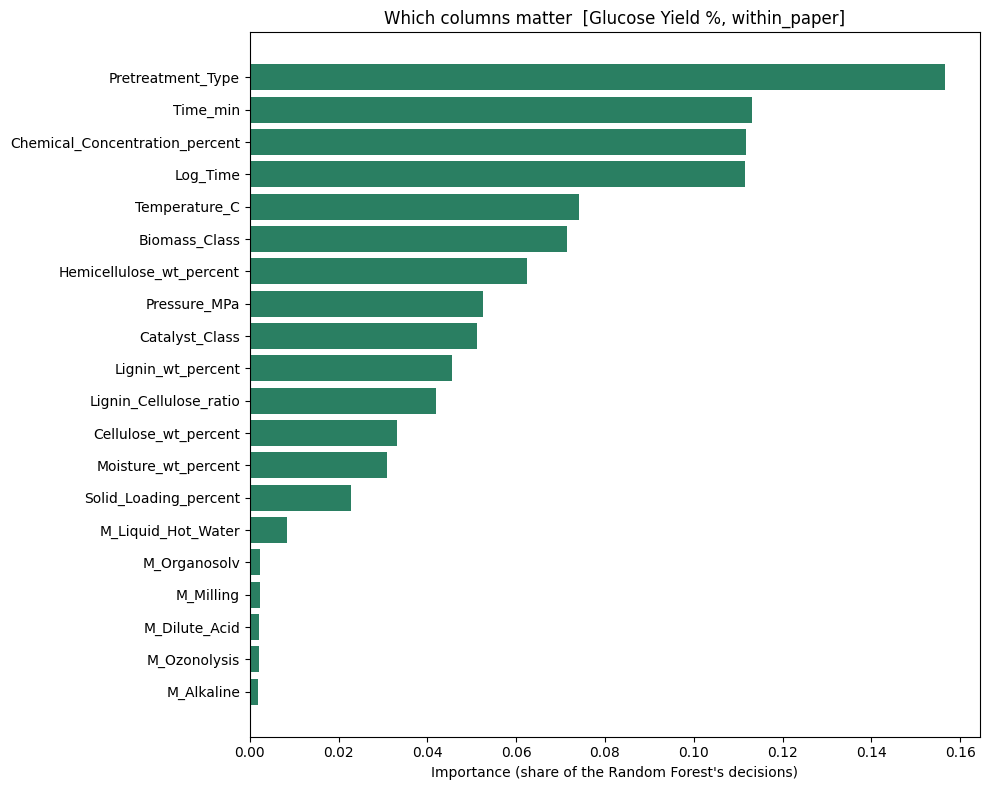


TOP COLUMNS: Pretreatment_Type, Time_min, Chemical_Concentration_percent, Log_Time, Temperature_C, Biomass_Class, Hemicellulose_wt_percent, Pressure_MPa

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

RUN: Sugar Recovery % | mode: within_paper
!! Dropped 10 rows with yield outside 0-100% (likely mixed units).
WITHIN-PAPER mode: target = yield minus that paper's mean (only papers with >=2 rows). R2/RMSE refer to this deviation.
Rows: 162 | Papers: 23 | Biomass: 22 | Methods: 15
Target mean -0.0, SD 9.9

PREDICTORS
  [dropped] Pressure_MPa                        10.5% filled
  [dropped] pH                                  11.1% filled
  [dropped] Energy_Proxy_Severity_Factor         2.5% filled
  [dropped] M_Microwave                        100.0% filled  (constant)
  [dropped] M_Steam_Explosion                  100.0% filled  (constant)
  [dropped] M_Extrusion                        100.0% filled  (constant)
  categorical: ['Catalyst_Class', 'Biom

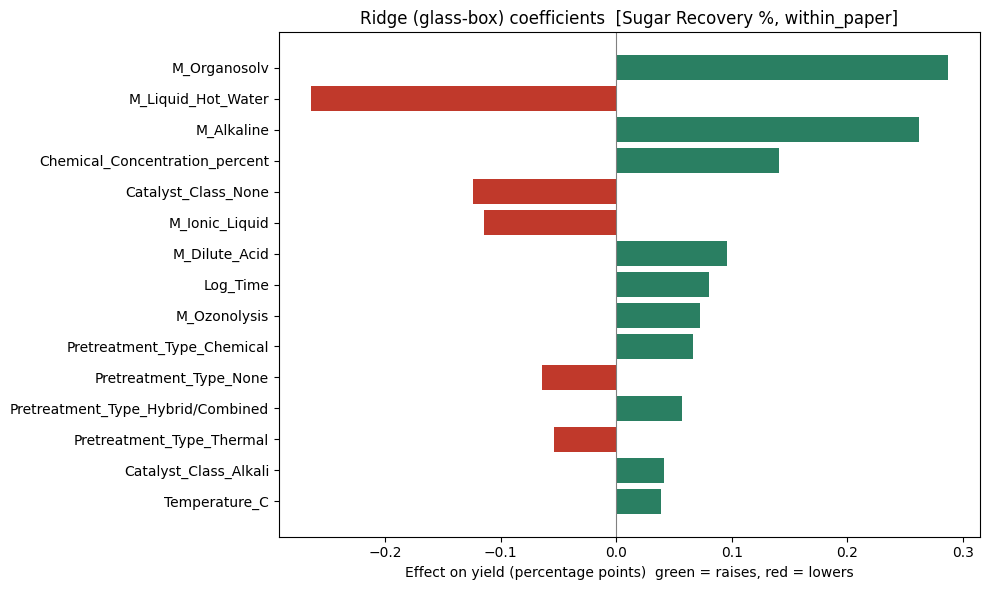

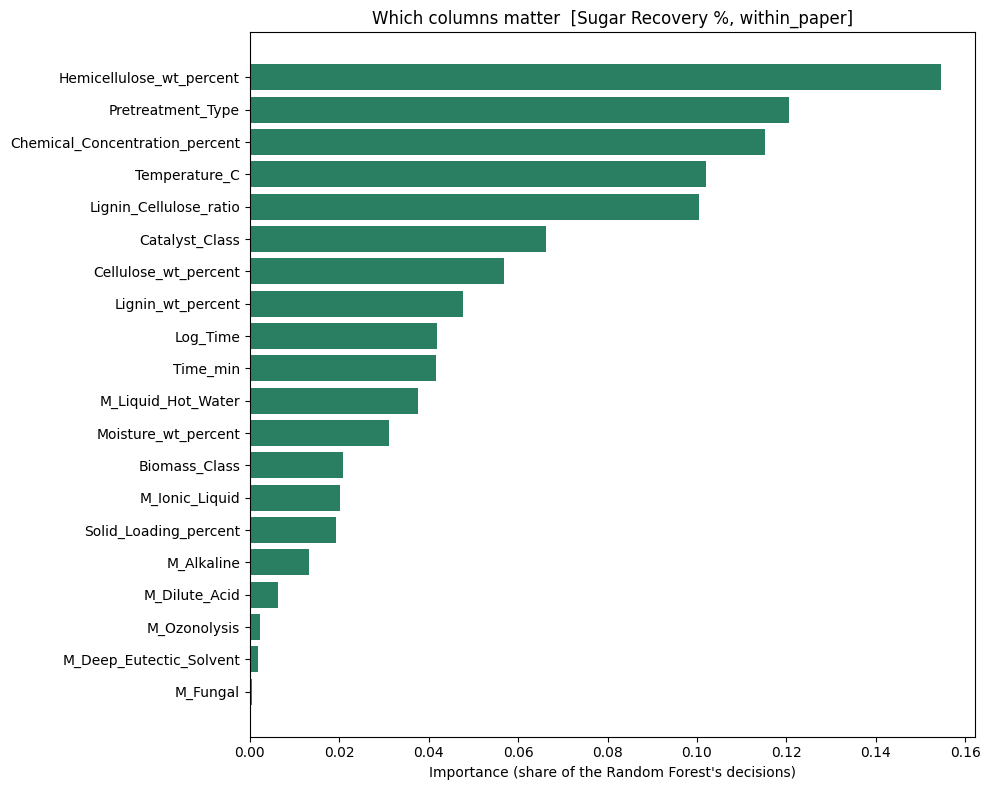


TOP COLUMNS: Hemicellulose_wt_percent, Pretreatment_Type, Chemical_Concentration_percent, Temperature_C, Lignin_Cellulose_ratio, Catalyst_Class, Cellulose_wt_percent, Lignin_wt_percent

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

RUN: POOLED | mode: within_paper
!! Dropped 10 rows with yield outside 0-100% (likely mixed units).
WITHIN-PAPER mode: target = yield minus that paper's mean (only papers with >=2 rows). R2/RMSE refer to this deviation.
Rows: 572 | Papers: 69 | Biomass: 42 | Methods: 35
Target mean -0.0, SD 13.8

PREDICTORS
  [dropped] pH                                  11.2% filled
  [dropped] Energy_Proxy_Severity_Factor        12.4% filled
  categorical: ['Catalyst_Class', 'Biomass_Class', 'Pretreatment_Type', 'Target_Yield_Type']
  numeric    : ['Cellulose_wt_percent', 'Hemicellulose_wt_percent', 'Lignin_wt_percent', 'Moisture_wt_percent', 'Temperature_C', 'Pressure_MPa', 'Time_min', 'Solid_Loading_percent', 'Chemical_Concentrati

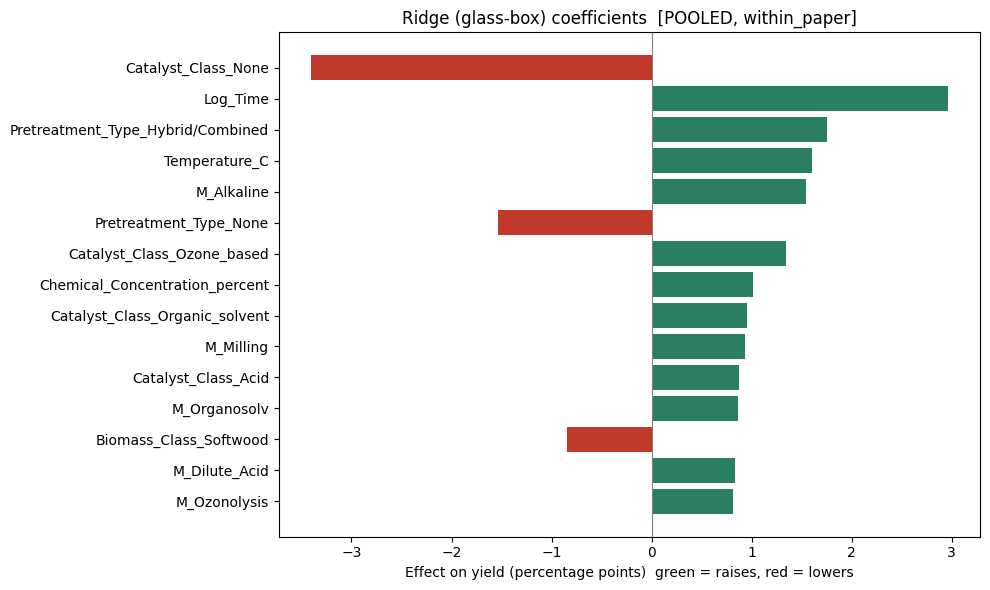

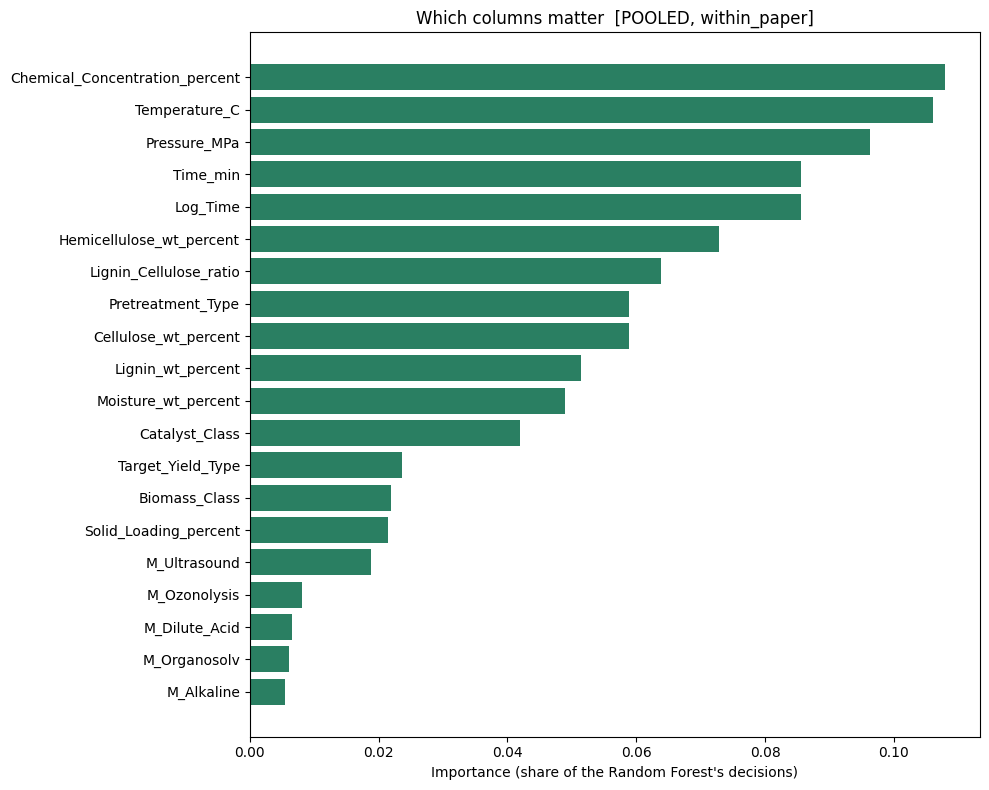


TOP COLUMNS: Chemical_Concentration_percent, Temperature_C, Pressure_MPa, Time_min, Log_Time, Hemicellulose_wt_percent, Lignin_Cellulose_ratio, Pretreatment_Type

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

SUMMARY OF ALL RUNS (paper-grouped validation)
                   Run         Mode  Rows  Papers        Best_model     R2   RMSE  Baseline_R2  Gain_vs_baseline
Cellulose Conversion %     absolute   266      48 Ridge (glass-box) -0.090 24.052       -0.063            -0.027
       Glucose Yield %     absolute   168      32     Random Forest -0.632 29.887       -0.042            -0.590
      Sugar Recovery %     absolute   173      34     Random Forest  0.038 31.698       -0.149             0.187
                POOLED     absolute   607      98       Extra Trees -0.062 27.469       -0.026            -0.036
Cellulose Conversion % within_paper   251      33     Random Forest -0.060 15.954        0.000            -0.060
       Glucose Yield % wi

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ================================================================
# BIOETHANOL / PRETREATMENT YIELD MODELLING  (v3)
# Pretreatment-focused targets | absolute + WITHIN-PAPER modes | glass-box plots
# ================================================================
# Paste into ONE Google Colab cell. Optional glass-box EBM:
#     !pip install interpret
# ================================================================
import re
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution
from sklearn.base import clone, BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor,
                              GradientBoostingRegressor,
                              HistGradientBoostingRegressor)
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
warnings.filterwarnings("ignore")

try:
    from interpret.glassbox import ExplainableBoostingRegressor
    HAS_EBM = True
except Exception:
    HAS_EBM = False
    print("NOTE: 'interpret' not installed -> EBM skipped. "
          "Run:  !pip install interpret")

# ---------------------------------------------------
# 1. CONFIGURATION
# ---------------------------------------------------
FILE_NAME = "/FINAL DATASET.csv"
SHEET_NAME = 0
TARGET = "Target_Yield_percent"
YIELD_TYPE_COLUMN = "Target_Yield_Type"
BIOMASS_COL, TYPE_COL, METHOD_COL = "Biomass_Type", "Pretreatment_Type", "Pretreatment_Method"
PAPER_COL = "Paper_ID"
SEVERITY_COL = "Energy_Proxy_Severity_Factor"

# Each entry = one modelling run. One yield type  -> separate model.
# Several yield types -> POOLED model (yield type becomes a feature).
# Pretreatment effectiveness is measured by cellulose conversion / glucose /
# sugar recovery (they depend directly on pretreatment). Ethanol yield also
# depends on enzymes and fermentation, so it is NOT run by default.
# To add it, append ["Ethanol Yield %"] to RUNS.
RUNS = [
    ["Cellulose Conversion %"],
    ["Glucose Yield %"],
    ["Sugar Recovery %"],
    ["Cellulose Conversion %", "Glucose Yield %", "Sugar Recovery %"],   # pooled
]
# "absolute"     : predict the yield itself (hard: labs differ a lot)
# "within_paper" : predict yield minus that paper's own average yield, i.e.
#                  "which conditions beat the other conditions in the SAME paper"
TARGET_MODES = ["absolute", "within_paper"]
ADD_MISSING_INDICATORS = False   # False = model cannot learn "which paper omitted X"
OPTIMIZABLE_YIELD_TYPES = ["Glucose Yield %", "Ethanol Yield %",
                           "Sugar Recovery %", "Cellulose Conversion %"]
DROP_OUT_OF_RANGE = True      # drop yields <0 or >100 (mixed units) before modelling
MIN_ROWS_PER_RUN = 30
RANDOM_STATE = 42
N_FOLDS = 5
N_REPEATS = 3                 # repeated paper-grouped CV (more stable than 1 run)
OPTIMIZE_MIN_R2 = 0.30        # optimise only if validated R2 reaches this
MIN_COMPLETENESS = 0.20
MIN_ROWS_PER_COMBINATION = 5
MIN_VALUES_FOR_OPTIMIZATION = 5
LOWER_PERCENTILE, UPPER_PERCENTILE = 5, 95
OPTIMIZER_MAXITER, OPTIMIZER_POPSIZE = 60, 10
MIN_ROWS_PER_FLAG = 5         # a method component needs this many rows to get a 0/1 flag

# Very high-cardinality one-hots hurt on small data. Biomass is replaced by
# Biomass_Class; the specific method is replaced by 0/1 component flags.
USE_BIOMASS_ONEHOT = False
USE_METHOD_ONEHOT = False
USE_TYPE_ONEHOT = True

CATEGORICAL_BASE = ["Catalyst_Class", "Biomass_Class"]
NUMERIC_BASE = ["Cellulose_wt_percent", "Hemicellulose_wt_percent",
                "Lignin_wt_percent", "Moisture_wt_percent",
                "Temperature_C", "Pressure_MPa", "Time_min",
                "Solid_Loading_percent", "Chemical_Concentration_percent",
                "pH", "Energy_Proxy_Severity_Factor",
                "Lignin_Cellulose_ratio", "Log_Time"]
RAW_NUMERIC = ["Cellulose_wt_percent", "Hemicellulose_wt_percent",
               "Lignin_wt_percent", "Moisture_wt_percent", "Temperature_C",
               "Pressure_MPa", "Time_min", "Solid_Loading_percent",
               "Chemical_Concentration_percent", "pH", SEVERITY_COL]
OPTIMIZABLE_COLUMNS = ["Temperature_C", "Time_min",
                       "Chemical_Concentration_percent", "Solid_Loading_percent"]
COMPOSITION_COLUMNS = ["Cellulose_wt_percent", "Hemicellulose_wt_percent",
                       "Lignin_wt_percent", "Moisture_wt_percent"]
SEVERITY_TYPES = ["Thermal", "Physicochemical"]
SEVERITY_TERMS = ["hydrothermal", "steam explosion", "steam treatment",
                  "liquid hot water", "hot water", "autohydrolysis"]

# Heuristic biomass classes - CHECK these against your biomass list.
BIOMASS_CLASS_RULES = [
    ("Algae", ["algae", "macroalgae", "microalgae", "seaweed", "azolla", "spirulina"]),
    ("Softwood", ["softwood", "pine", "spruce", "fir", "cedar"]),
    ("Hardwood", ["hardwood", "poplar", "eucalyptus", "birch", "willow", "oak", "beech"]),
    ("Fruit_shell_food_waste", ["peel", "fruit bunch", "shell", "pomace", "kitchen", "food waste"]),
    ("Grass_straw_agro_residue", ["straw", "stover", "bagasse", "grass", "stalk", "stillage",
                                  "spent grain", "bran", "husk", "sugarcane", "switchgrass",
                                  "miscanthus", "cob", "hull"]),
]

def slug(s):
    return re.sub(r"[^A-Za-z0-9]+", "_", str(s)).strip("_")

# ---------------------------------------------------
# 2. LOAD
# ---------------------------------------------------
def find_file():
    for c in [FILE_NAME, "/content/" + FILE_NAME, "/content/drive/MyDrive/" + FILE_NAME]:
        if Path(c).exists():
            return Path(c)
    try:
        from google.colab import files
        print("Dataset not found. Please upload it now...")
        return Path(list(files.upload().keys())[0])
    except ImportError:
        raise FileNotFoundError(f"Dataset not found: {FILE_NAME}")

def load_dataset():
    path = find_file()
    na = ["NaN", "nan", ""]
    if path.suffix.lower() == ".csv":
        try:
            df = pd.read_csv(path, na_values=na, keep_default_na=False, encoding="utf-8")
        except UnicodeDecodeError:
            print("!! UTF-8 failed, retrying with cp1252")
            df = pd.read_csv(path, na_values=na, keep_default_na=False, encoding="cp1252")
    else:
        df = pd.read_excel(path, sheet_name=SHEET_NAME, na_values=na, keep_default_na=False)
    df.columns = df.columns.astype(str).str.strip()
    print("Dataset shape:", df.shape)
    return df

# ---------------------------------------------------
# 3. GLOBAL CLEANING + FEATURE ENGINEERING (all yield types, ~all papers)
# ---------------------------------------------------
def severity_applicable(method, ptype):
    m = str(method).lower()
    return (str(ptype) in SEVERITY_TYPES and "+" not in m
            and any(t in m for t in SEVERITY_TERMS))

def sat_pressure_mpa(T):
    T = np.asarray(T, float)
    p = np.where(T < 100, 10 ** (8.07131 - 1730.63 / (233.426 + T)),
                 10 ** (8.14019 - 1810.94 / (244.485 + T)))
    return p * 0.000133322

def catalyst_class(name):
    """Group ~120 catalyst strings into a few chemistry classes."""
    n = str(name).lower().replace(" ", "")
    if n in ("none", "nan", "water", "h2o", ""):
        return "None"
    if any(k in n for k in ("choline", "chcl", "[", "ionic", "urea")):
        return "DES_or_IonicLiquid"
    acid = any(k in n for k in ("h2so4", "hcl", "hno3", "h3po4", "acid", "c2h2o4", "oxalic"))
    alk = any(k in n for k in ("naoh", "koh", "nh4oh", "ammonia", "ca(oh)2", "na2co3", "na2s", "nacs", "lime"))
    if acid and alk:
        return "Acid+Alkali"
    if "o3" in n:
        return "Ozone_based"
    if "h2o2" in n or "peroxide" in n:
        return "Peroxide_based"
    if acid:
        return "Acid"
    if alk:
        return "Alkali"
    if any(k in n for k in ("ethanol", "acetone", "glycerol", "methanol", "organosolv")):
        return "Organic_solvent"
    return "Other"

def biomass_class(name):
    n = str(name).lower()
    for cls, kws in BIOMASS_CLASS_RULES:
        for kw in kws:
            if re.search(r"\b" + re.escape(kw) + r"s?\b", n):
                return cls
    return "Other"

def add_derived(frame):
    if {"Lignin_wt_percent", "Cellulose_wt_percent"} <= set(frame.columns):
        c = frame["Cellulose_wt_percent"].where(frame["Cellulose_wt_percent"] > 0)
        frame["Lignin_Cellulose_ratio"] = frame["Lignin_wt_percent"] / c
    if "Time_min" in frame.columns:
        frame["Log_Time"] = np.log1p(frame["Time_min"].clip(lower=0))
    return frame

def clean_global(raw):
    df = raw.copy()
    required = [TARGET, YIELD_TYPE_COLUMN, BIOMASS_COL, TYPE_COL, METHOD_COL, PAPER_COL]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Required columns missing: {missing}")
    for c in df.columns:
        df[c] = df[c].apply(lambda x: x.strip() if isinstance(x, str) else x)
        df[c] = df[c].replace("", np.nan)
    # stray repeated header rows (your counts showed 'Target_Yield_Type': 1)
    n0 = len(df)
    df = df[(df[YIELD_TYPE_COLUMN] != YIELD_TYPE_COLUMN) & (df[PAPER_COL] != PAPER_COL)]
    if len(df) < n0:
        print(f"Removed {n0 - len(df)} stray header row(s) inside the data.")
    for c in RAW_NUMERIC + [TARGET]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.dropna(subset=[TARGET, BIOMASS_COL, TYPE_COL, METHOD_COL]).reset_index(drop=True)

    # composition: fill from the SAME biomass type (feature-only, no target used)
    for c in COMPOSITION_COLUMNS:
        if c in df.columns:
            df[c] = df[c].fillna(df.groupby(BIOMASS_COL)[c].transform("median"))
    # pressure from temperature for steam/hot-water methods (saturated steam)
    if "Pressure_MPa" in df.columns and "Temperature_C" in df.columns:
        steam = df[METHOD_COL].str.lower().apply(lambda m: any(t in m for t in SEVERITY_TERMS))
        mask = (df["Pressure_MPa"].isna() & df["Temperature_C"].ge(100)
                & steam & df[TYPE_COL].isin(SEVERITY_TYPES))
        df.loc[mask, "Pressure_MPa"] = sat_pressure_mpa(df.loc[mask, "Temperature_C"])
        print(f"Pressure filled from temperature for {int(mask.sum())} rows.")
    # severity log10(R0) for single thermal methods
    if SEVERITY_COL in df.columns:
        app = df.apply(lambda r: severity_applicable(r[METHOD_COL], r[TYPE_COL]), axis=1)
        mask = (df[SEVERITY_COL].isna() & app
                & df["Time_min"].notna() & df["Temperature_C"].notna())
        df.loc[mask, SEVERITY_COL] = np.log10(
            df.loc[mask, "Time_min"] * np.exp((df.loc[mask, "Temperature_C"] - 100) / 14.75))
        print(f"Severity factor computed for {int(mask.sum())} rows.")

    df = add_derived(df)
    df["Biomass_Class"] = df[BIOMASS_COL].apply(biomass_class)
    df["Catalyst_Class"] = df["Catalyst_Chemical"].apply(catalyst_class)
    print("Catalyst classes:", df["Catalyst_Class"].value_counts().to_dict())

    # multi-hot method components: "A + B" shares signal with "A" and "B"
    tokens = df[METHOD_COL].str.split("+").explode().str.strip()
    counts = tokens.value_counts()
    flag_cols = []
    for t, cnt in counts.items():
        if cnt >= MIN_ROWS_PER_FLAG and t.lower() != "none":
            col = "M_" + slug(t)
            df[col] = df[METHOD_COL].apply(
                lambda m, t=t: int(t in [x.strip() for x in str(m).split("+")]))
            flag_cols.append(col)
    print("Method component flags:", flag_cols)

    cov = (df.groupby(YIELD_TYPE_COLUMN)
             .agg(Rows=(TARGET, "size"), Papers=(PAPER_COL, "nunique"),
                  Biomass=(BIOMASS_COL, "nunique"))
             .sort_values("Papers", ascending=False))
    print("\nDATA COVERAGE PER YIELD TYPE")
    print(cov.to_string())
    print(f"TOTAL: {len(df)} rows, {df[PAPER_COL].nunique()} papers")
    print("Biomass classes:", df["Biomass_Class"].value_counts().to_dict())
    return df, flag_cols

def subset_for_run(clean, yield_types, mode="absolute"):
    df = clean[clean[YIELD_TYPE_COLUMN].isin(yield_types)].copy()
    odd = ((df[TARGET] < 0) | (df[TARGET] > 100)).sum()
    if odd:
        if DROP_OUT_OF_RANGE:
            df = df[(df[TARGET] >= 0) & (df[TARGET] <= 100)]
            print(f"!! Dropped {odd} rows with yield outside 0-100% (likely mixed units).")
        else:
            print(f"!! {odd} rows outside 0-100% kept.")
    df = df.reset_index(drop=True)
    if mode == "within_paper":
        grp = [PAPER_COL, YIELD_TYPE_COLUMN]
        df = df[df.groupby(grp)[TARGET].transform("size") >= 2].copy()
        df["Yield_abs"] = df[TARGET]
        df[TARGET] = df[TARGET] - df.groupby(grp)[TARGET].transform("mean")
        df = df.reset_index(drop=True)
        print("WITHIN-PAPER mode: target = yield minus that paper's mean "
              "(only papers with >=2 rows). R2/RMSE refer to this deviation.")
    if len(df) < MIN_ROWS_PER_RUN:
        raise ValueError(f"only {len(df)} usable rows")
    print(f"Rows: {len(df)} | Papers: {df[PAPER_COL].nunique()} | "
          f"Biomass: {df[BIOMASS_COL].nunique()} | Methods: {df[METHOD_COL].nunique()}")
    print(f"Target mean {df[TARGET].mean():.1f}, SD {df[TARGET].std():.1f}")
    return df

# ---------------------------------------------------
# 4. FEATURES + PIPELINES
# ---------------------------------------------------
def select_features(df, flag_cols, pooled):
    cat_cand = list(CATEGORICAL_BASE)
    if USE_BIOMASS_ONEHOT: cat_cand.append(BIOMASS_COL)
    if USE_TYPE_ONEHOT: cat_cand.append(TYPE_COL)
    if USE_METHOD_ONEHOT: cat_cand.append(METHOD_COL)
    if pooled: cat_cand.append(YIELD_TYPE_COLUMN)
    num_cand = NUMERIC_BASE + flag_cols
    categorical, numeric = [], []
    print("\nPREDICTORS")
    for col in cat_cand + num_cand:
        if col not in df.columns:
            continue
        frac = df[col].notna().mean()
        const = df[col].nunique(dropna=True) < 2
        keep = frac >= MIN_COMPLETENESS and not const
        if not keep:
            print(f"  [dropped] {col:<34s} {frac:6.1%} filled{'  (constant)' if const else ''}")
            continue
        (categorical if col in cat_cand else numeric).append(col)
    print("  categorical:", categorical)
    print("  numeric    :", numeric)
    return {"categorical": categorical, "numeric": numeric, "all": categorical + numeric}

class EBMRegressorWrapper(BaseEstimator, RegressorMixin):
    """sklearn-style wrapper: EBM handles NaN & categories natively."""
    def __init__(self, cat_cols=None, interactions=3, learning_rate=0.02,
                 max_bins=32, min_samples_leaf=5, outer_bags=4, random_state=42):
        self.cat_cols = cat_cols
        self.interactions = interactions
        self.learning_rate = learning_rate
        self.max_bins = max_bins
        self.min_samples_leaf = min_samples_leaf
        self.outer_bags = outer_bags
        self.random_state = random_state
    def _prep(self, X):
        X = X.copy()
        cats = list(self.cat_cols or [])
        for c in X.columns:
            if c in cats:
                X[c] = X[c].fillna("Unknown").astype(str)
            else:
                X[c] = pd.to_numeric(X[c], errors="coerce").astype(float)
        return X
    def fit(self, X, y):
        self.model_ = ExplainableBoostingRegressor(
            interactions=self.interactions, learning_rate=self.learning_rate,
            max_bins=self.max_bins, min_samples_leaf=self.min_samples_leaf,
            outer_bags=self.outer_bags, random_state=self.random_state)
        self.model_.fit(self._prep(X), np.asarray(y))
        return self
    def predict(self, X):
        return self.model_.predict(self._prep(X))

def make_pipeline(model, features):
    if isinstance(model, EBMRegressorWrapper):
        return model
    num = Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=ADD_MISSING_INDICATORS)),
                    ("scaler", StandardScaler())])
    cat = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
                    ("encoder", OneHotEncoder(handle_unknown="ignore"))])
    pre = ColumnTransformer([("numeric", num, features["numeric"]),
                             ("categorical", cat, features["categorical"])])
    return Pipeline([("preprocessor", pre), ("model", model)])

def get_models(features):
    m = {
        "Mean baseline": DummyRegressor(strategy="mean"),
        "Ridge (glass-box)": RidgeCV(alphas=np.logspace(-1, 3, 20)),
        "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                               random_state=RANDOM_STATE, n_jobs=-1),
        "Extra Trees": ExtraTreesRegressor(n_estimators=300, min_samples_leaf=3,
                                           random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.04,
                                                       max_depth=3, subsample=0.8,
                                                       random_state=RANDOM_STATE),
        "HistGradientBoosting": HistGradientBoostingRegressor(
            max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=10,
            l2_regularization=1.0, random_state=RANDOM_STATE),
    }
    if HAS_EBM:
        m["EBM (glass-box)"] = EBMRegressorWrapper(cat_cols=features["categorical"],
                                                   random_state=RANDOM_STATE)
    return m

# ---------------------------------------------------
# 5. REPEATED PAPER-GROUPED VALIDATION
# ---------------------------------------------------
def grouped_splits(groups, n_splits, seed):
    """Whole groups (papers) are held out; assignment reshuffled per seed."""
    uniq = np.unique(groups)
    rng = np.random.RandomState(seed)
    rng.shuffle(uniq)
    fold_of = {g: i % n_splits for i, g in enumerate(uniq)}
    f = np.array([fold_of[g] for g in groups])
    for k in range(n_splits):
        yield np.where(f != k)[0], np.where(f == k)[0]

def get_groups(df):
    if df[PAPER_COL].notna().all() and df[PAPER_COL].nunique() >= 3:
        return df[PAPER_COL].astype(str).to_numpy(), "Paper-grouped"
    print("WARNING: Paper_ID unusable; row-level CV. Scores will be OPTIMISTIC.")
    return np.arange(len(df)).astype(str), "Row-level"

def train_and_compare(df, features, prefix, clip=True):
    X, y = df[features["all"]], df[TARGET]
    groups, cv_name = get_groups(df)
    n_splits = min(N_FOLDS, len(np.unique(groups)))
    print(f"\nValidation: {cv_name}, {n_splits} folds x {N_REPEATS} repeats "
          f"({len(np.unique(groups))} groups)")
    rows, oof_store = [], {}
    for name, model in get_models(features).items():
        print("Evaluating:", name)
        try:
            r2s, rmses, maes, errs, last = [], [], [], [], None
            for r in range(N_REPEATS):
                pred = np.full(len(y), np.nan)
                for tr, te in grouped_splits(groups, n_splits, RANDOM_STATE + r):
                    fit = make_pipeline(clone(model), features).fit(X.iloc[tr], y.iloc[tr])
                    pred[te] = fit.predict(X.iloc[te])
                if clip:
                    pred = np.clip(pred, 0, 100)
                r2s.append(r2_score(y, pred))
                rmses.append(np.sqrt(mean_squared_error(y, pred)))
                maes.append(mean_absolute_error(y, pred))
                errs.append(np.abs(y.to_numpy() - pred))
                last = pred
        except Exception as exc:
            print(f"  skipped {name}: {exc}")
            continue
        oof_store[name] = np.concatenate(errs)
        rows.append({"Model": name, "Validation": cv_name,
                     "R2_mean": np.mean(r2s), "R2_SD_over_repeats": np.std(r2s),
                     "RMSE": np.mean(rmses), "MAE": np.mean(maes)})
    comp = pd.DataFrame(rows).sort_values(["R2_mean", "RMSE"], ascending=[False, True]).reset_index(drop=True)
    base_r2 = comp.loc[comp["Model"] == "Mean baseline", "R2_mean"].iloc[0]
    comp["R2_gain_vs_baseline"] = comp["R2_mean"] - base_r2
    comp.to_csv(f"{prefix}_model_comparison.csv", index=False)
    print("\nMODEL COMPARISON (out-of-fold, paper-grouped)")
    print(comp.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
    cand = comp[comp["Model"] != "Mean baseline"]
    best_name = cand.iloc[0]["Model"]
    best_r2, best_rmse = cand.iloc[0]["R2_mean"], cand.iloc[0]["RMSE"]
    if best_r2 <= base_r2 + 0.02:
        print("WARNING: no model clearly beats the mean baseline. Predictions are unreliable.")
    elif best_r2 < 0.3:
        print("WARNING: low validated R2. Treat results as exploratory.")
    half_width = float(np.percentile(oof_store[best_name], 90))
    print(f"Best: {best_name} | R2 {best_r2:.3f} | RMSE {best_rmse:.2f} | "
          f"90% of errors within +/- {half_width:.1f} points")
    validate_unseen_biomass(df, features, best_name, prefix, clip)
    fitted = make_pipeline(get_models(features)[best_name], features).fit(X, y)
    return best_name, fitted, half_width, best_r2, best_rmse, base_r2

def validate_unseen_biomass(df, features, model_name, prefix, clip=True):
    if df[BIOMASS_COL].nunique() < N_FOLDS:
        return
    X, y = df[features["all"]], df[TARGET]
    groups = df[BIOMASS_COL].astype(str).to_numpy()
    pred = np.full(len(y), np.nan)
    for tr, te in grouped_splits(groups, N_FOLDS, RANDOM_STATE):
        try:
            fit = make_pipeline(clone(get_models(features)[model_name]), features)
            fit.fit(X.iloc[tr], y.iloc[tr])
            pred[te] = np.clip(fit.predict(X.iloc[te]), 0, 100) if clip else fit.predict(X.iloc[te])
        except Exception as exc:
            print("Unseen-biomass fold failed:", exc)
    ok = ~np.isnan(pred)
    if ok.sum() >= 2:
        r2 = r2_score(y[ok], pred[ok])
        rmse = np.sqrt(mean_squared_error(y[ok], pred[ok]))
        print(f"Unseen-biomass transfer: R2 {r2:.3f} | RMSE {rmse:.2f}")
        pd.DataFrame([{"R2": r2, "RMSE": rmse, "Rows": int(ok.sum())}]).to_csv(
            f"{prefix}_unseen_biomass_validation.csv", index=False)

# ---------------------------------------------------
# 6. GLASS-BOX EXPLANATIONS
# ---------------------------------------------------
def explain_glassbox(df, features, prefix):
    X, y = df[features["all"]], df[TARGET]
    ridge = make_pipeline(RidgeCV(alphas=np.logspace(-1, 3, 20)), features).fit(X, y)
    names = ridge.named_steps["preprocessor"].get_feature_names_out()
    coef = pd.DataFrame({
        "Feature": [n.replace("numeric__", "").replace("categorical__", "") for n in names],
        "Coefficient": ridge.named_steps["model"].coef_})
    coef = coef.reindex(coef["Coefficient"].abs().sort_values(ascending=False).index)
    coef.to_csv(f"{prefix}_ridge_coefficients.csv", index=False)
    print("\nRIDGE: yield-% change per +1 SD (numeric) or per category (one-hot)")
    print(coef.head(15).to_string(index=False, float_format=lambda v: f"{v:+.2f}"))

    if HAS_EBM:
        try:
            w = EBMRegressorWrapper(cat_cols=features["categorical"],
                                    random_state=RANDOM_STATE).fit(X, y)
            expl = w.model_.explain_global()
            d = expl.data()
            imp = pd.DataFrame({"Term": d["names"], "Importance": d["scores"]}
                               ).sort_values("Importance", ascending=False)
            imp.to_csv(f"{prefix}_ebm_term_importance.csv", index=False)
            print("\nEBM TERM IMPORTANCE (top 12)")
            print(imp.head(12).to_string(index=False, float_format=lambda v: f"{v:.2f}"))
            top = imp.head(9)["Term"].tolist()
            fig, axes = plt.subplots(3, 3, figsize=(15, 11))
            for ax in axes.ravel():
                ax.axis("off")
            for ax, term in zip(axes.ravel(), top):
                ax.axis("on")
                sd = expl.data(d["names"].index(term))
                x, s = list(sd["names"]), list(sd["scores"])
                if sd.get("type") != "univariate":
                    ax.set_title(term + " (interaction)", fontsize=9)
                    continue
                if len(x) == len(s) + 1:
                    ax.step(x, s + [s[-1]], where="post")
                else:
                    ax.bar(range(len(x)), s)
                    ax.set_xticks(range(len(x)))
                    ax.set_xticklabels(x, rotation=60, ha="right", fontsize=7)
                ax.axhline(0, color="grey", lw=0.5)
                ax.set_title(term, fontsize=9)
                ax.set_ylabel("effect on yield (%)")
            plt.tight_layout()
            plt.savefig(f"{prefix}_ebm_shapes.png", dpi=200)
            plt.show()
        except Exception as exc:
            print("EBM explanation failed:", exc)

def plot_importance(df, features, prefix, title_suffix=""):
    """Bar-chart ('histogram style') of which COLUMNS matter, from a Random Forest.
    One-hot pieces are added back together, so 'Catalyst_Class' is one bar."""
    X, y = df[features["all"]], df[TARGET]
    rf = make_pipeline(RandomForestRegressor(n_estimators=500, min_samples_leaf=3,
                                             random_state=RANDOM_STATE, n_jobs=-1), features).fit(X, y)
    names = rf.named_steps["preprocessor"].get_feature_names_out()
    imp = rf.named_steps["model"].feature_importances_
    rows = {}
    for n, v in zip(names, imp):
        n = n.replace("numeric__", "").replace("categorical__", "")
        base = n
        for c in features["categorical"]:
            if n.startswith(c + "_"):
                base = c
                break
        if n.startswith("missingindicator_"):
            base = n.replace("missingindicator_", "") + " (missing flag)"
        rows[base] = rows.get(base, 0.0) + float(v)
    t = (pd.DataFrame({"Column": list(rows), "Importance": list(rows.values())})
           .sort_values("Importance", ascending=False).reset_index(drop=True))
    t.to_csv(f"{prefix}_column_importance.csv", index=False)
    top = t.head(20)
    plt.figure(figsize=(10, 8))
    plt.barh(top["Column"][::-1], top["Importance"][::-1], color="#2a7f62")
    plt.xlabel("Importance (share of the Random Forest's decisions)")
    plt.title(f"Which columns matter  {title_suffix}")
    plt.tight_layout()
    plt.savefig(f"{prefix}_feature_importance.png", dpi=200)
    plt.show()
    print("\nTOP COLUMNS:", ", ".join(top["Column"].head(8)))

def plot_ridge(prefix, title_suffix=""):
    try:
        c = pd.read_csv(f"{prefix}_ridge_coefficients.csv").head(15)
        plt.figure(figsize=(10, 6))
        plt.barh(c["Feature"][::-1], c["Coefficient"][::-1],
                 color=["#2a7f62" if v > 0 else "#c0392b" for v in c["Coefficient"][::-1]])
        plt.axvline(0, color="grey", lw=0.8)
        plt.xlabel("Effect on yield (percentage points)  green = raises, red = lowers")
        plt.title(f"Ridge (glass-box) coefficients  {title_suffix}")
        plt.tight_layout()
        plt.savefig(f"{prefix}_ridge_coefficients.png", dpi=200)
        plt.show()
    except Exception as exc:
        print("Ridge plot failed:", exc)

# ---------------------------------------------------
# 7. OPTIMISATION (single yield type, only if the model is validated)
# ---------------------------------------------------
def safe_median(s):
    v = pd.to_numeric(s, errors="coerce").dropna()
    return float(v.median()) if len(v) else np.nan

def safe_mode(s):
    v = s.dropna()
    return v.mode().iloc[0] if len(v) else np.nan

def get_bounds(series):
    v = pd.to_numeric(series, errors="coerce").dropna()
    v = v[np.isfinite(v)]
    if len(v) < MIN_VALUES_FOR_OPTIMIZATION or v.nunique() < MIN_VALUES_FOR_OPTIMIZATION:
        return None
    lo, hi = np.percentile(v, [LOWER_PERCENTILE, UPPER_PERCENTILE])
    return (float(lo), float(hi)) if np.isfinite(lo) and np.isfinite(hi) and hi > lo else None

def optimize_all_combinations(df, features, model, half_width, prefix):
    combos = df[[BIOMASS_COL, TYPE_COL, METHOD_COL]].drop_duplicates()
    print(f"\nOptimising {len(combos)} biomass x method combinations...")
    results = []
    for _, cid in combos.iterrows():
        biomass, ptype, method = cid[BIOMASS_COL], cid[TYPE_COL], cid[METHOD_COL]
        combo = df[(df[BIOMASS_COL] == biomass) & (df[TYPE_COL] == ptype) & (df[METHOD_COL] == method)]
        method_data = df[(df[TYPE_COL] == ptype) & (df[METHOD_COL] == method)]
        biomass_data = df[df[BIOMASS_COL] == biomass]
        n = len(combo)
        support = "ADEQUATE" if n >= MIN_ROWS_PER_COMBINATION else "LOW"
        baseline = {}
        for col in features["categorical"]:
            if col == BIOMASS_COL: baseline[col] = biomass
            elif col == TYPE_COL: baseline[col] = ptype
            elif col == METHOD_COL: baseline[col] = method
            else:
                v = safe_mode(combo[col])
                baseline[col] = v if pd.notna(v) else safe_mode(method_data[col])
        for col in features["numeric"]:
            if col in COMPOSITION_COLUMNS:
                baseline[col] = safe_median(biomass_data[col])
            else:
                v = safe_median(combo[col])
                baseline[col] = v if pd.notna(v) else safe_median(method_data[col])
        bounds_by_col, bsrc = {}, {}
        for col in OPTIMIZABLE_COLUMNS:
            if col not in features["numeric"]:
                continue
            b, src = get_bounds(combo[col]), "biomass-method"
            if b is None:
                b, src = get_bounds(method_data[col]), "method-level"
            if b is not None:
                bounds_by_col[col], bsrc[col] = b, src
        names = list(bounds_by_col)
        bounds = [bounds_by_col[c] for c in names]
        recompute_sev = (SEVERITY_COL in features["numeric"]
                         and severity_applicable(method, ptype)
                         and method_data[SEVERITY_COL].notna().mean() >= 0.5
                         and {"Time_min", "Temperature_C"} <= set(features["all"]))

        def make_frame(x, n_rows):
            frame = pd.DataFrame({c: [baseline[c]] * n_rows for c in features["all"]})
            for i, col in enumerate(names):
                frame[col] = x[i]
            for col in features["numeric"]:
                frame[col] = pd.to_numeric(frame[col], errors="coerce")
            if recompute_sev:
                with np.errstate(over="ignore", invalid="ignore"):
                    frame[SEVERITY_COL] = np.log10(
                        frame["Time_min"] * np.exp((frame["Temperature_C"] - 100) / 14.75))
            tmp = add_derived(frame.copy())
            for c in ("Lignin_Cellulose_ratio", "Log_Time"):
                if c in features["all"] and c in tmp.columns:
                    frame[c] = tmp[c]
            for col in features["categorical"]:
                frame[col] = frame[col].astype(object)
            return frame[features["all"]]

        def objective(x):
            x = np.asarray(x)
            if x.ndim == 1:
                x = x.reshape(-1, 1)
            return -np.clip(model.predict(make_frame(x, x.shape[1])), 0, 100)

        if names:
            try:
                res = differential_evolution(objective, bounds, seed=RANDOM_STATE,
                                             maxiter=OPTIMIZER_MAXITER, popsize=OPTIMIZER_POPSIZE,
                                             tol=1e-6, polish=False, vectorized=True,
                                             updating="deferred")
                best_x, predicted = np.asarray(res.x), float(-res.fun)
                status = "OPTIMIZED" if support == "ADEQUATE" else "OPTIMIZED_LOW_SUPPORT"
            except Exception as exc:
                print(f"Optimisation failed {biomass}/{method}: {exc}")
                best_x, predicted, status = np.array([]), np.nan, "OPTIMIZATION_FAILED"
        else:
            best_x = np.array([])
            predicted = float(np.clip(model.predict(make_frame(np.empty((0, 1)), 1))[0], 0, 100))
            status = "PREDICTION_ONLY_NO_SUPPORTED_RANGE"
        rec = {"Biomass_Type": biomass, "Pretreatment_Type": ptype, "Pretreatment_Method": method,
               "Observed_rows": n, "Support_status": support, "Optimization_status": status,
               "Predicted_Yield_percent": predicted,
               "Interval_low_90pct": max(0.0, predicted - half_width),
               "Interval_high_90pct": min(100.0, predicted + half_width),
               "Observed_max_yield": combo[TARGET].max(),
               "Observed_mean_yield": combo[TARGET].mean(),
               "Optimized_variables": "; ".join(names)}
        for col, val in zip(names, best_x):
            rec[f"Optimal_{col}"] = float(val)
            rec[f"Bounds_{col}"] = f"{bounds_by_col[col][0]:.4g} to {bounds_by_col[col][1]:.4g}"
        for col in features["numeric"]:
            if col not in names:
                rec[f"Held_{col}"] = baseline[col]
        results.append(rec)
    out = pd.DataFrame(results).sort_values([BIOMASS_COL, "Predicted_Yield_percent"],
                                            ascending=[True, False])
    out.to_csv(f"{prefix}_all_biomass_method_optimization.csv", index=False)
    picks = []
    for _, g in out.dropna(subset=["Predicted_Yield_percent"]).groupby(BIOMASS_COL):
        ad = g[g["Support_status"] == "ADEQUATE"]
        pool = ad if len(ad) else g
        row = pool.loc[pool["Predicted_Yield_percent"].idxmax()].copy()
        row["Chosen_from"] = "ADEQUATE" if len(ad) else "LOW-support only"
        picks.append(row)
    best = pd.DataFrame(picks)
    best.to_csv(f"{prefix}_best_method_per_biomass.csv", index=False)
    print(best[["Biomass_Type", "Pretreatment_Method", "Predicted_Yield_percent",
                "Interval_low_90pct", "Interval_high_90pct", "Observed_rows",
                "Chosen_from"]].to_string(index=False, float_format=lambda v: f"{v:.1f}"))

# ---------------------------------------------------
# 8. MAIN
# ---------------------------------------------------
def main():
    raw = load_dataset()
    clean, flag_cols = clean_global(raw)
    summary = []
    for mode in TARGET_MODES:
        for yield_types in RUNS:
            pooled = len(yield_types) > 1
            label = "POOLED" if pooled else yield_types[0]
            prefix = f"{slug(label)}_{mode}"
            print("\n" + "=" * 70 + f"\nRUN: {label} | mode: {mode}\n" + "=" * 70)
            try:
                df = subset_for_run(clean, yield_types, mode)
                features = select_features(df, flag_cols, pooled)
                name, model, hw, r2, rmse, base = train_and_compare(
                    df, features, prefix, clip=(mode == "absolute"))
            except Exception as exc:
                print(f"RUN SKIPPED ({label}, {mode}): {exc}")
                continue
            explain_glassbox(df, features, prefix)
            plot_ridge(prefix, f"[{label}, {mode}]")
            plot_importance(df, features, prefix, f"[{label}, {mode}]")
            if (mode == "absolute" and not pooled
                    and yield_types[0] in OPTIMIZABLE_YIELD_TYPES and r2 >= OPTIMIZE_MIN_R2):
                optimize_all_combinations(df, features, model, hw, prefix)
            else:
                print("\nOptimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= "
                      f"{OPTIMIZE_MIN_R2}).")
            summary.append({"Run": label, "Mode": mode, "Rows": len(df),
                            "Papers": df[PAPER_COL].nunique(), "Best_model": name,
                            "R2": r2, "RMSE": rmse, "Baseline_R2": base,
                            "Gain_vs_baseline": r2 - base})
    if summary:
        s_ = pd.DataFrame(summary)
        s_.to_csv("summary_all_runs.csv", index=False)
        print("\n" + "=" * 70 + "\nSUMMARY OF ALL RUNS (paper-grouped validation)\n" + "=" * 70)
        print(s_.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
    try:
        from google.colab import files
        for f in list(Path(".").glob("*.csv")) + list(Path(".").glob("*.png")):
            files.download(str(f))
    except Exception:
        pass

if __name__ == "__main__":
    main()

In [ ]:
# ================================================================
# BIOETHANOL / PRETREATMENT YIELD MODELLING  (v3)
# Pretreatment-focused targets | absolute + WITHIN-PAPER modes | glass-box plots
# ================================================================
# Paste into ONE Google Colab cell. Optional glass-box EBM:
#     !pip install interpret
# ================================================================
import re
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution
from sklearn.base import clone, BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor,
                              GradientBoostingRegressor,
                              HistGradientBoostingRegressor)
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
warnings.filterwarnings("ignore")

try:
    from interpret.glassbox import ExplainableBoostingRegressor
    HAS_EBM = True
except Exception:
    HAS_EBM = False
    print("NOTE: 'interpret' not installed -> EBM skipped. "
          "Run:  !pip install interpret")

# ---------------------------------------------------
# 1. CONFIGURATION
# ---------------------------------------------------
FILE_NAME = "/FINAL DATASET.csv"
SHEET_NAME = 0
TARGET = "Target_Yield_percent"
YIELD_TYPE_COLUMN = "Target_Yield_Type"
BIOMASS_COL, TYPE_COL, METHOD_COL = "Biomass_Type", "Pretreatment_Type", "Pretreatment_Method"
PAPER_COL = "Paper_ID"
SEVERITY_COL = "Energy_Proxy_Severity_Factor"

# Each entry = one modelling run. One yield type  -> separate model.
# Several yield types -> POOLED model (yield type becomes a feature).
# Pretreatment effectiveness is measured by cellulose conversion / glucose /
# sugar recovery (they depend directly on pretreatment). Ethanol yield also
# depends on enzymes and fermentation, so it is NOT run by default.
# To add it, append ["Ethanol Yield %"] to RUNS.
RUNS = [
    ["Cellulose Conversion %"],
    ["Glucose Yield %"],
    ["Sugar Recovery %"],
    ["Cellulose Conversion %", "Glucose Yield %", "Sugar Recovery %"],   # pooled
]
# "absolute"     : predict the yield itself (hard: labs differ a lot)
# "within_paper" : predict yield minus that paper's own average yield, i.e.
#                  "which conditions beat the other conditions in the SAME paper"
TARGET_MODES = ["absolute", "within_paper"]
ADD_MISSING_INDICATORS = False   # False = model cannot learn "which paper omitted X"
OPTIMIZABLE_YIELD_TYPES = ["Glucose Yield %", "Ethanol Yield %",
                           "Sugar Recovery %", "Cellulose Conversion %"]
DROP_OUT_OF_RANGE = True      # drop yields <0 or >100 (mixed units) before modelling
MIN_ROWS_PER_RUN = 30
RANDOM_STATE = 42
N_FOLDS = 5
N_REPEATS = 3                 # repeated paper-grouped CV (more stable than 1 run)
OPTIMIZE_MIN_R2 = 0.30        # optimise only if validated R2 reaches this
MIN_COMPLETENESS = 0.20
MIN_ROWS_PER_COMBINATION = 5
MIN_VALUES_FOR_OPTIMIZATION = 5
LOWER_PERCENTILE, UPPER_PERCENTILE = 5, 95
OPTIMIZER_MAXITER, OPTIMIZER_POPSIZE = 60, 10
MIN_ROWS_PER_FLAG = 5         # a method component needs this many rows to get a 0/1 flag

# Very high-cardinality one-hots hurt on small data. Biomass is replaced by
# Biomass_Class; the specific method is replaced by 0/1 component flags.
USE_BIOMASS_ONEHOT = False
USE_METHOD_ONEHOT = False
USE_TYPE_ONEHOT = True

CATEGORICAL_BASE = ["Catalyst_Class", "Biomass_Class"]
NUMERIC_BASE = ["Cellulose_wt_percent", "Hemicellulose_wt_percent",
                "Lignin_wt_percent", "Moisture_wt_percent",
                "Temperature_C", "Pressure_MPa", "Time_min",
                "Solid_Loading_percent", "Chemical_Concentration_percent",
                "pH", "Energy_Proxy_Severity_Factor",
                "Lignin_Cellulose_ratio", "Log_Time"]
RAW_NUMERIC = ["Cellulose_wt_percent", "Hemicellulose_wt_percent",
               "Lignin_wt_percent", "Moisture_wt_percent", "Temperature_C",
               "Pressure_MPa", "Time_min", "Solid_Loading_percent",
               "Chemical_Concentration_percent", "pH", SEVERITY_COL]
OPTIMIZABLE_COLUMNS = ["Temperature_C", "Time_min",
                       "Chemical_Concentration_percent", "Solid_Loading_percent"]
COMPOSITION_COLUMNS = ["Cellulose_wt_percent", "Hemicellulose_wt_percent",
                       "Lignin_wt_percent", "Moisture_wt_percent"]
SEVERITY_TYPES = ["Thermal", "Physicochemical"]
SEVERITY_TERMS = ["hydrothermal", "steam explosion", "steam treatment",
                  "liquid hot water", "hot water", "autohydrolysis"]

# Heuristic biomass classes - CHECK these against your biomass list.
BIOMASS_CLASS_RULES = [
    ("Algae", ["algae", "macroalgae", "microalgae", "seaweed", "azolla", "spirulina"]),
    ("Softwood", ["softwood", "pine", "spruce", "fir", "cedar"]),
    ("Hardwood", ["hardwood", "poplar", "eucalyptus", "birch", "willow", "oak", "beech"]),
    ("Fruit_shell_food_waste", ["peel", "fruit bunch", "shell", "pomace", "kitchen", "food waste"]),
    ("Grass_straw_agro_residue", ["straw", "stover", "bagasse", "grass", "stalk", "stillage",
                                  "spent grain", "bran", "husk", "sugarcane", "switchgrass",
                                  "miscanthus", "cob", "hull"]),
]

def slug(s):
    return re.sub(r"[^A-Za-z0-9]+", "_", str(s)).strip("_")

# ---------------------------------------------------
# 2. LOAD
# ---------------------------------------------------
def find_file():
    for c in [FILE_NAME, "/content/" + FILE_NAME, "/content/drive/MyDrive/" + FILE_NAME]:
        if Path(c).exists():
            return Path(c)
    try:
        from google.colab import files
        print("Dataset not found. Please upload it now...")
        return Path(list(files.upload().keys())[0])
    except ImportError:
        raise FileNotFoundError(f"Dataset not found: {FILE_NAME}")

def load_dataset():
    path = find_file()
    na = ["NaN", "nan", ""]
    if path.suffix.lower() == ".csv":
        try:
            df = pd.read_csv(path, na_values=na, keep_default_na=False, encoding="utf-8")
        except UnicodeDecodeError:
            print("!! UTF-8 failed, retrying with cp1252")
            df = pd.read_csv(path, na_values=na, keep_default_na=False, encoding="cp1252")
    else:
        df = pd.read_excel(path, sheet_name=SHEET_NAME, na_values=na, keep_default_na=False)
    df.columns = df.columns.astype(str).str.strip()
    print("Dataset shape:", df.shape)
    return df

# ---------------------------------------------------
# 3. GLOBAL CLEANING + FEATURE ENGINEERING (all yield types, ~all papers)
# ---------------------------------------------------
def severity_applicable(method, ptype):
    m = str(method).lower()
    return (str(ptype) in SEVERITY_TYPES and "+" not in m
            and any(t in m for t in SEVERITY_TERMS))

def sat_pressure_mpa(T):
    T = np.asarray(T, float)
    p = np.where(T < 100, 10 ** (8.07131 - 1730.63 / (233.426 + T)),
                 10 ** (8.14019 - 1810.94 / (244.485 + T)))
    return p * 0.000133322

def catalyst_class(name):
    """Group ~120 catalyst strings into a few chemistry classes."""
    n = str(name).lower().replace(" ", "")
    if n in ("none", "nan", "water", "h2o", ""):
        return "None"
    if any(k in n for k in ("choline", "chcl", "[", "ionic", "urea")):
        return "DES_or_IonicLiquid"
    acid = any(k in n for k in ("h2so4", "hcl", "hno3", "h3po4", "acid", "c2h2o4", "oxalic"))
    alk = any(k in n for k in ("naoh", "koh", "nh4oh", "ammonia", "ca(oh)2", "na2co3", "na2s", "nacs", "lime"))
    if acid and alk:
        return "Acid+Alkali"
    if "o3" in n:
        return "Ozone_based"
    if "h2o2" in n or "peroxide" in n:
        return "Peroxide_based"
    if acid:
        return "Acid"
    if alk:
        return "Alkali"
    if any(k in n for k in ("ethanol", "acetone", "glycerol", "methanol", "organosolv")):
        return "Organic_solvent"
    return "Other"

def biomass_class(name):
    n = str(name).lower()
    for cls, kws in BIOMASS_CLASS_RULES:
        for kw in kws:
            if re.search(r"\b" + re.escape(kw) + r"s?\b", n):
                return cls
    return "Other"

def add_derived(frame):
    if {"Lignin_wt_percent", "Cellulose_wt_percent"} <= set(frame.columns):
        c = frame["Cellulose_wt_percent"].where(frame["Cellulose_wt_percent"] > 0)
        frame["Lignin_Cellulose_ratio"] = frame["Lignin_wt_percent"] / c
    if "Time_min" in frame.columns:
        frame["Log_Time"] = np.log1p(frame["Time_min"].clip(lower=0))
    return frame

def clean_global(raw):
    df = raw.copy()
    required = [TARGET, YIELD_TYPE_COLUMN, BIOMASS_COL, TYPE_COL, METHOD_COL, PAPER_COL]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Required columns missing: {missing}")
    for c in df.columns:
        df[c] = df[c].apply(lambda x: x.strip() if isinstance(x, str) else x)
        df[c] = df[c].replace("", np.nan)
    # stray repeated header rows (your counts showed 'Target_Yield_Type': 1)
    n0 = len(df)
    df = df[(df[YIELD_TYPE_COLUMN] != YIELD_TYPE_COLUMN) & (df[PAPER_COL] != PAPER_COL)]
    if len(df) < n0:
        print(f"Removed {n0 - len(df)} stray header row(s) inside the data.")
    for c in RAW_NUMERIC + [TARGET]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.dropna(subset=[TARGET, BIOMASS_COL, TYPE_COL, METHOD_COL]).reset_index(drop=True)

    # composition: fill from the SAME biomass type (feature-only, no target used)
    for c in COMPOSITION_COLUMNS:
        if c in df.columns:
            df[c] = df[c].fillna(df.groupby(BIOMASS_COL)[c].transform("median"))
    # pressure from temperature for steam/hot-water methods (saturated steam)
    if "Pressure_MPa" in df.columns and "Temperature_C" in df.columns:
        steam = df[METHOD_COL].str.lower().apply(lambda m: any(t in m for t in SEVERITY_TERMS))
        mask = (df["Pressure_MPa"].isna() & df["Temperature_C"].ge(100)
                & steam & df[TYPE_COL].isin(SEVERITY_TYPES))
        df.loc[mask, "Pressure_MPa"] = sat_pressure_mpa(df.loc[mask, "Temperature_C"])
        print(f"Pressure filled from temperature for {int(mask.sum())} rows.")
    # severity log10(R0) for single thermal methods
    if SEVERITY_COL in df.columns:
        app = df.apply(lambda r: severity_applicable(r[METHOD_COL], r[TYPE_COL]), axis=1)
        mask = (df[SEVERITY_COL].isna() & app
                & df["Time_min"].notna() & df["Temperature_C"].notna())
        df.loc[mask, SEVERITY_COL] = np.log10(
            df.loc[mask, "Time_min"] * np.exp((df.loc[mask, "Temperature_C"] - 100) / 14.75))
        print(f"Severity factor computed for {int(mask.sum())} rows.")

    df = add_derived(df)
    df["Biomass_Class"] = df[BIOMASS_COL].apply(biomass_class)
    df["Catalyst_Class"] = df["Catalyst_Chemical"].apply(catalyst_class)
    print("Catalyst classes:", df["Catalyst_Class"].value_counts().to_dict())

    # multi-hot method components: "A + B" shares signal with "A" and "B"
    tokens = df[METHOD_COL].str.split("+").explode().str.strip()
    counts = tokens.value_counts()
    flag_cols = []
    for t, cnt in counts.items():
        if cnt >= MIN_ROWS_PER_FLAG and t.lower() != "none":
            col = "M_" + slug(t)
            df[col] = df[METHOD_COL].apply(
                lambda m, t=t: int(t in [x.strip() for x in str(m).split("+")]))
            flag_cols.append(col)
    print("Method component flags:", flag_cols)

    cov = (df.groupby(YIELD_TYPE_COLUMN)
             .agg(Rows=(TARGET, "size"), Papers=(PAPER_COL, "nunique"),
                  Biomass=(BIOMASS_COL, "nunique"))
             .sort_values("Papers", ascending=False))
    print("\nDATA COVERAGE PER YIELD TYPE")
    print(cov.to_string())
    print(f"TOTAL: {len(df)} rows, {df[PAPER_COL].nunique()} papers")
    print("Biomass classes:", df["Biomass_Class"].value_counts().to_dict())
    return df, flag_cols

def subset_for_run(clean, yield_types, mode="absolute"):
    df = clean[clean[YIELD_TYPE_COLUMN].isin(yield_types)].copy()
    odd = ((df[TARGET] < 0) | (df[TARGET] > 100)).sum()
    if odd:
        if DROP_OUT_OF_RANGE:
            df = df[(df[TARGET] >= 0) & (df[TARGET] <= 100)]
            print(f"!! Dropped {odd} rows with yield outside 0-100% (likely mixed units).")
        else:
            print(f"!! {odd} rows outside 0-100% kept.")
    df = df.reset_index(drop=True)
    if mode == "within_paper":
        grp = [PAPER_COL, YIELD_TYPE_COLUMN]
        df = df[df.groupby(grp)[TARGET].transform("size") >= 2].copy()
        df["Yield_abs"] = df[TARGET]
        df[TARGET] = df[TARGET] - df.groupby(grp)[TARGET].transform("mean")
        df = df.reset_index(drop=True)
        print("WITHIN-PAPER mode: target = yield minus that paper's mean "
              "(only papers with >=2 rows). R2/RMSE refer to this deviation.")
    if len(df) < MIN_ROWS_PER_RUN:
        raise ValueError(f"only {len(df)} usable rows")
    print(f"Rows: {len(df)} | Papers: {df[PAPER_COL].nunique()} | "
          f"Biomass: {df[BIOMASS_COL].nunique()} | Methods: {df[METHOD_COL].nunique()}")
    print(f"Target mean {df[TARGET].mean():.1f}, SD {df[TARGET].std():.1f}")
    return df

# ---------------------------------------------------
# 4. FEATURES + PIPELINES
# ---------------------------------------------------
def select_features(df, flag_cols, pooled):
    cat_cand = list(CATEGORICAL_BASE)
    if USE_BIOMASS_ONEHOT: cat_cand.append(BIOMASS_COL)
    if USE_TYPE_ONEHOT: cat_cand.append(TYPE_COL)
    if USE_METHOD_ONEHOT: cat_cand.append(METHOD_COL)
    if pooled: cat_cand.append(YIELD_TYPE_COLUMN)
    num_cand = NUMERIC_BASE + flag_cols
    categorical, numeric = [], []
    print("\nPREDICTORS")
    for col in cat_cand + num_cand:
        if col not in df.columns:
            continue
        frac = df[col].notna().mean()
        const = df[col].nunique(dropna=True) < 2
        keep = frac >= MIN_COMPLETENESS and not const
        if not keep:
            print(f"  [dropped] {col:<34s} {frac:6.1%} filled{'  (constant)' if const else ''}")
            continue
        (categorical if col in cat_cand else numeric).append(col)
    print("  categorical:", categorical)
    print("  numeric    :", numeric)
    return {"categorical": categorical, "numeric": numeric, "all": categorical + numeric}

class EBMRegressorWrapper(BaseEstimator, RegressorMixin):
    """sklearn-style wrapper: EBM handles NaN & categories natively."""
    def __init__(self, cat_cols=None, interactions=3, learning_rate=0.02,
                 max_bins=32, min_samples_leaf=5, outer_bags=4, random_state=42):
        self.cat_cols = cat_cols
        self.interactions = interactions
        self.learning_rate = learning_rate
        self.max_bins = max_bins
        self.min_samples_leaf = min_samples_leaf
        self.outer_bags = outer_bags
        self.random_state = random_state
    def _prep(self, X):
        X = X.copy()
        cats = list(self.cat_cols or [])
        for c in X.columns:
            if c in cats:
                X[c] = X[c].fillna("Unknown").astype(str)
            else:
                X[c] = pd.to_numeric(X[c], errors="coerce").astype(float)
        return X
    def fit(self, X, y):
        self.model_ = ExplainableBoostingRegressor(
            interactions=self.interactions, learning_rate=self.learning_rate,
            max_bins=self.max_bins, min_samples_leaf=self.min_samples_leaf,
            outer_bags=self.outer_bags, random_state=self.random_state)
        self.model_.fit(self._prep(X), np.asarray(y))
        return self
    def predict(self, X):
        return self.model_.predict(self._prep(X))

def make_pipeline(model, features):
    if isinstance(model, EBMRegressorWrapper):
        return model
    num = Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=ADD_MISSING_INDICATORS)),
                    ("scaler", StandardScaler())])
    cat = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
                    ("encoder", OneHotEncoder(handle_unknown="ignore"))])
    pre = ColumnTransformer([("numeric", num, features["numeric"]),
                             ("categorical", cat, features["categorical"])])
    return Pipeline([("preprocessor", pre), ("model", model)])

def get_models(features):
    m = {
        "Mean baseline": DummyRegressor(strategy="mean"),
        "Ridge (glass-box)": RidgeCV(alphas=np.logspace(-1, 3, 20)),
        "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                               random_state=RANDOM_STATE, n_jobs=-1),
        "Extra Trees": ExtraTreesRegressor(n_estimators=300, min_samples_leaf=3,
                                           random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.04,
                                                       max_depth=3, subsample=0.8,
                                                       random_state=RANDOM_STATE),
        "HistGradientBoosting": HistGradientBoostingRegressor(
            max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=10,
            l2_regularization=1.0, random_state=RANDOM_STATE),
    }
    if HAS_EBM:
        m["EBM (glass-box)"] = EBMRegressorWrapper(cat_cols=features["categorical"],
                                                   random_state=RANDOM_STATE)
    return m

# ---------------------------------------------------
# 5. REPEATED PAPER-GROUPED VALIDATION
# ---------------------------------------------------
def grouped_splits(groups, n_splits, seed):
    """Whole groups (papers) are held out; assignment reshuffled per seed."""
    uniq = np.unique(groups)
    rng = np.random.RandomState(seed)
    rng.shuffle(uniq)
    fold_of = {g: i % n_splits for i, g in enumerate(uniq)}
    f = np.array([fold_of[g] for g in groups])
    for k in range(n_splits):
        yield np.where(f != k)[0], np.where(f == k)[0]

def get_groups(df):
    if df[PAPER_COL].notna().all() and df[PAPER_COL].nunique() >= 3:
        return df[PAPER_COL].astype(str).to_numpy(), "Paper-grouped"
    print("WARNING: Paper_ID unusable; row-level CV. Scores will be OPTIMISTIC.")
    return np.arange(len(df)).astype(str), "Row-level"

def train_and_compare(df, features, prefix, clip=True):
    X, y = df[features["all"]], df[TARGET]
    groups, cv_name = get_groups(df)
    n_splits = min(N_FOLDS, len(np.unique(groups)))
    print(f"\nValidation: {cv_name}, {n_splits} folds x {N_REPEATS} repeats "
          f"({len(np.unique(groups))} groups)")
    rows, oof_store = [], {}
    for name, model in get_models(features).items():
        print("Evaluating:", name)
        try:
            r2s, rmses, maes, errs, last = [], [], [], [], None
            for r in range(N_REPEATS):
                pred = np.full(len(y), np.nan)
                for tr, te in grouped_splits(groups, n_splits, RANDOM_STATE + r):
                    fit = make_pipeline(clone(model), features).fit(X.iloc[tr], y.iloc[tr])
                    pred[te] = fit.predict(X.iloc[te])
                if clip:
                    pred = np.clip(pred, 0, 100)
                r2s.append(r2_score(y, pred))
                rmses.append(np.sqrt(mean_squared_error(y, pred)))
                maes.append(mean_absolute_error(y, pred))
                errs.append(np.abs(y.to_numpy() - pred))
                last = pred
        except Exception as exc:
            print(f"  skipped {name}: {exc}")
            continue
        oof_store[name] = np.concatenate(errs)
        rows.append({"Model": name, "Validation": cv_name,
                     "R2_mean": np.mean(r2s), "R2_SD_over_repeats": np.std(r2s),
                     "RMSE": np.mean(rmses), "MAE": np.mean(maes)})
    comp = pd.DataFrame(rows).sort_values(["R2_mean", "RMSE"], ascending=[False, True]).reset_index(drop=True)
    base_r2 = comp.loc[comp["Model"] == "Mean baseline", "R2_mean"].iloc[0]
    comp["R2_gain_vs_baseline"] = comp["R2_mean"] - base_r2
    comp.to_csv(f"{prefix}_model_comparison.csv", index=False)
    print("\nMODEL COMPARISON (out-of-fold, paper-grouped)")
    print(comp.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
    cand = comp[comp["Model"] != "Mean baseline"]
    best_name = cand.iloc[0]["Model"]
    best_r2, best_rmse = cand.iloc[0]["R2_mean"], cand.iloc[0]["RMSE"]
    if best_r2 <= base_r2 + 0.02:
        print("WARNING: no model clearly beats the mean baseline. Predictions are unreliable.")
    elif best_r2 < 0.3:
        print("WARNING: low validated R2. Treat results as exploratory.")
    half_width = float(np.percentile(oof_store[best_name], 90))
    print(f"Best: {best_name} | R2 {best_r2:.3f} | RMSE {best_rmse:.2f} | "
          f"90% of errors within +/- {half_width:.1f} points")
    validate_unseen_biomass(df, features, best_name, prefix, clip)
    fitted = make_pipeline(get_models(features)[best_name], features).fit(X, y)
    return best_name, fitted, half_width, best_r2, best_rmse, base_r2

def validate_unseen_biomass(df, features, model_name, prefix, clip=True):
    if df[BIOMASS_COL].nunique() < N_FOLDS:
        return
    X, y = df[features["all"]], df[TARGET]
    groups = df[BIOMASS_COL].astype(str).to_numpy()
    pred = np.full(len(y), np.nan)
    for tr, te in grouped_splits(groups, N_FOLDS, RANDOM_STATE):
        try:
            fit = make_pipeline(clone(get_models(features)[model_name]), features)
            fit.fit(X.iloc[tr], y.iloc[tr])
            pred[te] = np.clip(fit.predict(X.iloc[te]), 0, 100) if clip else fit.predict(X.iloc[te])
        except Exception as exc:
            print("Unseen-biomass fold failed:", exc)
    ok = ~np.isnan(pred)
    if ok.sum() >= 2:
        r2 = r2_score(y[ok], pred[ok])
        rmse = np.sqrt(mean_squared_error(y[ok], pred[ok]))
        print(f"Unseen-biomass transfer: R2 {r2:.3f} | RMSE {rmse:.2f}")
        pd.DataFrame([{"R2": r2, "RMSE": rmse, "Rows": int(ok.sum())}]).to_csv(
            f"{prefix}_unseen_biomass_validation.csv", index=False)

# ---------------------------------------------------
# 6. GLASS-BOX EXPLANATIONS
# ---------------------------------------------------
def explain_glassbox(df, features, prefix):
    X, y = df[features["all"]], df[TARGET]
    ridge = make_pipeline(RidgeCV(alphas=np.logspace(-1, 3, 20)), features).fit(X, y)
    names = ridge.named_steps["preprocessor"].get_feature_names_out()
    coef = pd.DataFrame({
        "Feature": [n.replace("numeric__", "").replace("categorical__", "") for n in names],
        "Coefficient": ridge.named_steps["model"].coef_})
    coef = coef.reindex(coef["Coefficient"].abs().sort_values(ascending=False).index)
    coef.to_csv(f"{prefix}_ridge_coefficients.csv", index=False)
    print("\nRIDGE: yield-% change per +1 SD (numeric) or per category (one-hot)")
    print(coef.head(15).to_string(index=False, float_format=lambda v: f"{v:+.2f}"))

    if HAS_EBM:
        try:
            w = EBMRegressorWrapper(cat_cols=features["categorical"],
                                    random_state=RANDOM_STATE).fit(X, y)
            expl = w.model_.explain_global()
            d = expl.data()
            imp = pd.DataFrame({"Term": d["names"], "Importance": d["scores"]}
                               ).sort_values("Importance", ascending=False)
            imp.to_csv(f"{prefix}_ebm_term_importance.csv", index=False)
            print("\nEBM TERM IMPORTANCE (top 12)")
            print(imp.head(12).to_string(index=False, float_format=lambda v: f"{v:.2f}"))
            top = imp.head(9)["Term"].tolist()
            fig, axes = plt.subplots(3, 3, figsize=(15, 11))
            for ax in axes.ravel():
                ax.axis("off")
            for ax, term in zip(axes.ravel(), top):
                ax.axis("on")
                sd = expl.data(d["names"].index(term))
                x, s = list(sd["names"]), list(sd["scores"])
                if sd.get("type") != "univariate":
                    ax.set_title(term + " (interaction)", fontsize=9)
                    continue
                if len(x) == len(s) + 1:
                    ax.step(x, s + [s[-1]], where="post")
                else:
                    ax.bar(range(len(x)), s)
                    ax.set_xticks(range(len(x)))
                    ax.set_xticklabels(x, rotation=60, ha="right", fontsize=7)
                ax.axhline(0, color="grey", lw=0.5)
                ax.set_title(term, fontsize=9)
                ax.set_ylabel("effect on yield (%)")
            plt.tight_layout()
            plt.savefig(f"{prefix}_ebm_shapes.png", dpi=200)
            plt.show()
        except Exception as exc:
            print("EBM explanation failed:", exc)

def plot_importance(df, features, prefix, title_suffix=""):
    """Bar-chart ('histogram style') of which COLUMNS matter, from a Random Forest.
    One-hot pieces are added back together, so 'Catalyst_Class' is one bar."""
    X, y = df[features["all"]], df[TARGET]
    rf = make_pipeline(RandomForestRegressor(n_estimators=500, min_samples_leaf=3,
                                             random_state=RANDOM_STATE, n_jobs=-1), features).fit(X, y)
    names = rf.named_steps["preprocessor"].get_feature_names_out()
    imp = rf.named_steps["model"].feature_importances_
    rows = {}
    for n, v in zip(names, imp):
        n = n.replace("numeric__", "").replace("categorical__", "")
        base = n
        for c in features["categorical"]:
            if n.startswith(c + "_"):
                base = c
                break
        if n.startswith("missingindicator_"):
            base = n.replace("missingindicator_", "") + " (missing flag)"
        rows[base] = rows.get(base, 0.0) + float(v)
    t = (pd.DataFrame({"Column": list(rows), "Importance": list(rows.values())})
           .sort_values("Importance", ascending=False).reset_index(drop=True))
    t.to_csv(f"{prefix}_column_importance.csv", index=False)
    top = t.head(20)
    plt.figure(figsize=(10, 8))
    plt.barh(top["Column"][::-1], top["Importance"][::-1], color="#2a7f62")
    plt.xlabel("Importance (share of the Random Forest's decisions)")
    plt.title(f"Which columns matter  {title_suffix}")
    plt.tight_layout()
    plt.savefig(f"{prefix}_feature_importance.png", dpi=200)
    plt.show()
    print("\nTOP COLUMNS:", ", ".join(top["Column"].head(8)))

def plot_ridge(prefix, title_suffix=""):
    try:
        c = pd.read_csv(f"{prefix}_ridge_coefficients.csv").head(15)
        plt.figure(figsize=(10, 6))
        plt.barh(c["Feature"][::-1], c["Coefficient"][::-1],
                 color=["#2a7f62" if v > 0 else "#c0392b" for v in c["Coefficient"][::-1]])
        plt.axvline(0, color="grey", lw=0.8)
        plt.xlabel("Effect on yield (percentage points)  green = raises, red = lowers")
        plt.title(f"Ridge (glass-box) coefficients  {title_suffix}")
        plt.tight_layout()
        plt.savefig(f"{prefix}_ridge_coefficients.png", dpi=200)
        plt.show()
    except Exception as exc:
        print("Ridge plot failed:", exc)

# ---------------------------------------------------
# 7. OPTIMISATION (single yield type, only if the model is validated)
# ---------------------------------------------------
def safe_median(s):
    v = pd.to_numeric(s, errors="coerce").dropna()
    return float(v.median()) if len(v) else np.nan

def safe_mode(s):
    v = s.dropna()
    return v.mode().iloc[0] if len(v) else np.nan

def get_bounds(series):
    v = pd.to_numeric(series, errors="coerce").dropna()
    v = v[np.isfinite(v)]
    if len(v) < MIN_VALUES_FOR_OPTIMIZATION or v.nunique() < MIN_VALUES_FOR_OPTIMIZATION:
        return None
    lo, hi = np.percentile(v, [LOWER_PERCENTILE, UPPER_PERCENTILE])
    return (float(lo), float(hi)) if np.isfinite(lo) and np.isfinite(hi) and hi > lo else None

def optimize_all_combinations(df, features, model, half_width, prefix):
    combos = df[[BIOMASS_COL, TYPE_COL, METHOD_COL]].drop_duplicates()
    print(f"\nOptimising {len(combos)} biomass x method combinations...")
    results = []
    for _, cid in combos.iterrows():
        biomass, ptype, method = cid[BIOMASS_COL], cid[TYPE_COL], cid[METHOD_COL]
        combo = df[(df[BIOMASS_COL] == biomass) & (df[TYPE_COL] == ptype) & (df[METHOD_COL] == method)]
        method_data = df[(df[TYPE_COL] == ptype) & (df[METHOD_COL] == method)]
        biomass_data = df[df[BIOMASS_COL] == biomass]
        n = len(combo)
        support = "ADEQUATE" if n >= MIN_ROWS_PER_COMBINATION else "LOW"
        baseline = {}
        for col in features["categorical"]:
            if col == BIOMASS_COL: baseline[col] = biomass
            elif col == TYPE_COL: baseline[col] = ptype
            elif col == METHOD_COL: baseline[col] = method
            else:
                v = safe_mode(combo[col])
                baseline[col] = v if pd.notna(v) else safe_mode(method_data[col])
        for col in features["numeric"]:
            if col in COMPOSITION_COLUMNS:
                baseline[col] = safe_median(biomass_data[col])
            else:
                v = safe_median(combo[col])
                baseline[col] = v if pd.notna(v) else safe_median(method_data[col])
        bounds_by_col, bsrc = {}, {}
        for col in OPTIMIZABLE_COLUMNS:
            if col not in features["numeric"]:
                continue
            b, src = get_bounds(combo[col]), "biomass-method"
            if b is None:
                b, src = get_bounds(method_data[col]), "method-level"
            if b is not None:
                bounds_by_col[col], bsrc[col] = b, src
        names = list(bounds_by_col)
        bounds = [bounds_by_col[c] for c in names]
        recompute_sev = (SEVERITY_COL in features["numeric"]
                         and severity_applicable(method, ptype)
                         and method_data[SEVERITY_COL].notna().mean() >= 0.5
                         and {"Time_min", "Temperature_C"} <= set(features["all"]))

        def make_frame(x, n_rows):
            frame = pd.DataFrame({c: [baseline[c]] * n_rows for c in features["all"]})
            for i, col in enumerate(names):
                frame[col] = x[i]
            for col in features["numeric"]:
                frame[col] = pd.to_numeric(frame[col], errors="coerce")
            if recompute_sev:
                with np.errstate(over="ignore", invalid="ignore"):
                    frame[SEVERITY_COL] = np.log10(
                        frame["Time_min"] * np.exp((frame["Temperature_C"] - 100) / 14.75))
            tmp = add_derived(frame.copy())
            for c in ("Lignin_Cellulose_ratio", "Log_Time"):
                if c in features["all"] and c in tmp.columns:
                    frame[c] = tmp[c]
            for col in features["categorical"]:
                frame[col] = frame[col].astype(object)
            return frame[features["all"]]

        def objective(x):
            x = np.asarray(x)
            if x.ndim == 1:
                x = x.reshape(-1, 1)
            return -np.clip(model.predict(make_frame(x, x.shape[1])), 0, 100)

        if names:
            try:
                res = differential_evolution(objective, bounds, seed=RANDOM_STATE,
                                             maxiter=OPTIMIZER_MAXITER, popsize=OPTIMIZER_POPSIZE,
                                             tol=1e-6, polish=False, vectorized=True,
                                             updating="deferred")
                best_x, predicted = np.asarray(res.x), float(-res.fun)
                status = "OPTIMIZED" if support == "ADEQUATE" else "OPTIMIZED_LOW_SUPPORT"
            except Exception as exc:
                print(f"Optimisation failed {biomass}/{method}: {exc}")
                best_x, predicted, status = np.array([]), np.nan, "OPTIMIZATION_FAILED"
        else:
            best_x = np.array([])
            predicted = float(np.clip(model.predict(make_frame(np.empty((0, 1)), 1))[0], 0, 100))
            status = "PREDICTION_ONLY_NO_SUPPORTED_RANGE"
        rec = {"Biomass_Type": biomass, "Pretreatment_Type": ptype, "Pretreatment_Method": method,
               "Observed_rows": n, "Support_status": support, "Optimization_status": status,
               "Predicted_Yield_percent": predicted,
               "Interval_low_90pct": max(0.0, predicted - half_width),
               "Interval_high_90pct": min(100.0, predicted + half_width),
               "Observed_max_yield": combo[TARGET].max(),
               "Observed_mean_yield": combo[TARGET].mean(),
               "Optimized_variables": "; ".join(names)}
        for col, val in zip(names, best_x):
            rec[f"Optimal_{col}"] = float(val)
            rec[f"Bounds_{col}"] = f"{bounds_by_col[col][0]:.4g} to {bounds_by_col[col][1]:.4g}"
        for col in features["numeric"]:
            if col not in names:
                rec[f"Held_{col}"] = baseline[col]
        results.append(rec)
    out = pd.DataFrame(results).sort_values([BIOMASS_COL, "Predicted_Yield_percent"],
                                            ascending=[True, False])
    out.to_csv(f"{prefix}_all_biomass_method_optimization.csv", index=False)
    picks = []
    for _, g in out.dropna(subset=["Predicted_Yield_percent"]).groupby(BIOMASS_COL):
        ad = g[g["Support_status"] == "ADEQUATE"]
        pool = ad if len(ad) else g
        row = pool.loc[pool["Predicted_Yield_percent"].idxmax()].copy()
        row["Chosen_from"] = "ADEQUATE" if len(ad) else "LOW-support only"
        picks.append(row)
    best = pd.DataFrame(picks)
    best.to_csv(f"{prefix}_best_method_per_biomass.csv", index=False)
    print(best[["Biomass_Type", "Pretreatment_Method", "Predicted_Yield_percent",
                "Interval_low_90pct", "Interval_high_90pct", "Observed_rows",
                "Chosen_from"]].to_string(index=False, float_format=lambda v: f"{v:.1f}"))

# ---------------------------------------------------
# 9. MIXED-EFFECTS (meta-analysis style) MODEL: the glass-box answer
# ---------------------------------------------------
def run_mixed_effects(clean, flag_cols):
    """yield ~ conditions + method flags + (random intercept per paper).
    The paper random effect absorbs lab-to-lab differences, so the coefficients
    show what changes yield INSIDE papers, with p-values and confidence bands.
    Needs:  pip install statsmodels   (preinstalled in Colab)"""
    try:
        import statsmodels.formula.api as smf
    except Exception:
        print("statsmodels not available -> mixed-effects model skipped.")
        return
    types = ["Cellulose Conversion %", "Glucose Yield %", "Sugar Recovery %"]
    d = clean[clean[YIELD_TYPE_COLUMN].isin(types)].copy()
    d = d[(d[TARGET] >= 0) & (d[TARGET] <= 100)]
    d["Temp_per_50C"] = (d["Temperature_C"] - 100) / 50
    d["Log10_time_min"] = np.log10(d["Time_min"].clip(lower=1))
    d["Conc_per_10pct"] = d["Chemical_Concentration_percent"].clip(upper=30) / 10
    d["Solid_per_10pct"] = d["Solid_Loading_percent"] / 10
    d["ytype"] = d[YIELD_TYPE_COLUMN]
    use = ["Temp_per_50C", "Log10_time_min", "Conc_per_10pct", "Solid_per_10pct"]
    d = d.dropna(subset=use + [TARGET, PAPER_COL])
    flags = [f for f in flag_cols if d[f].sum() >= 15 and (len(d) - d[f].sum()) >= 15]
    formula = TARGET + " ~ " + " + ".join(use + flags) + " + C(ytype)"
    try:
        res = smf.mixedlm(formula, d, groups=d[PAPER_COL]).fit(reml=True)
    except Exception as exc:
        print("Mixed model failed:", exc)
        return
    ci = res.conf_int()
    t = pd.DataFrame({"Effect_on_yield_points": res.params, "Low95": ci[0],
                      "High95": ci[1], "p_value": res.pvalues})
    t = t.drop(index=[i for i in t.index if i in ("Group Var", "Intercept")], errors="ignore")
    t.to_csv("mixed_effects_coefficients.csv")
    share = res.cov_re.iloc[0, 0] / (res.cov_re.iloc[0, 0] + res.scale)
    print("\n" + "=" * 70 + "\nMIXED-EFFECTS MODEL (paper = random effect)\n" + "=" * 70)
    print(f"{len(d)} rows, {d[PAPER_COL].nunique()} papers. "
          f"{share:.0%} of yield variance is between-paper (lab) differences.")
    print("Units: Temp per +50 C | Log10_time per x10 time | Conc per +10 % | "
          "Solid per +10 % | M_* = method used vs not used")
    print(t.round(3).to_string())
    print("p < 0.05 = effect is statistically reliable inside papers.")
    tt = t[~t.index.str.startswith("C(ytype)")].sort_values("Effect_on_yield_points")
    plt.figure(figsize=(9, 6))
    ypos = np.arange(len(tt))
    plt.errorbar(tt["Effect_on_yield_points"], ypos,
                 xerr=[tt["Effect_on_yield_points"] - tt["Low95"],
                       tt["High95"] - tt["Effect_on_yield_points"]],
                 fmt="o", color="#2a7f62", ecolor="grey", capsize=3)
    plt.yticks(ypos, tt.index)
    plt.axvline(0, color="red", lw=0.8)
    plt.xlabel("Change in yield (percentage points) with 95% confidence band")
    plt.title("What changes yield inside the same paper (mixed-effects)")
    plt.tight_layout()
    plt.savefig("mixed_effects_effects.png", dpi=200)
    plt.show()

# ---------------------------------------------------
# 10. MAIN
# ---------------------------------------------------
def main():
    raw = load_dataset()
    clean, flag_cols = clean_global(raw)
    run_mixed_effects(clean, flag_cols)
    summary = []
    for mode in TARGET_MODES:
        for yield_types in RUNS:
            pooled = len(yield_types) > 1
            label = "POOLED" if pooled else yield_types[0]
            prefix = f"{slug(label)}_{mode}"
            print("\n" + "=" * 70 + f"\nRUN: {label} | mode: {mode}\n" + "=" * 70)
            try:
                df = subset_for_run(clean, yield_types, mode)
                features = select_features(df, flag_cols, pooled)
                name, model, hw, r2, rmse, base = train_and_compare(
                    df, features, prefix, clip=(mode == "absolute"))
            except Exception as exc:
                print(f"RUN SKIPPED ({label}, {mode}): {exc}")
                continue
            explain_glassbox(df, features, prefix)
            plot_ridge(prefix, f"[{label}, {mode}]")
            plot_importance(df, features, prefix, f"[{label}, {mode}]")
            if (mode == "absolute" and not pooled
                    and yield_types[0] in OPTIMIZABLE_YIELD_TYPES and r2 >= OPTIMIZE_MIN_R2):
                optimize_all_combinations(df, features, model, hw, prefix)
            else:
                print("\nOptimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= "
                      f"{OPTIMIZE_MIN_R2}).")
            summary.append({"Run": label, "Mode": mode, "Rows": len(df),
                            "Papers": df[PAPER_COL].nunique(), "Best_model": name,
                            "R2": r2, "RMSE": rmse, "Baseline_R2": base,
                            "Gain_vs_baseline": r2 - base})
    if summary:
        s_ = pd.DataFrame(summary)
        s_.to_csv("summary_all_runs.csv", index=False)
        print("\n" + "=" * 70 + "\nSUMMARY OF ALL RUNS (paper-grouped validation)\n" + "=" * 70)
        print(s_.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
    try:
        from google.colab import files
        for f in list(Path(".").glob("*.csv")) + list(Path(".").glob("*.png")):
            files.download(str(f))
    except Exception:
        pass

if __name__ == "__main__":
    main()

NOTE: 'interpret' not installed -> EBM skipped. Run:  !pip install interpret
Dataset shape: (1092, 18)
Pressure filled from temperature for 92 rows.
Severity factor computed for 30 rows.
Catalyst classes: {'Acid': 398, 'Alkali': 206, 'DES_or_IonicLiquid': 175, 'None': 168, 'Ozone_based': 58, 'Peroxide_based': 19, 'Other': 18, 'Acid+Alkali': 18, 'Organic_solvent': 13}
Method component flags: ['M_Dilute_Acid', 'M_Alkaline', 'M_Organosolv', 'M_Deep_Eutectic_Solvent', 'M_Microwave', 'M_Liquid_Hot_Water', 'M_Steam_Explosion', 'M_Fungal', 'M_Ozonolysis', 'M_Ionic_Liquid', 'M_Ultrasound', 'M_Milling', 'M_Extrusion']

DATA COVERAGE PER YIELD TYPE
                             Rows  Papers  Biomass
Target_Yield_Type                                 
Cellulose Conversion %        253      48       31
Lignin Removal %              321      35       27
Sugar Recovery %              147      32       26
Glucose Yield %               144      30       19
Ethanol Yield %               107      27      

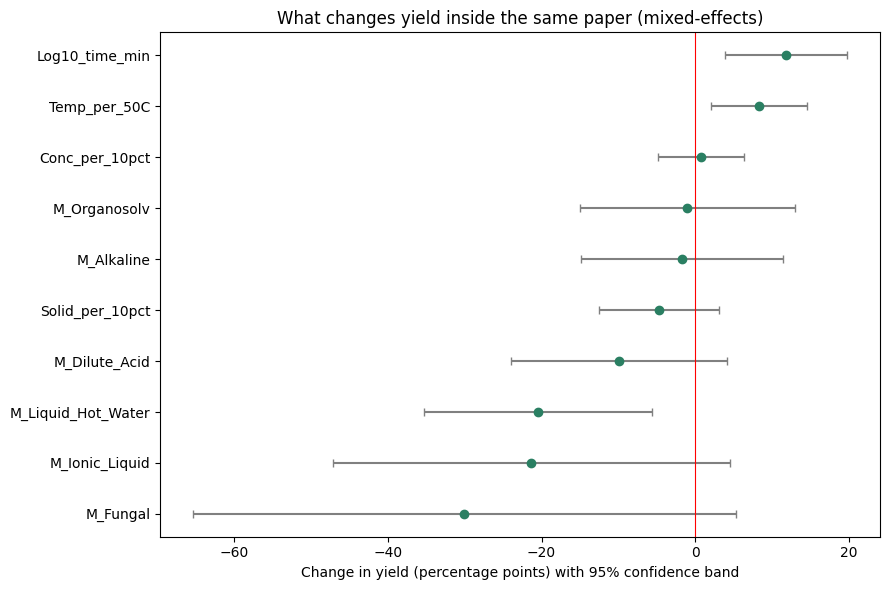


RUN: Cellulose Conversion % | mode: absolute
Rows: 253 | Papers: 48 | Biomass: 31 | Methods: 33
Target mean 62.6, SD 22.4

PREDICTORS
  [dropped] pH                                  13.8% filled
  [dropped] Energy_Proxy_Severity_Factor        15.8% filled
  categorical: ['Catalyst_Class', 'Biomass_Class', 'Pretreatment_Type']
  numeric    : ['Cellulose_wt_percent', 'Hemicellulose_wt_percent', 'Lignin_wt_percent', 'Moisture_wt_percent', 'Temperature_C', 'Pressure_MPa', 'Time_min', 'Solid_Loading_percent', 'Chemical_Concentration_percent', 'Lignin_Cellulose_ratio', 'Log_Time', 'M_Dilute_Acid', 'M_Alkaline', 'M_Organosolv', 'M_Deep_Eutectic_Solvent', 'M_Microwave', 'M_Liquid_Hot_Water', 'M_Steam_Explosion', 'M_Fungal', 'M_Ozonolysis', 'M_Ionic_Liquid', 'M_Ultrasound', 'M_Milling', 'M_Extrusion']

Validation: Paper-grouped, 5 folds x 3 repeats (48 groups)
Evaluating: Mean baseline
Evaluating: Ridge (glass-box)
Evaluating: Random Forest
Evaluating: Extra Trees
Evaluating: Gradient Boosting

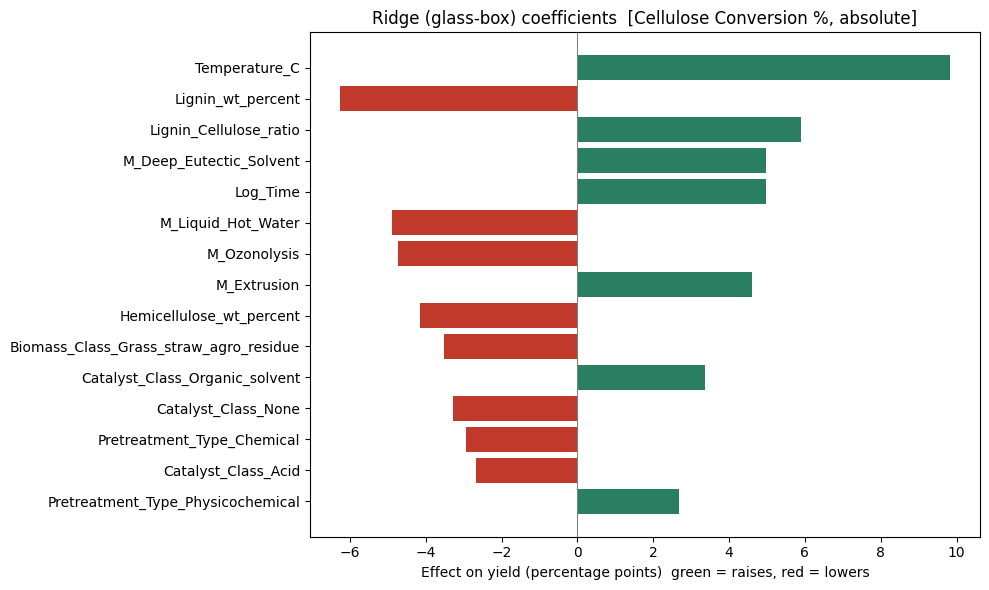

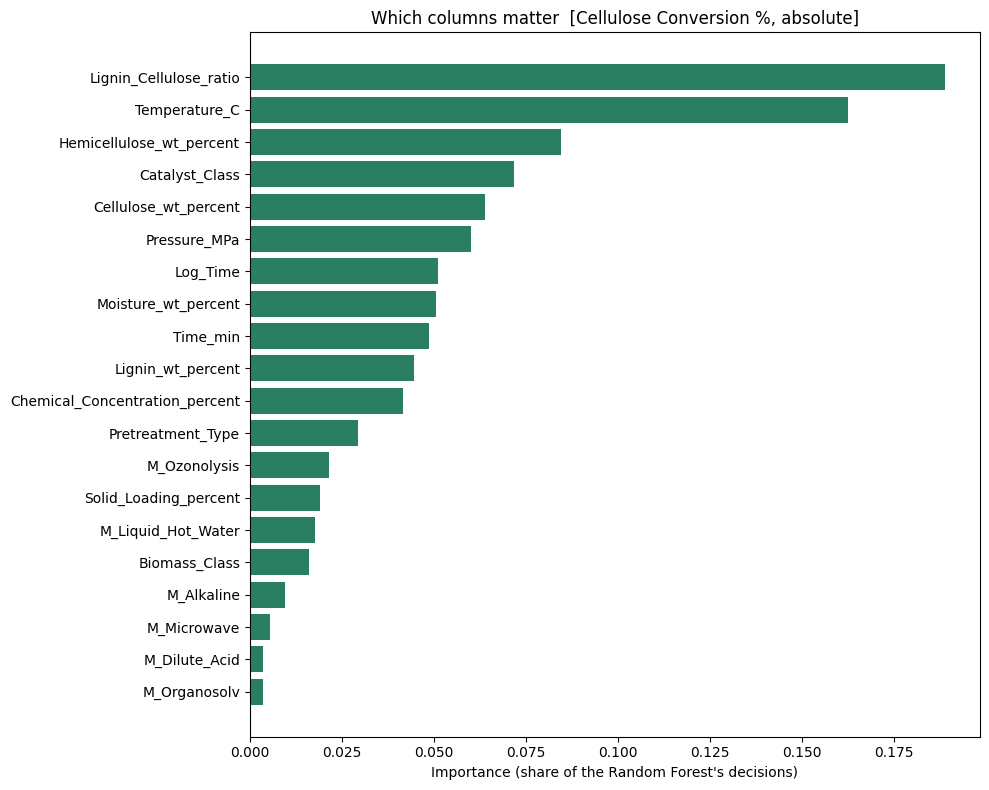


TOP COLUMNS: Lignin_Cellulose_ratio, Temperature_C, Hemicellulose_wt_percent, Catalyst_Class, Cellulose_wt_percent, Pressure_MPa, Log_Time, Moisture_wt_percent

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

RUN: Glucose Yield % | mode: absolute
Rows: 144 | Papers: 30 | Biomass: 19 | Methods: 19
Target mean 63.3, SD 23.1

PREDICTORS
  [dropped] pH                                   5.6% filled
  [dropped] Energy_Proxy_Severity_Factor        18.1% filled
  categorical: ['Catalyst_Class', 'Biomass_Class', 'Pretreatment_Type']
  numeric    : ['Cellulose_wt_percent', 'Hemicellulose_wt_percent', 'Lignin_wt_percent', 'Moisture_wt_percent', 'Temperature_C', 'Pressure_MPa', 'Time_min', 'Solid_Loading_percent', 'Chemical_Concentration_percent', 'Lignin_Cellulose_ratio', 'Log_Time', 'M_Dilute_Acid', 'M_Alkaline', 'M_Organosolv', 'M_Deep_Eutectic_Solvent', 'M_Microwave', 'M_Liquid_Hot_Water', 'M_Steam_Explosion', 'M_Fungal', 'M_Ozonolysis', 'M_Ionic_Liquid',

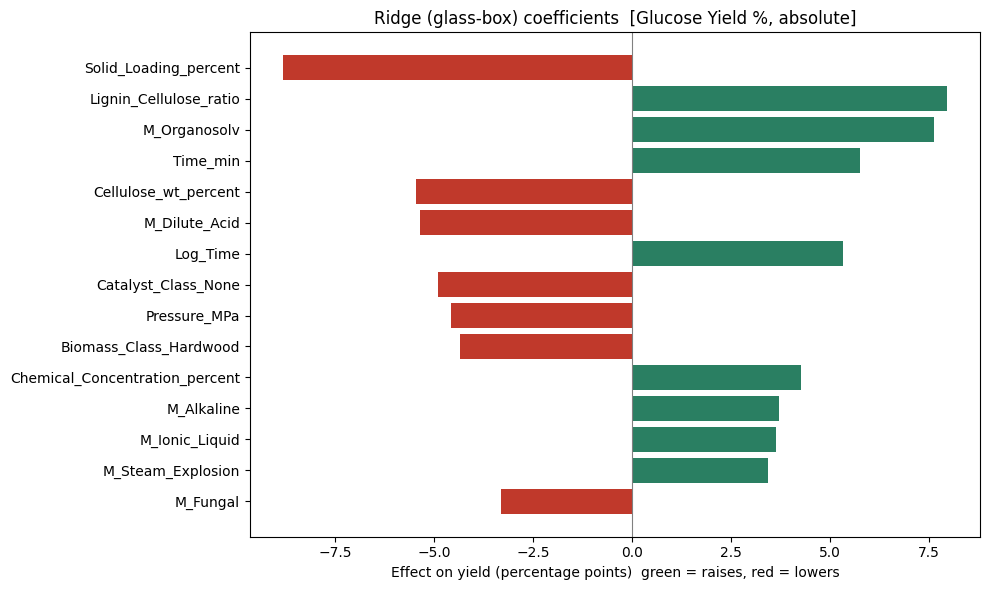

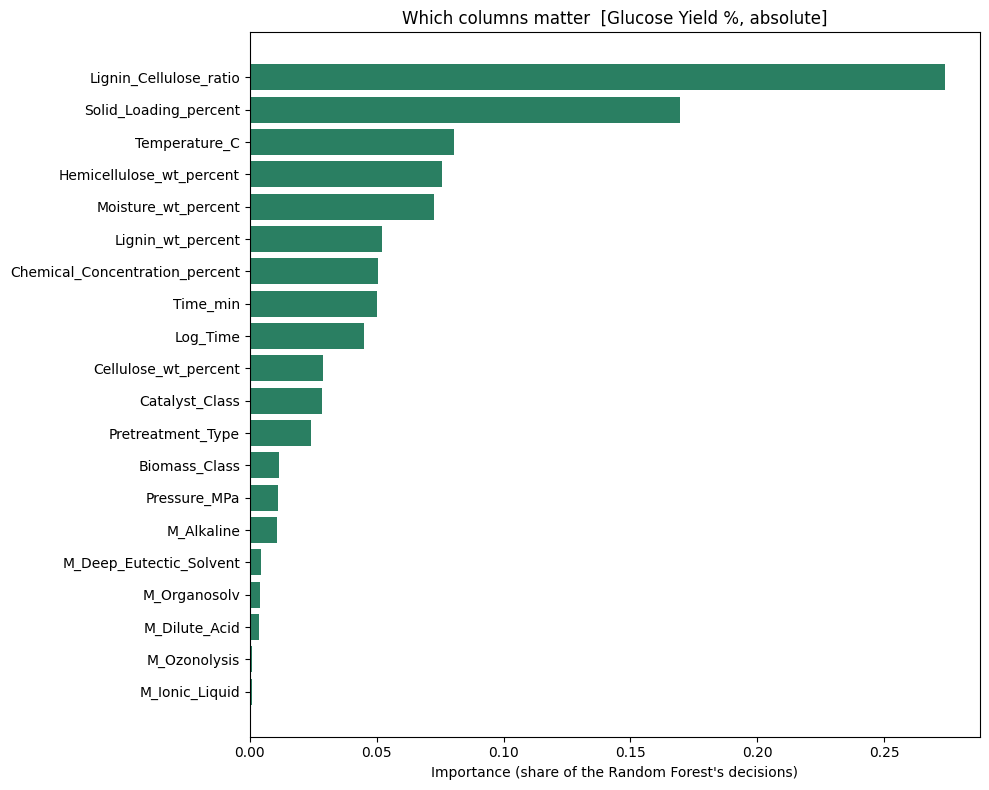


TOP COLUMNS: Lignin_Cellulose_ratio, Solid_Loading_percent, Temperature_C, Hemicellulose_wt_percent, Moisture_wt_percent, Lignin_wt_percent, Chemical_Concentration_percent, Time_min

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

RUN: Sugar Recovery % | mode: absolute
Rows: 147 | Papers: 32 | Biomass: 26 | Methods: 14
Target mean 55.9, SD 29.9

PREDICTORS
  [dropped] Pressure_MPa                        12.2% filled
  [dropped] pH                                  12.9% filled
  [dropped] Energy_Proxy_Severity_Factor         4.1% filled
  [dropped] M_Microwave                        100.0% filled  (constant)
  [dropped] M_Milling                          100.0% filled  (constant)
  categorical: ['Catalyst_Class', 'Biomass_Class', 'Pretreatment_Type']
  numeric    : ['Cellulose_wt_percent', 'Hemicellulose_wt_percent', 'Lignin_wt_percent', 'Moisture_wt_percent', 'Temperature_C', 'Time_min', 'Solid_Loading_percent', 'Chemical_Concentration_percent', '

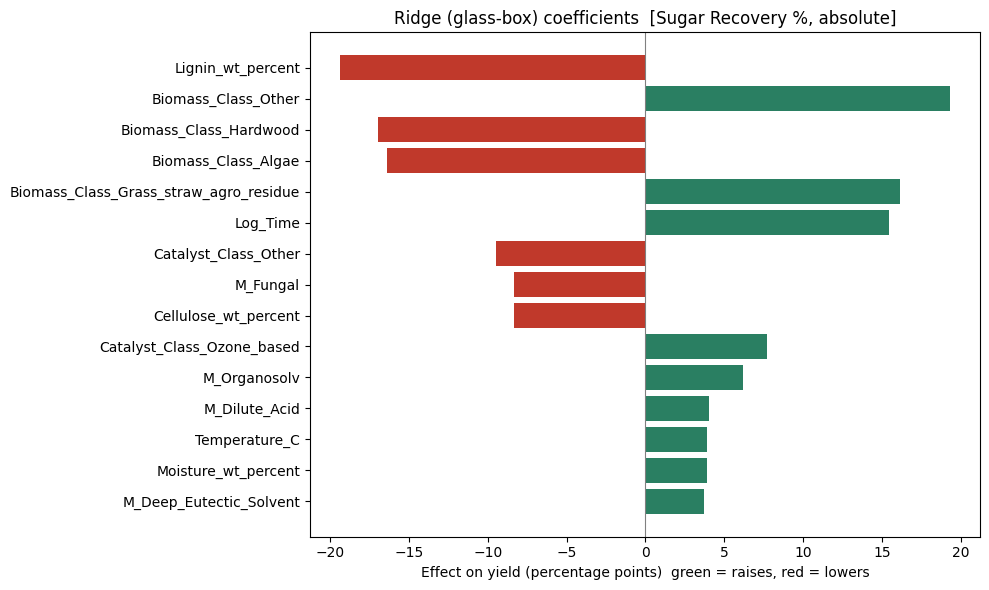

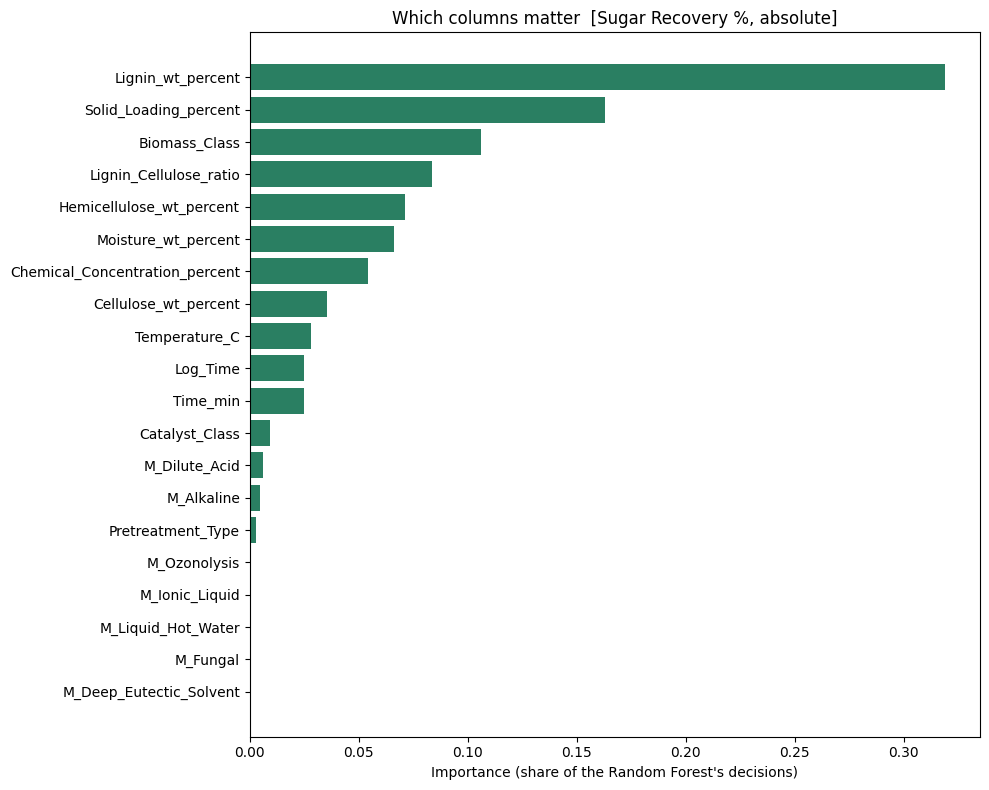


TOP COLUMNS: Lignin_wt_percent, Solid_Loading_percent, Biomass_Class, Lignin_Cellulose_ratio, Hemicellulose_wt_percent, Moisture_wt_percent, Chemical_Concentration_percent, Cellulose_wt_percent

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

RUN: POOLED | mode: absolute
Rows: 544 | Papers: 95 | Biomass: 51 | Methods: 40
Target mean 61.0, SD 25.0

PREDICTORS
  [dropped] pH                                  11.4% filled
  [dropped] Energy_Proxy_Severity_Factor        13.2% filled
  categorical: ['Catalyst_Class', 'Biomass_Class', 'Pretreatment_Type', 'Target_Yield_Type']
  numeric    : ['Cellulose_wt_percent', 'Hemicellulose_wt_percent', 'Lignin_wt_percent', 'Moisture_wt_percent', 'Temperature_C', 'Pressure_MPa', 'Time_min', 'Solid_Loading_percent', 'Chemical_Concentration_percent', 'Lignin_Cellulose_ratio', 'Log_Time', 'M_Dilute_Acid', 'M_Alkaline', 'M_Organosolv', 'M_Deep_Eutectic_Solvent', 'M_Microwave', 'M_Liquid_Hot_Water', 'M_Steam_Explosion',

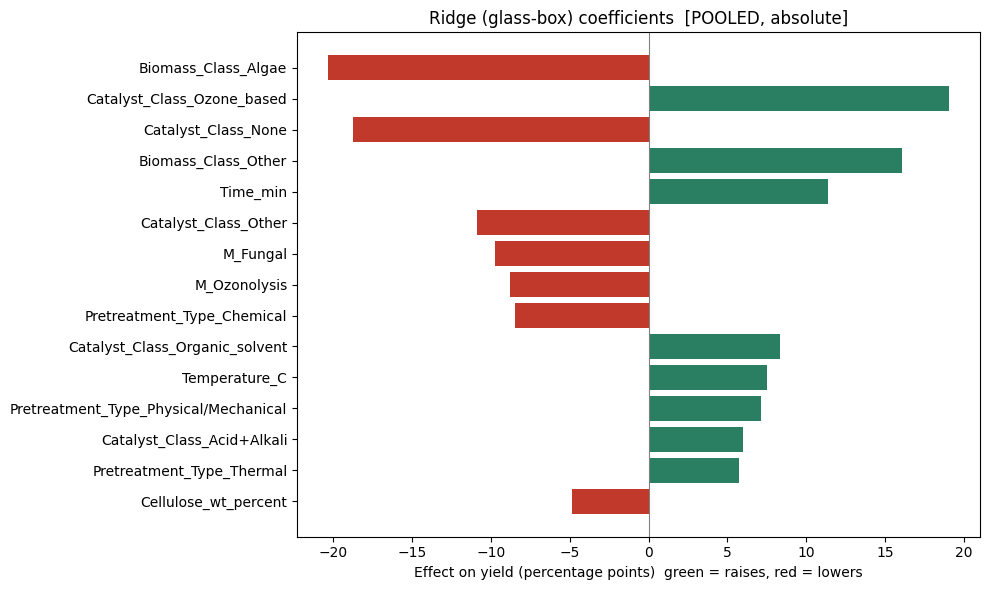

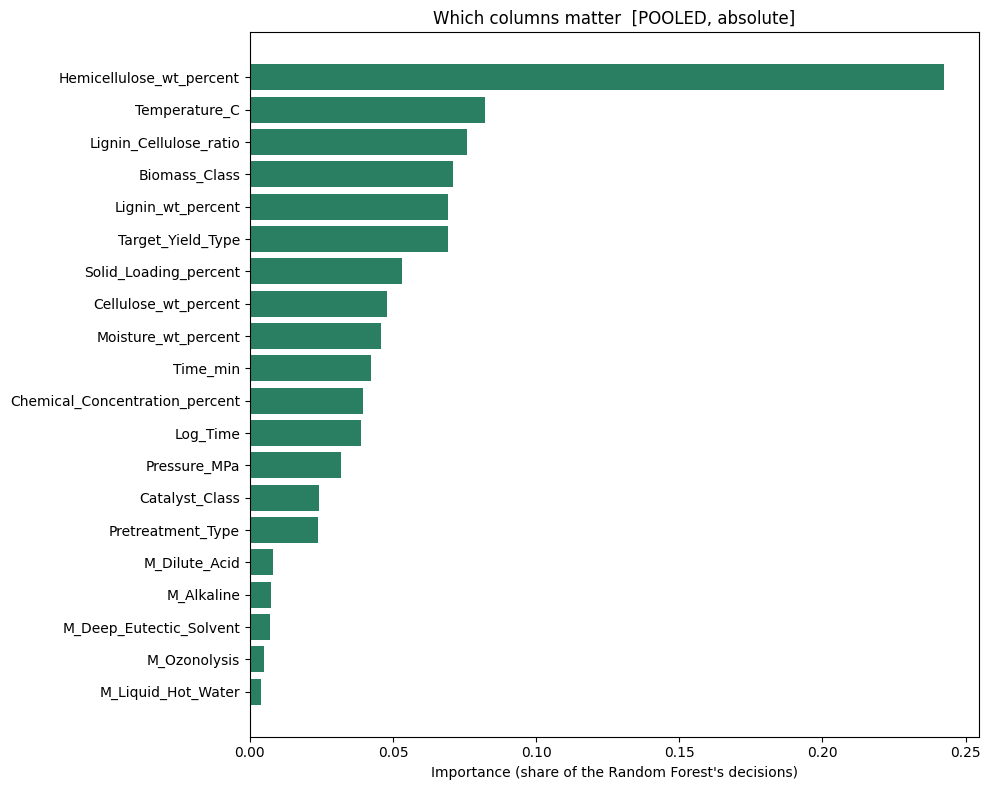


TOP COLUMNS: Hemicellulose_wt_percent, Temperature_C, Lignin_Cellulose_ratio, Biomass_Class, Lignin_wt_percent, Target_Yield_Type, Solid_Loading_percent, Cellulose_wt_percent

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

RUN: Cellulose Conversion % | mode: within_paper
WITHIN-PAPER mode: target = yield minus that paper's mean (only papers with >=2 rows). R2/RMSE refer to this deviation.
Rows: 238 | Papers: 33 | Biomass: 23 | Methods: 26
Target mean 0.0, SD 15.5

PREDICTORS
  [dropped] pH                                  13.9% filled
  [dropped] Energy_Proxy_Severity_Factor        15.5% filled
  categorical: ['Catalyst_Class', 'Biomass_Class', 'Pretreatment_Type']
  numeric    : ['Cellulose_wt_percent', 'Hemicellulose_wt_percent', 'Lignin_wt_percent', 'Moisture_wt_percent', 'Temperature_C', 'Pressure_MPa', 'Time_min', 'Solid_Loading_percent', 'Chemical_Concentration_percent', 'Lignin_Cellulose_ratio', 'Log_Time', 'M_Dilute_Acid', 'M_Alkaline', '

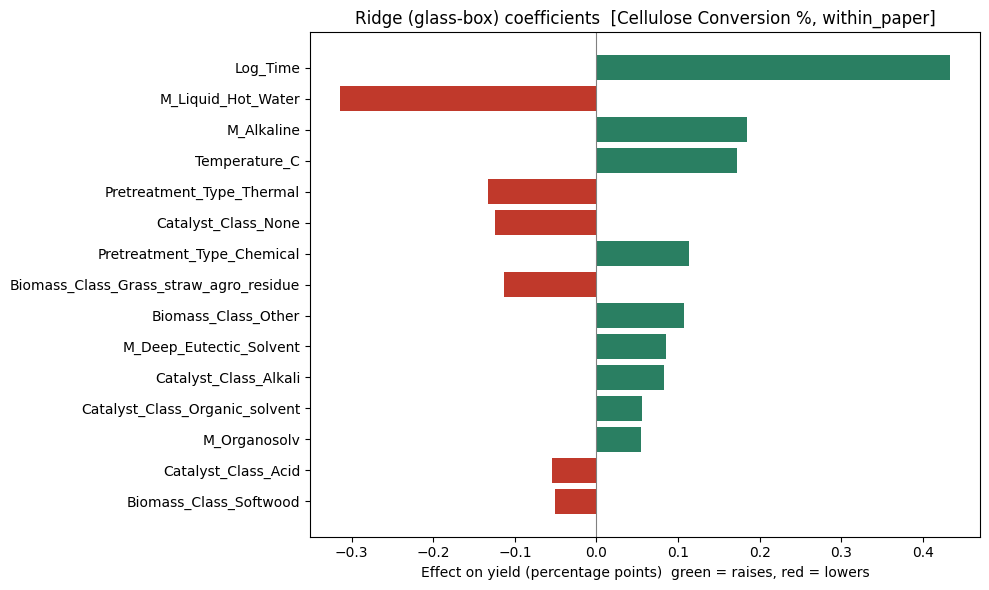

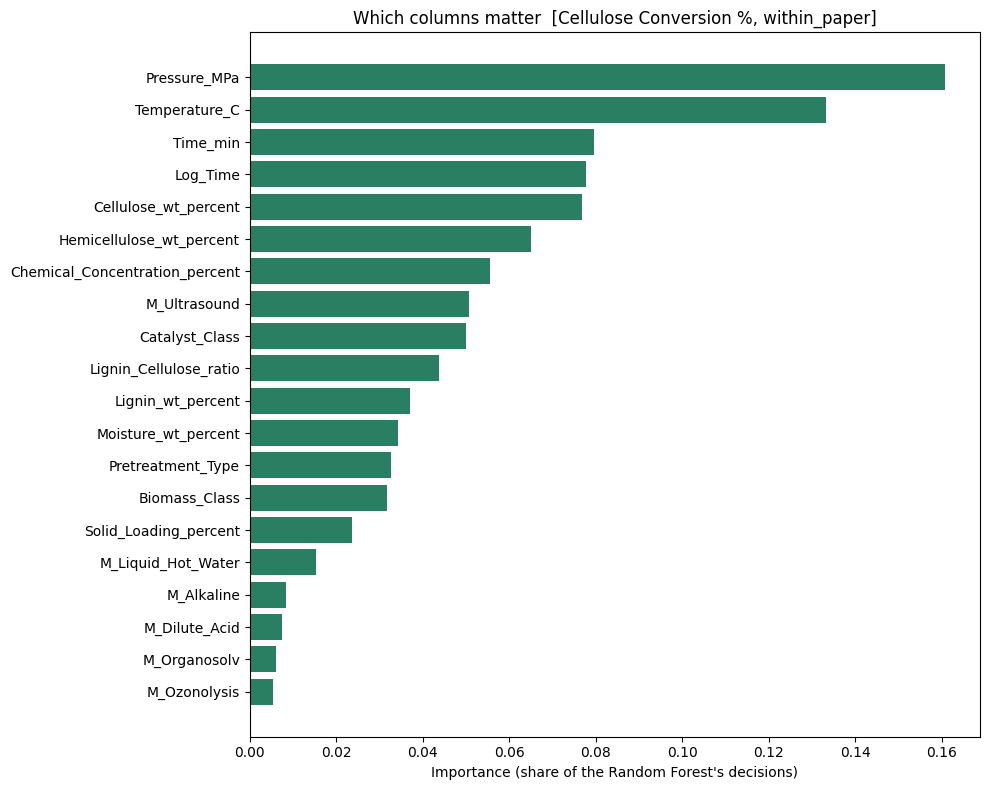


TOP COLUMNS: Pressure_MPa, Temperature_C, Time_min, Log_Time, Cellulose_wt_percent, Hemicellulose_wt_percent, Chemical_Concentration_percent, M_Ultrasound

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

RUN: Glucose Yield % | mode: within_paper
WITHIN-PAPER mode: target = yield minus that paper's mean (only papers with >=2 rows). R2/RMSE refer to this deviation.
Rows: 135 | Papers: 21 | Biomass: 16 | Methods: 15
Target mean -0.0, SD 14.2

PREDICTORS
  [dropped] pH                                   5.2% filled
  [dropped] Energy_Proxy_Severity_Factor        19.3% filled
  [dropped] M_Extrusion                        100.0% filled  (constant)
  categorical: ['Catalyst_Class', 'Biomass_Class', 'Pretreatment_Type']
  numeric    : ['Cellulose_wt_percent', 'Hemicellulose_wt_percent', 'Lignin_wt_percent', 'Moisture_wt_percent', 'Temperature_C', 'Pressure_MPa', 'Time_min', 'Solid_Loading_percent', 'Chemical_Concentration_percent', 'Lignin_Cellulose_ratio

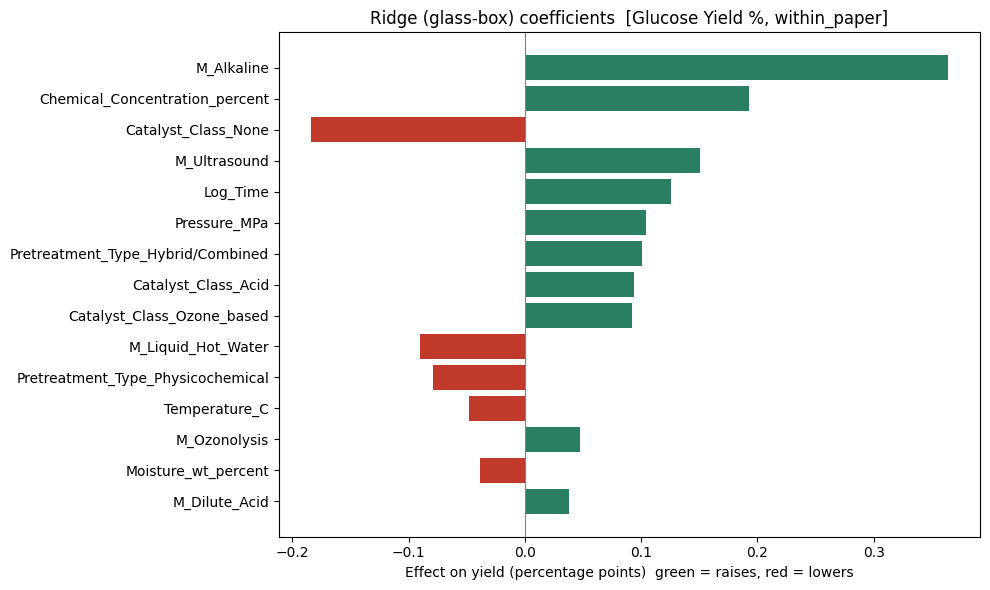

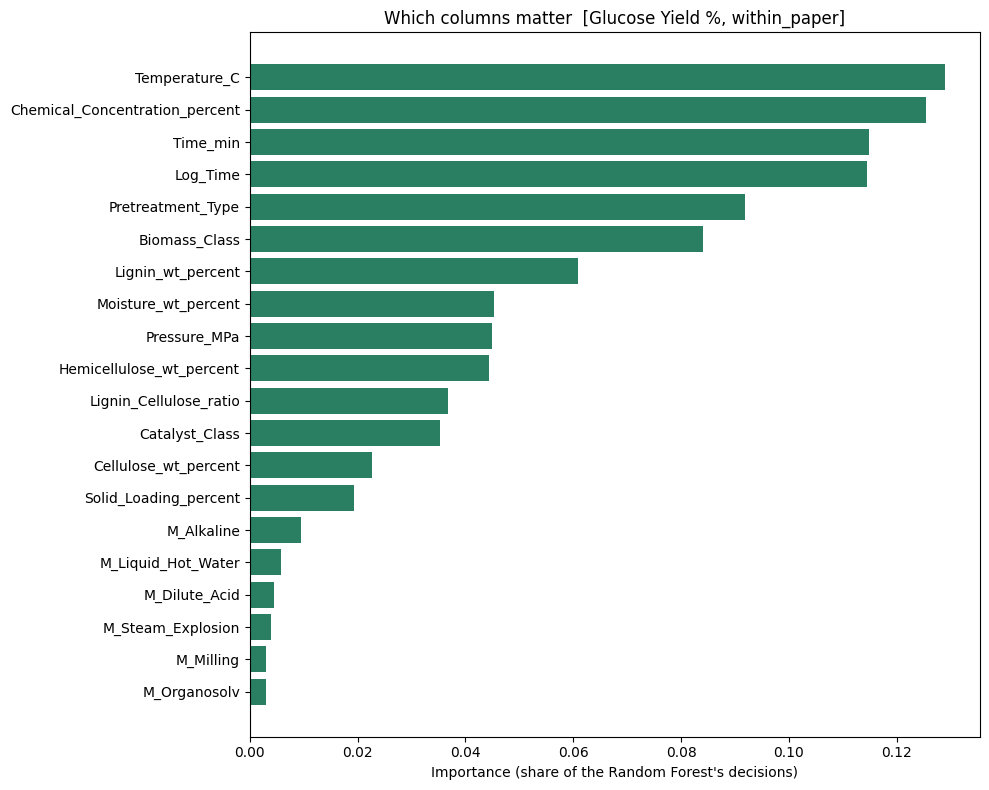


TOP COLUMNS: Temperature_C, Chemical_Concentration_percent, Time_min, Log_Time, Pretreatment_Type, Biomass_Class, Lignin_wt_percent, Moisture_wt_percent

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

RUN: Sugar Recovery % | mode: within_paper
WITHIN-PAPER mode: target = yield minus that paper's mean (only papers with >=2 rows). R2/RMSE refer to this deviation.
Rows: 136 | Papers: 21 | Biomass: 22 | Methods: 11
Target mean -0.0, SD 9.8

PREDICTORS
  [dropped] Pressure_MPa                        12.5% filled
  [dropped] pH                                  13.2% filled
  [dropped] Energy_Proxy_Severity_Factor         2.9% filled
  [dropped] M_Microwave                        100.0% filled  (constant)
  [dropped] M_Steam_Explosion                  100.0% filled  (constant)
  [dropped] M_Ultrasound                       100.0% filled  (constant)
  [dropped] M_Milling                          100.0% filled  (constant)
  [dropped] M_Extrusion          

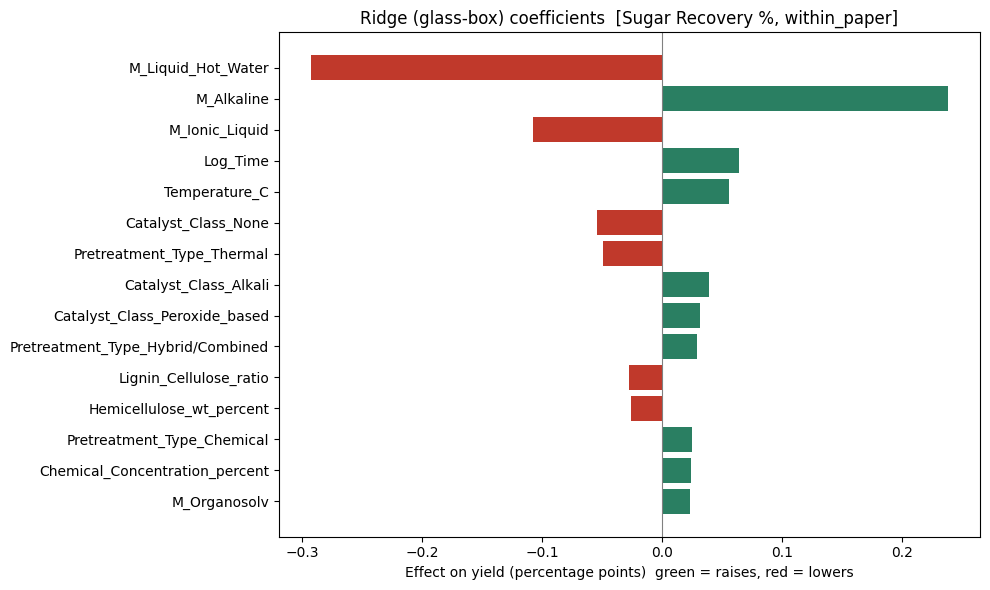

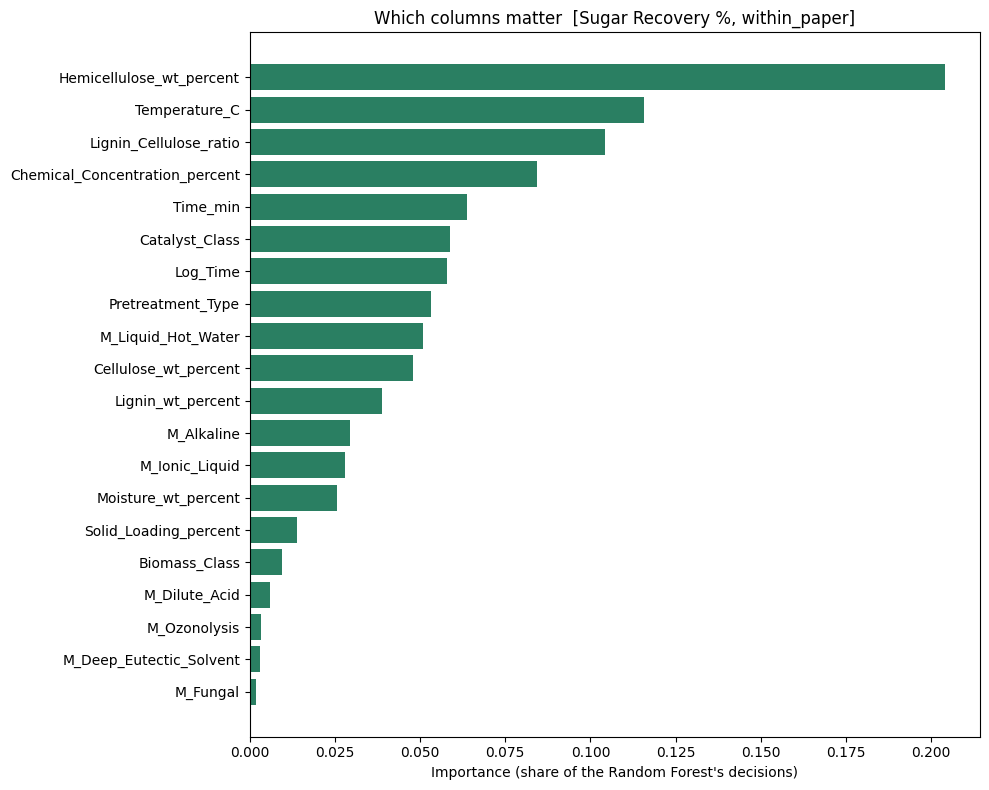


TOP COLUMNS: Hemicellulose_wt_percent, Temperature_C, Lignin_Cellulose_ratio, Chemical_Concentration_percent, Time_min, Catalyst_Class, Log_Time, Pretreatment_Type

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

RUN: POOLED | mode: within_paper
WITHIN-PAPER mode: target = yield minus that paper's mean (only papers with >=2 rows). R2/RMSE refer to this deviation.
Rows: 509 | Papers: 65 | Biomass: 41 | Methods: 33
Target mean -0.0, SD 13.8

PREDICTORS
  [dropped] pH                                  11.4% filled
  [dropped] Energy_Proxy_Severity_Factor        13.2% filled
  categorical: ['Catalyst_Class', 'Biomass_Class', 'Pretreatment_Type', 'Target_Yield_Type']
  numeric    : ['Cellulose_wt_percent', 'Hemicellulose_wt_percent', 'Lignin_wt_percent', 'Moisture_wt_percent', 'Temperature_C', 'Pressure_MPa', 'Time_min', 'Solid_Loading_percent', 'Chemical_Concentration_percent', 'Lignin_Cellulose_ratio', 'Log_Time', 'M_Dilute_Acid', 'M_Alkaline', 'M_Org

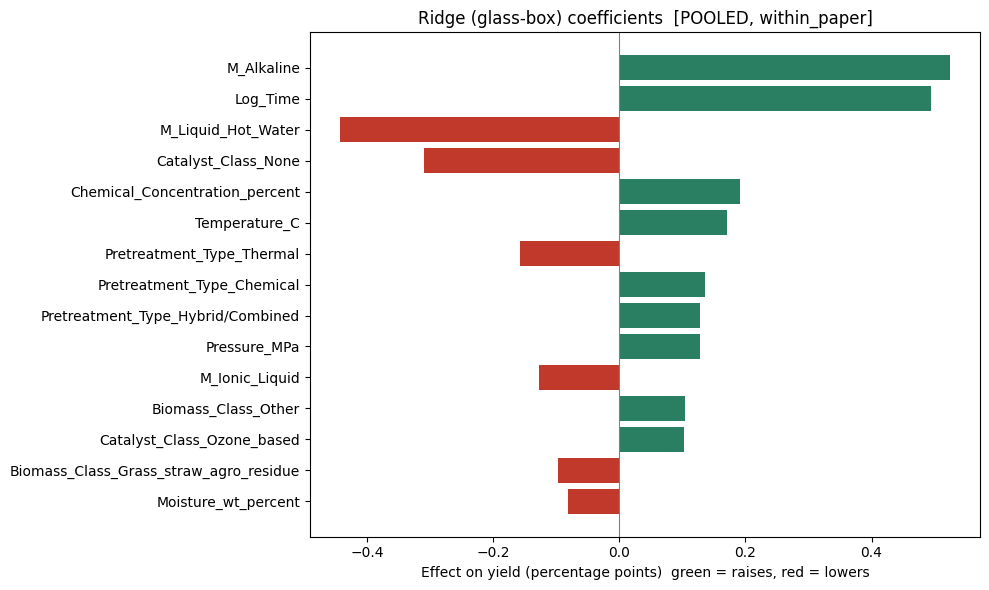

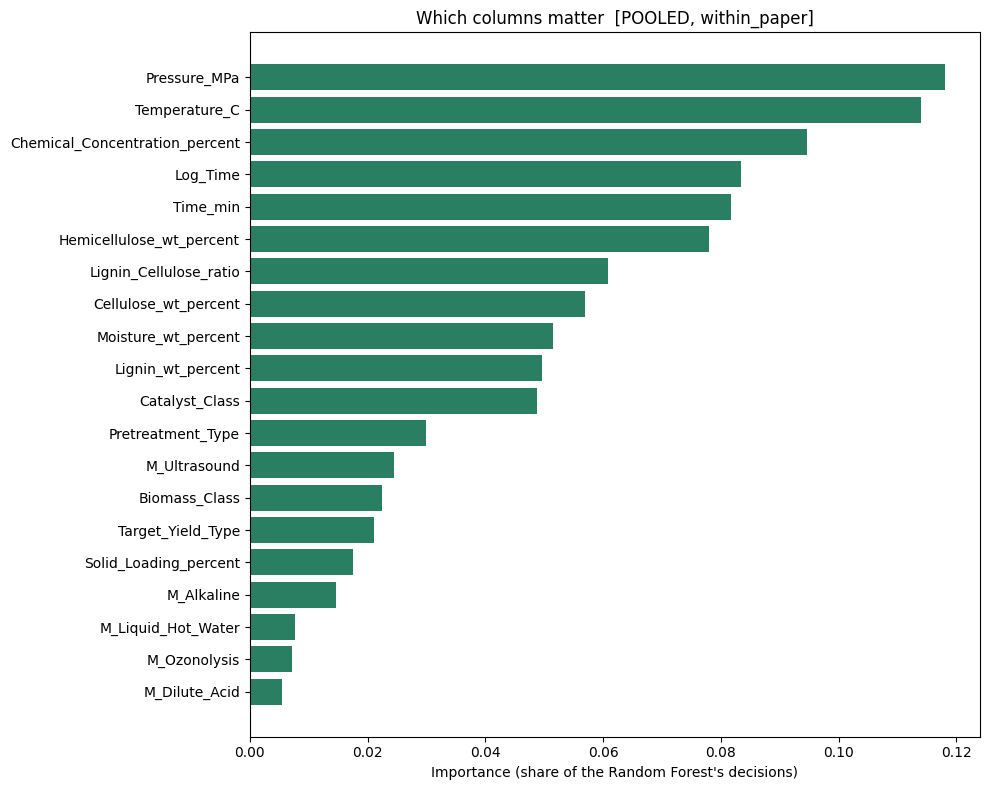


TOP COLUMNS: Pressure_MPa, Temperature_C, Chemical_Concentration_percent, Log_Time, Time_min, Hemicellulose_wt_percent, Lignin_Cellulose_ratio, Cellulose_wt_percent

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

SUMMARY OF ALL RUNS (paper-grouped validation)
                   Run         Mode  Rows  Papers        Best_model     R2   RMSE  Baseline_R2  Gain_vs_baseline
Cellulose Conversion %     absolute   253      48 Ridge (glass-box) -0.144 23.850       -0.046            -0.098
       Glucose Yield %     absolute   144      30     Random Forest -0.351 26.698       -0.060            -0.291
      Sugar Recovery %     absolute   147      32       Extra Trees -0.099 31.271       -0.217             0.118
                POOLED     absolute   544      95     Random Forest -0.143 26.652       -0.023            -0.120
Cellulose Conversion % within_paper   238      33     Random Forest -0.067 16.000        0.000            -0.067
       Glucose Yield %

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ================================================================
# BIOETHANOL / PRETREATMENT YIELD MODELLING  (v3)
# Pretreatment-focused targets | absolute + WITHIN-PAPER modes | glass-box plots
# ================================================================
# Paste into ONE Google Colab cell. Optional glass-box EBM:
#     !pip install interpret
# ================================================================
import re
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution
from sklearn.base import clone, BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor,
                              GradientBoostingRegressor,
                              HistGradientBoostingRegressor)
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
warnings.filterwarnings("ignore")

try:
    from interpret.glassbox import ExplainableBoostingRegressor
    HAS_EBM = True
except Exception:
    HAS_EBM = False
    print("NOTE: 'interpret' not installed -> EBM skipped. "
          "Run:  !pip install interpret")

# ---------------------------------------------------
# 1. CONFIGURATION
# ---------------------------------------------------
FILE_NAME = "/content/FINAL_DATASET_clean.csv"
SHEET_NAME = 0
TARGET = "Target_Yield_percent"
YIELD_TYPE_COLUMN = "Target_Yield_Type"
BIOMASS_COL, TYPE_COL, METHOD_COL = "Biomass_Type", "Pretreatment_Type", "Pretreatment_Method"
PAPER_COL = "Paper_ID"
SEVERITY_COL = "Energy_Proxy_Severity_Factor"

# Each entry = one modelling run. One yield type  -> separate model.
# Several yield types -> POOLED model (yield type becomes a feature).
# Pretreatment effectiveness is measured by cellulose conversion / glucose /
# sugar recovery (they depend directly on pretreatment). Ethanol yield also
# depends on enzymes and fermentation, so it is NOT run by default.
# To add it, append ["Ethanol Yield %"] to RUNS.
RUNS = [
    ["Cellulose Conversion %"],
    ["Glucose Yield %"],
    ["Sugar Recovery %"],
    ["Cellulose Conversion %", "Glucose Yield %", "Sugar Recovery %"],   # pooled
]
# "absolute"     : predict the yield itself (hard: labs differ a lot)
# "within_paper" : predict yield minus that paper's own average yield, i.e.
#                  "which conditions beat the other conditions in the SAME paper"
TARGET_MODES = ["absolute", "within_paper"]
ADD_MISSING_INDICATORS = False   # False = model cannot learn "which paper omitted X"
OPTIMIZABLE_YIELD_TYPES = ["Glucose Yield %", "Ethanol Yield %",
                           "Sugar Recovery %", "Cellulose Conversion %"]
DROP_OUT_OF_RANGE = True      # drop yields <0 or >100 (mixed units) before modelling
MIN_ROWS_PER_RUN = 30
RANDOM_STATE = 42
N_FOLDS = 5
N_REPEATS = 3                 # repeated paper-grouped CV (more stable than 1 run)
OPTIMIZE_MIN_R2 = 0.30        # optimise only if validated R2 reaches this
MIN_COMPLETENESS = 0.20
MIN_ROWS_PER_COMBINATION = 5
MIN_VALUES_FOR_OPTIMIZATION = 5
LOWER_PERCENTILE, UPPER_PERCENTILE = 5, 95
OPTIMIZER_MAXITER, OPTIMIZER_POPSIZE = 60, 10
MIN_ROWS_PER_FLAG = 5         # a method component needs this many rows to get a 0/1 flag

# Very high-cardinality one-hots hurt on small data. Biomass is replaced by
# Biomass_Class; the specific method is replaced by 0/1 component flags.
USE_BIOMASS_ONEHOT = False
USE_METHOD_ONEHOT = False
USE_TYPE_ONEHOT = True

CATEGORICAL_BASE = ["Catalyst_Class", "Biomass_Class"]
NUMERIC_BASE = ["Cellulose_wt_percent", "Hemicellulose_wt_percent",
                "Lignin_wt_percent", "Moisture_wt_percent",
                "Temperature_C", "Pressure_MPa", "Time_min",
                "Solid_Loading_percent", "Chemical_Concentration_percent",
                "pH", "Energy_Proxy_Severity_Factor",
                "Lignin_Cellulose_ratio", "Log_Time"]
RAW_NUMERIC = ["Cellulose_wt_percent", "Hemicellulose_wt_percent",
               "Lignin_wt_percent", "Moisture_wt_percent", "Temperature_C",
               "Pressure_MPa", "Time_min", "Solid_Loading_percent",
               "Chemical_Concentration_percent", "pH", SEVERITY_COL]
OPTIMIZABLE_COLUMNS = ["Temperature_C", "Time_min",
                       "Chemical_Concentration_percent", "Solid_Loading_percent"]
COMPOSITION_COLUMNS = ["Cellulose_wt_percent", "Hemicellulose_wt_percent",
                       "Lignin_wt_percent", "Moisture_wt_percent"]
SEVERITY_TYPES = ["Thermal", "Physicochemical"]
SEVERITY_TERMS = ["hydrothermal", "steam explosion", "steam treatment",
                  "liquid hot water", "hot water", "autohydrolysis"]

# Heuristic biomass classes - CHECK these against your biomass list.
BIOMASS_CLASS_RULES = [
    ("Algae", ["algae", "macroalgae", "microalgae", "seaweed", "azolla", "spirulina"]),
    ("Softwood", ["softwood", "pine", "spruce", "fir", "cedar"]),
    ("Hardwood", ["hardwood", "poplar", "eucalyptus", "birch", "willow", "oak", "beech"]),
    ("Fruit_shell_food_waste", ["peel", "fruit bunch", "shell", "pomace", "kitchen", "food waste"]),
    ("Grass_straw_agro_residue", ["straw", "stover", "bagasse", "grass", "stalk", "stillage",
                                  "spent grain", "bran", "husk", "sugarcane", "switchgrass",
                                  "miscanthus", "cob", "hull"]),
]

def slug(s):
    return re.sub(r"[^A-Za-z0-9]+", "_", str(s)).strip("_")

# ---------------------------------------------------
# 2. LOAD
# ---------------------------------------------------
def find_file():
    for c in [FILE_NAME, "/content/" + FILE_NAME, "/content/drive/MyDrive/" + FILE_NAME]:
        if Path(c).exists():
            return Path(c)
    try:
        from google.colab import files
        print("Dataset not found. Please upload it now...")
        return Path(list(files.upload().keys())[0])
    except ImportError:
        raise FileNotFoundError(f"Dataset not found: {FILE_NAME}")

def load_dataset():
    path = find_file()
    na = ["NaN", "nan", ""]
    if path.suffix.lower() == ".csv":
        try:
            df = pd.read_csv(path, na_values=na, keep_default_na=False, encoding="utf-8")
        except UnicodeDecodeError:
            print("!! UTF-8 failed, retrying with cp1252")
            df = pd.read_csv(path, na_values=na, keep_default_na=False, encoding="cp1252")
    else:
        df = pd.read_excel(path, sheet_name=SHEET_NAME, na_values=na, keep_default_na=False)
    df.columns = df.columns.astype(str).str.strip()
    print("Dataset shape:", df.shape)
    return df

# ---------------------------------------------------
# 3. GLOBAL CLEANING + FEATURE ENGINEERING (all yield types, ~all papers)
# ---------------------------------------------------
def severity_applicable(method, ptype):
    m = str(method).lower()
    return (str(ptype) in SEVERITY_TYPES and "+" not in m
            and any(t in m for t in SEVERITY_TERMS))

def sat_pressure_mpa(T):
    T = np.asarray(T, float)
    p = np.where(T < 100, 10 ** (8.07131 - 1730.63 / (233.426 + T)),
                 10 ** (8.14019 - 1810.94 / (244.485 + T)))
    return p * 0.000133322

def catalyst_class(name):
    """Group ~120 catalyst strings into a few chemistry classes."""
    n = str(name).lower().replace(" ", "")
    if n in ("none", "nan", "water", "h2o", ""):
        return "None"
    if any(k in n for k in ("choline", "chcl", "[", "ionic", "urea")):
        return "DES_or_IonicLiquid"
    acid = any(k in n for k in ("h2so4", "hcl", "hno3", "h3po4", "acid", "c2h2o4", "oxalic"))
    alk = any(k in n for k in ("naoh", "koh", "nh4oh", "ammonia", "ca(oh)2", "na2co3", "na2s", "nacs", "lime"))
    if acid and alk:
        return "Acid+Alkali"
    if "o3" in n:
        return "Ozone_based"
    if "h2o2" in n or "peroxide" in n:
        return "Peroxide_based"
    if acid:
        return "Acid"
    if alk:
        return "Alkali"
    if any(k in n for k in ("ethanol", "acetone", "glycerol", "methanol", "organosolv")):
        return "Organic_solvent"
    return "Other"

def biomass_class(name):
    n = str(name).lower()
    for cls, kws in BIOMASS_CLASS_RULES:
        for kw in kws:
            if re.search(r"\b" + re.escape(kw) + r"s?\b", n):
                return cls
    return "Other"

def add_derived(frame):
    if {"Lignin_wt_percent", "Cellulose_wt_percent"} <= set(frame.columns):
        c = frame["Cellulose_wt_percent"].where(frame["Cellulose_wt_percent"] > 0)
        frame["Lignin_Cellulose_ratio"] = frame["Lignin_wt_percent"] / c
    if "Time_min" in frame.columns:
        frame["Log_Time"] = np.log1p(frame["Time_min"].clip(lower=0))
    return frame

def clean_global(raw):
    df = raw.copy()
    required = [TARGET, YIELD_TYPE_COLUMN, BIOMASS_COL, TYPE_COL, METHOD_COL, PAPER_COL]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Required columns missing: {missing}")
    for c in df.columns:
        df[c] = df[c].apply(lambda x: x.strip() if isinstance(x, str) else x)
        df[c] = df[c].replace("", np.nan)
    # stray repeated header rows (your counts showed 'Target_Yield_Type': 1)
    n0 = len(df)
    df = df[(df[YIELD_TYPE_COLUMN] != YIELD_TYPE_COLUMN) & (df[PAPER_COL] != PAPER_COL)]
    if len(df) < n0:
        print(f"Removed {n0 - len(df)} stray header row(s) inside the data.")
    for c in RAW_NUMERIC + [TARGET]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.dropna(subset=[TARGET, BIOMASS_COL, TYPE_COL, METHOD_COL]).reset_index(drop=True)

    # composition: fill from the SAME biomass type (feature-only, no target used)
    for c in COMPOSITION_COLUMNS:
        if c in df.columns:
            df[c] = df[c].fillna(df.groupby(BIOMASS_COL)[c].transform("median"))
    # pressure from temperature for steam/hot-water methods (saturated steam)
    if "Pressure_MPa" in df.columns and "Temperature_C" in df.columns:
        steam = df[METHOD_COL].str.lower().apply(lambda m: any(t in m for t in SEVERITY_TERMS))
        mask = (df["Pressure_MPa"].isna() & df["Temperature_C"].ge(100)
                & steam & df[TYPE_COL].isin(SEVERITY_TYPES))
        df.loc[mask, "Pressure_MPa"] = sat_pressure_mpa(df.loc[mask, "Temperature_C"])
        print(f"Pressure filled from temperature for {int(mask.sum())} rows.")
    # severity log10(R0) for single thermal methods
    if SEVERITY_COL in df.columns:
        app = df.apply(lambda r: severity_applicable(r[METHOD_COL], r[TYPE_COL]), axis=1)
        mask = (df[SEVERITY_COL].isna() & app
                & df["Time_min"].notna() & df["Temperature_C"].notna())
        df.loc[mask, SEVERITY_COL] = np.log10(
            df.loc[mask, "Time_min"] * np.exp((df.loc[mask, "Temperature_C"] - 100) / 14.75))
        print(f"Severity factor computed for {int(mask.sum())} rows.")

    df = add_derived(df)
    df["Biomass_Class"] = df[BIOMASS_COL].apply(biomass_class)
    df["Catalyst_Class"] = df["Catalyst_Chemical"].apply(catalyst_class)
    print("Catalyst classes:", df["Catalyst_Class"].value_counts().to_dict())

    # multi-hot method components: "A + B" shares signal with "A" and "B"
    tokens = df[METHOD_COL].str.split("+").explode().str.strip()
    counts = tokens.value_counts()
    flag_cols = []
    for t, cnt in counts.items():
        if cnt >= MIN_ROWS_PER_FLAG and t.lower() != "none":
            col = "M_" + slug(t)
            df[col] = df[METHOD_COL].apply(
                lambda m, t=t: int(t in [x.strip() for x in str(m).split("+")]))
            flag_cols.append(col)
    print("Method component flags:", flag_cols)

    cov = (df.groupby(YIELD_TYPE_COLUMN)
             .agg(Rows=(TARGET, "size"), Papers=(PAPER_COL, "nunique"),
                  Biomass=(BIOMASS_COL, "nunique"))
             .sort_values("Papers", ascending=False))
    print("\nDATA COVERAGE PER YIELD TYPE")
    print(cov.to_string())
    print(f"TOTAL: {len(df)} rows, {df[PAPER_COL].nunique()} papers")
    print("Biomass classes:", df["Biomass_Class"].value_counts().to_dict())
    return df, flag_cols

def subset_for_run(clean, yield_types, mode="absolute"):
    df = clean[clean[YIELD_TYPE_COLUMN].isin(yield_types)].copy()
    odd = ((df[TARGET] < 0) | (df[TARGET] > 100)).sum()
    if odd:
        if DROP_OUT_OF_RANGE:
            df = df[(df[TARGET] >= 0) & (df[TARGET] <= 100)]
            print(f"!! Dropped {odd} rows with yield outside 0-100% (likely mixed units).")
        else:
            print(f"!! {odd} rows outside 0-100% kept.")
    df = df.reset_index(drop=True)
    if mode == "within_paper":
        grp = [PAPER_COL, YIELD_TYPE_COLUMN]
        df = df[df.groupby(grp)[TARGET].transform("size") >= 2].copy()
        df["Yield_abs"] = df[TARGET]
        df[TARGET] = df[TARGET] - df.groupby(grp)[TARGET].transform("mean")
        df = df.reset_index(drop=True)
        print("WITHIN-PAPER mode: target = yield minus that paper's mean "
              "(only papers with >=2 rows). R2/RMSE refer to this deviation.")
    if len(df) < MIN_ROWS_PER_RUN:
        raise ValueError(f"only {len(df)} usable rows")
    print(f"Rows: {len(df)} | Papers: {df[PAPER_COL].nunique()} | "
          f"Biomass: {df[BIOMASS_COL].nunique()} | Methods: {df[METHOD_COL].nunique()}")
    print(f"Target mean {df[TARGET].mean():.1f}, SD {df[TARGET].std():.1f}")
    return df

# ---------------------------------------------------
# 4. FEATURES + PIPELINES
# ---------------------------------------------------
def select_features(df, flag_cols, pooled):
    cat_cand = list(CATEGORICAL_BASE)
    if USE_BIOMASS_ONEHOT: cat_cand.append(BIOMASS_COL)
    if USE_TYPE_ONEHOT: cat_cand.append(TYPE_COL)
    if USE_METHOD_ONEHOT: cat_cand.append(METHOD_COL)
    if pooled: cat_cand.append(YIELD_TYPE_COLUMN)
    num_cand = NUMERIC_BASE + flag_cols
    categorical, numeric = [], []
    print("\nPREDICTORS")
    for col in cat_cand + num_cand:
        if col not in df.columns:
            continue
        frac = df[col].notna().mean()
        const = df[col].nunique(dropna=True) < 2
        keep = frac >= MIN_COMPLETENESS and not const
        if not keep:
            print(f"  [dropped] {col:<34s} {frac:6.1%} filled{'  (constant)' if const else ''}")
            continue
        (categorical if col in cat_cand else numeric).append(col)
    print("  categorical:", categorical)
    print("  numeric    :", numeric)
    return {"categorical": categorical, "numeric": numeric, "all": categorical + numeric}

class EBMRegressorWrapper(BaseEstimator, RegressorMixin):
    """sklearn-style wrapper: EBM handles NaN & categories natively."""
    def __init__(self, cat_cols=None, interactions=3, learning_rate=0.02,
                 max_bins=32, min_samples_leaf=5, outer_bags=4, random_state=42):
        self.cat_cols = cat_cols
        self.interactions = interactions
        self.learning_rate = learning_rate
        self.max_bins = max_bins
        self.min_samples_leaf = min_samples_leaf
        self.outer_bags = outer_bags
        self.random_state = random_state
    def _prep(self, X):
        X = X.copy()
        cats = list(self.cat_cols or [])
        for c in X.columns:
            if c in cats:
                X[c] = X[c].fillna("Unknown").astype(str)
            else:
                X[c] = pd.to_numeric(X[c], errors="coerce").astype(float)
        return X
    def fit(self, X, y):
        self.model_ = ExplainableBoostingRegressor(
            interactions=self.interactions, learning_rate=self.learning_rate,
            max_bins=self.max_bins, min_samples_leaf=self.min_samples_leaf,
            outer_bags=self.outer_bags, random_state=self.random_state)
        self.model_.fit(self._prep(X), np.asarray(y))
        return self
    def predict(self, X):
        return self.model_.predict(self._prep(X))

def make_pipeline(model, features):
    if isinstance(model, EBMRegressorWrapper):
        return model
    num = Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=ADD_MISSING_INDICATORS)),
                    ("scaler", StandardScaler())])
    cat = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
                    ("encoder", OneHotEncoder(handle_unknown="ignore"))])
    pre = ColumnTransformer([("numeric", num, features["numeric"]),
                             ("categorical", cat, features["categorical"])])
    return Pipeline([("preprocessor", pre), ("model", model)])

def get_models(features):
    m = {
        "Mean baseline": DummyRegressor(strategy="mean"),
        "Ridge (glass-box)": RidgeCV(alphas=np.logspace(-1, 3, 20)),
        "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                               random_state=RANDOM_STATE, n_jobs=-1),
        "Extra Trees": ExtraTreesRegressor(n_estimators=300, min_samples_leaf=3,
                                           random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.04,
                                                       max_depth=3, subsample=0.8,
                                                       random_state=RANDOM_STATE),
        "HistGradientBoosting": HistGradientBoostingRegressor(
            max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=10,
            l2_regularization=1.0, random_state=RANDOM_STATE),
    }
    if HAS_EBM:
        m["EBM (glass-box)"] = EBMRegressorWrapper(cat_cols=features["categorical"],
                                                   random_state=RANDOM_STATE)
    return m

# ---------------------------------------------------
# 5. REPEATED PAPER-GROUPED VALIDATION
# ---------------------------------------------------
def grouped_splits(groups, n_splits, seed):
    """Whole groups (papers) are held out; assignment reshuffled per seed."""
    uniq = np.unique(groups)
    rng = np.random.RandomState(seed)
    rng.shuffle(uniq)
    fold_of = {g: i % n_splits for i, g in enumerate(uniq)}
    f = np.array([fold_of[g] for g in groups])
    for k in range(n_splits):
        yield np.where(f != k)[0], np.where(f == k)[0]

def get_groups(df):
    if df[PAPER_COL].notna().all() and df[PAPER_COL].nunique() >= 3:
        return df[PAPER_COL].astype(str).to_numpy(), "Paper-grouped"
    print("WARNING: Paper_ID unusable; row-level CV. Scores will be OPTIMISTIC.")
    return np.arange(len(df)).astype(str), "Row-level"

def train_and_compare(df, features, prefix, clip=True):
    X, y = df[features["all"]], df[TARGET]
    groups, cv_name = get_groups(df)
    n_splits = min(N_FOLDS, len(np.unique(groups)))
    print(f"\nValidation: {cv_name}, {n_splits} folds x {N_REPEATS} repeats "
          f"({len(np.unique(groups))} groups)")
    rows, oof_store = [], {}
    for name, model in get_models(features).items():
        print("Evaluating:", name)
        try:
            r2s, rmses, maes, errs, last = [], [], [], [], None
            for r in range(N_REPEATS):
                pred = np.full(len(y), np.nan)
                for tr, te in grouped_splits(groups, n_splits, RANDOM_STATE + r):
                    fit = make_pipeline(clone(model), features).fit(X.iloc[tr], y.iloc[tr])
                    pred[te] = fit.predict(X.iloc[te])
                if clip:
                    pred = np.clip(pred, 0, 100)
                r2s.append(r2_score(y, pred))
                rmses.append(np.sqrt(mean_squared_error(y, pred)))
                maes.append(mean_absolute_error(y, pred))
                errs.append(np.abs(y.to_numpy() - pred))
                last = pred
        except Exception as exc:
            print(f"  skipped {name}: {exc}")
            continue
        oof_store[name] = np.concatenate(errs)
        rows.append({"Model": name, "Validation": cv_name,
                     "R2_mean": np.mean(r2s), "R2_SD_over_repeats": np.std(r2s),
                     "RMSE": np.mean(rmses), "MAE": np.mean(maes)})
    comp = pd.DataFrame(rows).sort_values(["R2_mean", "RMSE"], ascending=[False, True]).reset_index(drop=True)
    base_r2 = comp.loc[comp["Model"] == "Mean baseline", "R2_mean"].iloc[0]
    comp["R2_gain_vs_baseline"] = comp["R2_mean"] - base_r2
    comp.to_csv(f"{prefix}_model_comparison.csv", index=False)
    print("\nMODEL COMPARISON (out-of-fold, paper-grouped)")
    print(comp.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
    cand = comp[comp["Model"] != "Mean baseline"]
    best_name = cand.iloc[0]["Model"]
    best_r2, best_rmse = cand.iloc[0]["R2_mean"], cand.iloc[0]["RMSE"]
    if best_r2 <= base_r2 + 0.02:
        print("WARNING: no model clearly beats the mean baseline. Predictions are unreliable.")
    elif best_r2 < 0.3:
        print("WARNING: low validated R2. Treat results as exploratory.")
    half_width = float(np.percentile(oof_store[best_name], 90))
    print(f"Best: {best_name} | R2 {best_r2:.3f} | RMSE {best_rmse:.2f} | "
          f"90% of errors within +/- {half_width:.1f} points")
    validate_unseen_biomass(df, features, best_name, prefix, clip)
    fitted = make_pipeline(get_models(features)[best_name], features).fit(X, y)
    return best_name, fitted, half_width, best_r2, best_rmse, base_r2

def validate_unseen_biomass(df, features, model_name, prefix, clip=True):
    if df[BIOMASS_COL].nunique() < N_FOLDS:
        return
    X, y = df[features["all"]], df[TARGET]
    groups = df[BIOMASS_COL].astype(str).to_numpy()
    pred = np.full(len(y), np.nan)
    for tr, te in grouped_splits(groups, N_FOLDS, RANDOM_STATE):
        try:
            fit = make_pipeline(clone(get_models(features)[model_name]), features)
            fit.fit(X.iloc[tr], y.iloc[tr])
            pred[te] = np.clip(fit.predict(X.iloc[te]), 0, 100) if clip else fit.predict(X.iloc[te])
        except Exception as exc:
            print("Unseen-biomass fold failed:", exc)
    ok = ~np.isnan(pred)
    if ok.sum() >= 2:
        r2 = r2_score(y[ok], pred[ok])
        rmse = np.sqrt(mean_squared_error(y[ok], pred[ok]))
        print(f"Unseen-biomass transfer: R2 {r2:.3f} | RMSE {rmse:.2f}")
        pd.DataFrame([{"R2": r2, "RMSE": rmse, "Rows": int(ok.sum())}]).to_csv(
            f"{prefix}_unseen_biomass_validation.csv", index=False)

# ---------------------------------------------------
# 6. GLASS-BOX EXPLANATIONS
# ---------------------------------------------------
def explain_glassbox(df, features, prefix):
    X, y = df[features["all"]], df[TARGET]
    ridge = make_pipeline(RidgeCV(alphas=np.logspace(-1, 3, 20)), features).fit(X, y)
    names = ridge.named_steps["preprocessor"].get_feature_names_out()
    coef = pd.DataFrame({
        "Feature": [n.replace("numeric__", "").replace("categorical__", "") for n in names],
        "Coefficient": ridge.named_steps["model"].coef_})
    coef = coef.reindex(coef["Coefficient"].abs().sort_values(ascending=False).index)
    coef.to_csv(f"{prefix}_ridge_coefficients.csv", index=False)
    print("\nRIDGE: yield-% change per +1 SD (numeric) or per category (one-hot)")
    print(coef.head(15).to_string(index=False, float_format=lambda v: f"{v:+.2f}"))

    if HAS_EBM:
        try:
            w = EBMRegressorWrapper(cat_cols=features["categorical"],
                                    random_state=RANDOM_STATE).fit(X, y)
            expl = w.model_.explain_global()
            d = expl.data()
            imp = pd.DataFrame({"Term": d["names"], "Importance": d["scores"]}
                               ).sort_values("Importance", ascending=False)
            imp.to_csv(f"{prefix}_ebm_term_importance.csv", index=False)
            print("\nEBM TERM IMPORTANCE (top 12)")
            print(imp.head(12).to_string(index=False, float_format=lambda v: f"{v:.2f}"))
            top = imp.head(9)["Term"].tolist()
            fig, axes = plt.subplots(3, 3, figsize=(15, 11))
            for ax in axes.ravel():
                ax.axis("off")
            for ax, term in zip(axes.ravel(), top):
                ax.axis("on")
                sd = expl.data(d["names"].index(term))
                x, s = list(sd["names"]), list(sd["scores"])
                if sd.get("type") != "univariate":
                    ax.set_title(term + " (interaction)", fontsize=9)
                    continue
                if len(x) == len(s) + 1:
                    ax.step(x, s + [s[-1]], where="post")
                else:
                    ax.bar(range(len(x)), s)
                    ax.set_xticks(range(len(x)))
                    ax.set_xticklabels(x, rotation=60, ha="right", fontsize=7)
                ax.axhline(0, color="grey", lw=0.5)
                ax.set_title(term, fontsize=9)
                ax.set_ylabel("effect on yield (%)")
            plt.tight_layout()
            plt.savefig(f"{prefix}_ebm_shapes.png", dpi=200)
            plt.show()
        except Exception as exc:
            print("EBM explanation failed:", exc)

def plot_importance(df, features, prefix, title_suffix=""):
    """Bar-chart ('histogram style') of which COLUMNS matter, from a Random Forest.
    One-hot pieces are added back together, so 'Catalyst_Class' is one bar."""
    X, y = df[features["all"]], df[TARGET]
    rf = make_pipeline(RandomForestRegressor(n_estimators=500, min_samples_leaf=3,
                                             random_state=RANDOM_STATE, n_jobs=-1), features).fit(X, y)
    names = rf.named_steps["preprocessor"].get_feature_names_out()
    imp = rf.named_steps["model"].feature_importances_
    rows = {}
    for n, v in zip(names, imp):
        n = n.replace("numeric__", "").replace("categorical__", "")
        base = n
        for c in features["categorical"]:
            if n.startswith(c + "_"):
                base = c
                break
        if n.startswith("missingindicator_"):
            base = n.replace("missingindicator_", "") + " (missing flag)"
        rows[base] = rows.get(base, 0.0) + float(v)
    t = (pd.DataFrame({"Column": list(rows), "Importance": list(rows.values())})
           .sort_values("Importance", ascending=False).reset_index(drop=True))
    t.to_csv(f"{prefix}_column_importance.csv", index=False)
    top = t.head(20)
    plt.figure(figsize=(10, 8))
    plt.barh(top["Column"][::-1], top["Importance"][::-1], color="#2a7f62")
    plt.xlabel("Importance (share of the Random Forest's decisions)")
    plt.title(f"Which columns matter  {title_suffix}")
    plt.tight_layout()
    plt.savefig(f"{prefix}_feature_importance.png", dpi=200)
    plt.show()
    print("\nTOP COLUMNS:", ", ".join(top["Column"].head(8)))

def plot_ridge(prefix, title_suffix=""):
    try:
        c = pd.read_csv(f"{prefix}_ridge_coefficients.csv").head(15)
        plt.figure(figsize=(10, 6))
        plt.barh(c["Feature"][::-1], c["Coefficient"][::-1],
                 color=["#2a7f62" if v > 0 else "#c0392b" for v in c["Coefficient"][::-1]])
        plt.axvline(0, color="grey", lw=0.8)
        plt.xlabel("Effect on yield (percentage points)  green = raises, red = lowers")
        plt.title(f"Ridge (glass-box) coefficients  {title_suffix}")
        plt.tight_layout()
        plt.savefig(f"{prefix}_ridge_coefficients.png", dpi=200)
        plt.show()
    except Exception as exc:
        print("Ridge plot failed:", exc)

# ---------------------------------------------------
# 7. OPTIMISATION (single yield type, only if the model is validated)
# ---------------------------------------------------
def safe_median(s):
    v = pd.to_numeric(s, errors="coerce").dropna()
    return float(v.median()) if len(v) else np.nan

def safe_mode(s):
    v = s.dropna()
    return v.mode().iloc[0] if len(v) else np.nan

def get_bounds(series):
    v = pd.to_numeric(series, errors="coerce").dropna()
    v = v[np.isfinite(v)]
    if len(v) < MIN_VALUES_FOR_OPTIMIZATION or v.nunique() < MIN_VALUES_FOR_OPTIMIZATION:
        return None
    lo, hi = np.percentile(v, [LOWER_PERCENTILE, UPPER_PERCENTILE])
    return (float(lo), float(hi)) if np.isfinite(lo) and np.isfinite(hi) and hi > lo else None

def optimize_all_combinations(df, features, model, half_width, prefix):
    combos = df[[BIOMASS_COL, TYPE_COL, METHOD_COL]].drop_duplicates()
    print(f"\nOptimising {len(combos)} biomass x method combinations...")
    results = []
    for _, cid in combos.iterrows():
        biomass, ptype, method = cid[BIOMASS_COL], cid[TYPE_COL], cid[METHOD_COL]
        combo = df[(df[BIOMASS_COL] == biomass) & (df[TYPE_COL] == ptype) & (df[METHOD_COL] == method)]
        method_data = df[(df[TYPE_COL] == ptype) & (df[METHOD_COL] == method)]
        biomass_data = df[df[BIOMASS_COL] == biomass]
        n = len(combo)
        support = "ADEQUATE" if n >= MIN_ROWS_PER_COMBINATION else "LOW"
        baseline = {}
        for col in features["categorical"]:
            if col == BIOMASS_COL: baseline[col] = biomass
            elif col == TYPE_COL: baseline[col] = ptype
            elif col == METHOD_COL: baseline[col] = method
            else:
                v = safe_mode(combo[col])
                baseline[col] = v if pd.notna(v) else safe_mode(method_data[col])
        for col in features["numeric"]:
            if col in COMPOSITION_COLUMNS:
                baseline[col] = safe_median(biomass_data[col])
            else:
                v = safe_median(combo[col])
                baseline[col] = v if pd.notna(v) else safe_median(method_data[col])
        bounds_by_col, bsrc = {}, {}
        for col in OPTIMIZABLE_COLUMNS:
            if col not in features["numeric"]:
                continue
            b, src = get_bounds(combo[col]), "biomass-method"
            if b is None:
                b, src = get_bounds(method_data[col]), "method-level"
            if b is not None:
                bounds_by_col[col], bsrc[col] = b, src
        names = list(bounds_by_col)
        bounds = [bounds_by_col[c] for c in names]
        recompute_sev = (SEVERITY_COL in features["numeric"]
                         and severity_applicable(method, ptype)
                         and method_data[SEVERITY_COL].notna().mean() >= 0.5
                         and {"Time_min", "Temperature_C"} <= set(features["all"]))

        def make_frame(x, n_rows):
            frame = pd.DataFrame({c: [baseline[c]] * n_rows for c in features["all"]})
            for i, col in enumerate(names):
                frame[col] = x[i]
            for col in features["numeric"]:
                frame[col] = pd.to_numeric(frame[col], errors="coerce")
            if recompute_sev:
                with np.errstate(over="ignore", invalid="ignore"):
                    frame[SEVERITY_COL] = np.log10(
                        frame["Time_min"] * np.exp((frame["Temperature_C"] - 100) / 14.75))
            tmp = add_derived(frame.copy())
            for c in ("Lignin_Cellulose_ratio", "Log_Time"):
                if c in features["all"] and c in tmp.columns:
                    frame[c] = tmp[c]
            for col in features["categorical"]:
                frame[col] = frame[col].astype(object)
            return frame[features["all"]]

        def objective(x):
            x = np.asarray(x)
            if x.ndim == 1:
                x = x.reshape(-1, 1)
            return -np.clip(model.predict(make_frame(x, x.shape[1])), 0, 100)

        if names:
            try:
                res = differential_evolution(objective, bounds, seed=RANDOM_STATE,
                                             maxiter=OPTIMIZER_MAXITER, popsize=OPTIMIZER_POPSIZE,
                                             tol=1e-6, polish=False, vectorized=True,
                                             updating="deferred")
                best_x, predicted = np.asarray(res.x), float(-res.fun)
                status = "OPTIMIZED" if support == "ADEQUATE" else "OPTIMIZED_LOW_SUPPORT"
            except Exception as exc:
                print(f"Optimisation failed {biomass}/{method}: {exc}")
                best_x, predicted, status = np.array([]), np.nan, "OPTIMIZATION_FAILED"
        else:
            best_x = np.array([])
            predicted = float(np.clip(model.predict(make_frame(np.empty((0, 1)), 1))[0], 0, 100))
            status = "PREDICTION_ONLY_NO_SUPPORTED_RANGE"
        rec = {"Biomass_Type": biomass, "Pretreatment_Type": ptype, "Pretreatment_Method": method,
               "Observed_rows": n, "Support_status": support, "Optimization_status": status,
               "Predicted_Yield_percent": predicted,
               "Interval_low_90pct": max(0.0, predicted - half_width),
               "Interval_high_90pct": min(100.0, predicted + half_width),
               "Observed_max_yield": combo[TARGET].max(),
               "Observed_mean_yield": combo[TARGET].mean(),
               "Optimized_variables": "; ".join(names)}
        for col, val in zip(names, best_x):
            rec[f"Optimal_{col}"] = float(val)
            rec[f"Bounds_{col}"] = f"{bounds_by_col[col][0]:.4g} to {bounds_by_col[col][1]:.4g}"
        for col in features["numeric"]:
            if col not in names:
                rec[f"Held_{col}"] = baseline[col]
        results.append(rec)
    out = pd.DataFrame(results).sort_values([BIOMASS_COL, "Predicted_Yield_percent"],
                                            ascending=[True, False])
    out.to_csv(f"{prefix}_all_biomass_method_optimization.csv", index=False)
    picks = []
    for _, g in out.dropna(subset=["Predicted_Yield_percent"]).groupby(BIOMASS_COL):
        ad = g[g["Support_status"] == "ADEQUATE"]
        pool = ad if len(ad) else g
        row = pool.loc[pool["Predicted_Yield_percent"].idxmax()].copy()
        row["Chosen_from"] = "ADEQUATE" if len(ad) else "LOW-support only"
        picks.append(row)
    best = pd.DataFrame(picks)
    best.to_csv(f"{prefix}_best_method_per_biomass.csv", index=False)
    print(best[["Biomass_Type", "Pretreatment_Method", "Predicted_Yield_percent",
                "Interval_low_90pct", "Interval_high_90pct", "Observed_rows",
                "Chosen_from"]].to_string(index=False, float_format=lambda v: f"{v:.1f}"))

# ---------------------------------------------------
# 9. MIXED-EFFECTS (meta-analysis style) MODEL: the glass-box answer
# ---------------------------------------------------
def run_mixed_effects(clean, flag_cols):
    """yield ~ conditions + method flags + (random intercept per paper).
    The paper random effect absorbs lab-to-lab differences, so the coefficients
    show what changes yield INSIDE papers, with p-values and confidence bands.
    Needs:  pip install statsmodels   (preinstalled in Colab)"""
    try:
        import statsmodels.formula.api as smf
    except Exception:
        print("statsmodels not available -> mixed-effects model skipped.")
        return
    types = ["Cellulose Conversion %", "Glucose Yield %", "Sugar Recovery %"]
    d = clean[clean[YIELD_TYPE_COLUMN].isin(types)].copy()
    d = d[(d[TARGET] >= 0) & (d[TARGET] <= 100)]
    d["Temp_per_50C"] = (d["Temperature_C"] - 100) / 50
    d["Log10_time_min"] = np.log10(d["Time_min"].clip(lower=1))
    d["Conc_per_10pct"] = d["Chemical_Concentration_percent"].clip(upper=30) / 10
    d["Solid_per_10pct"] = d["Solid_Loading_percent"] / 10
    d["ytype"] = d[YIELD_TYPE_COLUMN]
    use = ["Temp_per_50C", "Log10_time_min", "Conc_per_10pct", "Solid_per_10pct"]
    d = d.dropna(subset=use + [TARGET, PAPER_COL])
    flags = [f for f in flag_cols if d[f].sum() >= 15 and (len(d) - d[f].sum()) >= 15]
    formula = TARGET + " ~ " + " + ".join(use + flags) + " + C(ytype)"
    try:
        res = smf.mixedlm(formula, d, groups=d[PAPER_COL]).fit(reml=True)
    except Exception as exc:
        print("Mixed model failed:", exc)
        return
    ci = res.conf_int()
    t = pd.DataFrame({"Effect_on_yield_points": res.params, "Low95": ci[0],
                      "High95": ci[1], "p_value": res.pvalues})
    t = t.drop(index=[i for i in t.index if i in ("Group Var", "Intercept")], errors="ignore")
    t.to_csv("mixed_effects_coefficients.csv")
    share = res.cov_re.iloc[0, 0] / (res.cov_re.iloc[0, 0] + res.scale)
    print("\n" + "=" * 70 + "\nMIXED-EFFECTS MODEL (paper = random effect)\n" + "=" * 70)
    print(f"{len(d)} rows, {d[PAPER_COL].nunique()} papers. "
          f"{share:.0%} of yield variance is between-paper (lab) differences.")
    print("Units: Temp per +50 C | Log10_time per x10 time | Conc per +10 % | "
          "Solid per +10 % | M_* = method used vs not used")
    print(t.round(3).to_string())
    print("p < 0.05 = effect is statistically reliable inside papers.")
    tt = t[~t.index.str.startswith("C(ytype)")].sort_values("Effect_on_yield_points")
    plt.figure(figsize=(9, 6))
    ypos = np.arange(len(tt))
    plt.errorbar(tt["Effect_on_yield_points"], ypos,
                 xerr=[tt["Effect_on_yield_points"] - tt["Low95"],
                       tt["High95"] - tt["Effect_on_yield_points"]],
                 fmt="o", color="#2a7f62", ecolor="grey", capsize=3)
    plt.yticks(ypos, tt.index)
    plt.axvline(0, color="red", lw=0.8)
    plt.xlabel("Change in yield (percentage points) with 95% confidence band")
    plt.title("What changes yield inside the same paper (mixed-effects)")
    plt.tight_layout()
    plt.savefig("mixed_effects_effects.png", dpi=200)
    plt.show()

# ---------------------------------------------------
# 10. MAIN
# ---------------------------------------------------
def main():
    raw = load_dataset()
    clean, flag_cols = clean_global(raw)
    run_mixed_effects(clean, flag_cols)
    summary = []
    for mode in TARGET_MODES:
        for yield_types in RUNS:
            pooled = len(yield_types) > 1
            label = "POOLED" if pooled else yield_types[0]
            prefix = f"{slug(label)}_{mode}"
            print("\n" + "=" * 70 + f"\nRUN: {label} | mode: {mode}\n" + "=" * 70)
            try:
                df = subset_for_run(clean, yield_types, mode)
                features = select_features(df, flag_cols, pooled)
                name, model, hw, r2, rmse, base = train_and_compare(
                    df, features, prefix, clip=(mode == "absolute"))
            except Exception as exc:
                print(f"RUN SKIPPED ({label}, {mode}): {exc}")
                continue
            explain_glassbox(df, features, prefix)
            plot_ridge(prefix, f"[{label}, {mode}]")
            plot_importance(df, features, prefix, f"[{label}, {mode}]")
            if (mode == "absolute" and not pooled
                    and yield_types[0] in OPTIMIZABLE_YIELD_TYPES and r2 >= OPTIMIZE_MIN_R2):
                optimize_all_combinations(df, features, model, hw, prefix)
            else:
                print("\nOptimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= "
                      f"{OPTIMIZE_MIN_R2}).")
            summary.append({"Run": label, "Mode": mode, "Rows": len(df),
                            "Papers": df[PAPER_COL].nunique(), "Best_model": name,
                            "R2": r2, "RMSE": rmse, "Baseline_R2": base,
                            "Gain_vs_baseline": r2 - base})
    if summary:
        s_ = pd.DataFrame(summary)
        s_.to_csv("summary_all_runs.csv", index=False)
        print("\n" + "=" * 70 + "\nSUMMARY OF ALL RUNS (paper-grouped validation)\n" + "=" * 70)
        print(s_.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
    try:
        from google.colab import files
        for f in list(Path(".").glob("*.csv")) + list(Path(".").glob("*.png")):
            files.download(str(f))
    except Exception:
        pass

if __name__ == "__main__":
    main()

NOTE: 'interpret' not installed -> EBM skipped. Run:  !pip install interpret
Dataset shape: (1150, 16)
Catalyst classes: {'Acid': 383, 'Alkali': 201, 'None': 190, 'DES_or_IonicLiquid': 184, 'Ozone_based': 77, 'Acid+Alkali': 19, 'Other': 19, 'Peroxide_based': 14, 'Organic_solvent': 13}
Method component flags: ['M_Dilute_Acid', 'M_Alkaline', 'M_Organosolv', 'M_Deep_Eutectic_Solvent', 'M_Liquid_Hot_Water', 'M_Microwave', 'M_Steam_Explosion', 'M_Ozonolysis', 'M_Fungal', 'M_Ionic_Liquid', 'M_Ultrasound', 'M_Milling', 'M_Extrusion']

DATA COVERAGE PER YIELD TYPE
                             Rows  Papers  Biomass
Target_Yield_Type                                 
Cellulose Conversion %        251      45       31
Lignin Removal %              321      33       28
Sugar Recovery %              164      31       23
Glucose Yield %               160      30       18
Ethanol Yield %               129      28       22
Solid Recovery %               68      11        9
Theoretical Ethanol Yield %  

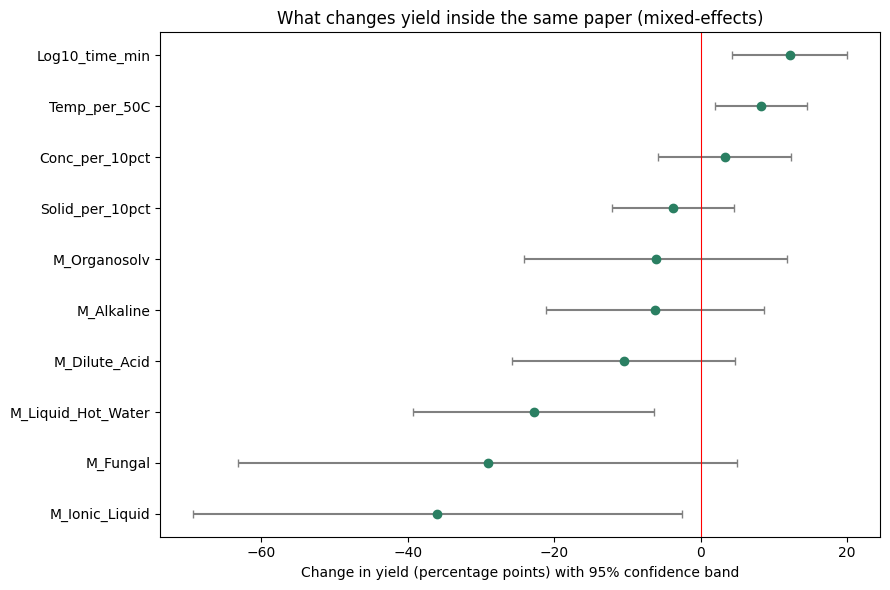


RUN: Cellulose Conversion % | mode: absolute
Rows: 251 | Papers: 45 | Biomass: 31 | Methods: 32
Target mean 61.3, SD 23.2

PREDICTORS
  [dropped] pH                                  16.3% filled
  [dropped] M_Milling                          100.0% filled  (constant)
  categorical: ['Catalyst_Class', 'Biomass_Class', 'Pretreatment_Type']
  numeric    : ['Cellulose_wt_percent', 'Hemicellulose_wt_percent', 'Lignin_wt_percent', 'Temperature_C', 'Time_min', 'Solid_Loading_percent', 'Chemical_Concentration_percent', 'Lignin_Cellulose_ratio', 'Log_Time', 'M_Dilute_Acid', 'M_Alkaline', 'M_Organosolv', 'M_Deep_Eutectic_Solvent', 'M_Liquid_Hot_Water', 'M_Microwave', 'M_Steam_Explosion', 'M_Ozonolysis', 'M_Fungal', 'M_Ionic_Liquid', 'M_Ultrasound', 'M_Extrusion']

Validation: Paper-grouped, 5 folds x 3 repeats (45 groups)
Evaluating: Mean baseline
Evaluating: Ridge (glass-box)
Evaluating: Random Forest
Evaluating: Extra Trees
Evaluating: Gradient Boosting
Evaluating: HistGradientBoosting

MODEL

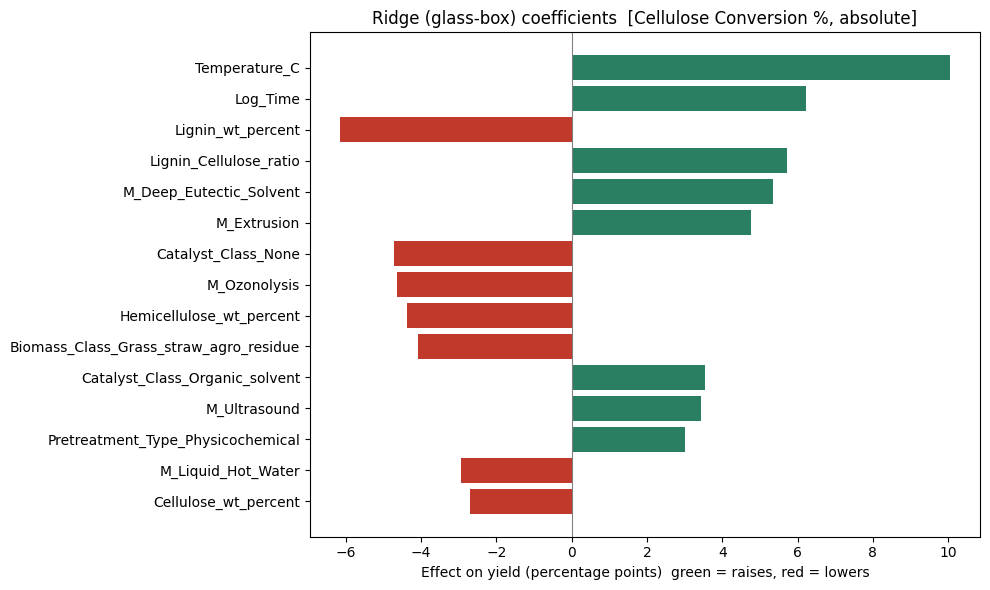

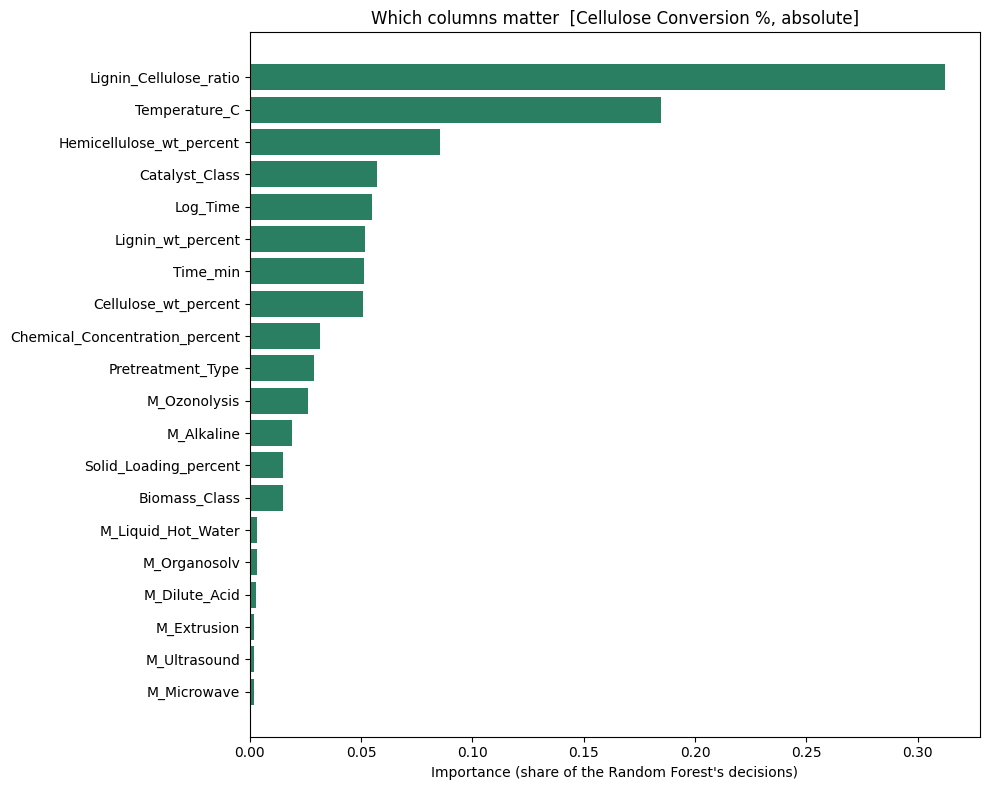


TOP COLUMNS: Lignin_Cellulose_ratio, Temperature_C, Hemicellulose_wt_percent, Catalyst_Class, Log_Time, Lignin_wt_percent, Time_min, Cellulose_wt_percent

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

RUN: Glucose Yield % | mode: absolute
Rows: 160 | Papers: 30 | Biomass: 18 | Methods: 24
Target mean 63.9, SD 22.5

PREDICTORS
  [dropped] pH                                   5.6% filled
  categorical: ['Catalyst_Class', 'Biomass_Class', 'Pretreatment_Type']
  numeric    : ['Cellulose_wt_percent', 'Hemicellulose_wt_percent', 'Lignin_wt_percent', 'Temperature_C', 'Time_min', 'Solid_Loading_percent', 'Chemical_Concentration_percent', 'Lignin_Cellulose_ratio', 'Log_Time', 'M_Dilute_Acid', 'M_Alkaline', 'M_Organosolv', 'M_Deep_Eutectic_Solvent', 'M_Liquid_Hot_Water', 'M_Microwave', 'M_Steam_Explosion', 'M_Ozonolysis', 'M_Fungal', 'M_Ionic_Liquid', 'M_Ultrasound', 'M_Milling', 'M_Extrusion']

Validation: Paper-grouped, 5 folds x 3 repeats (30 groups)
E

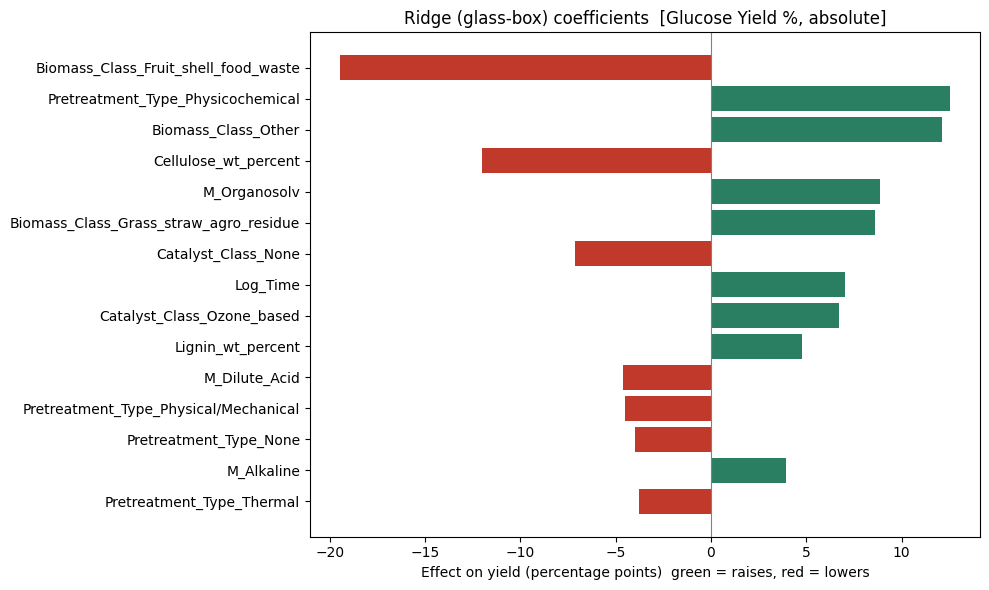

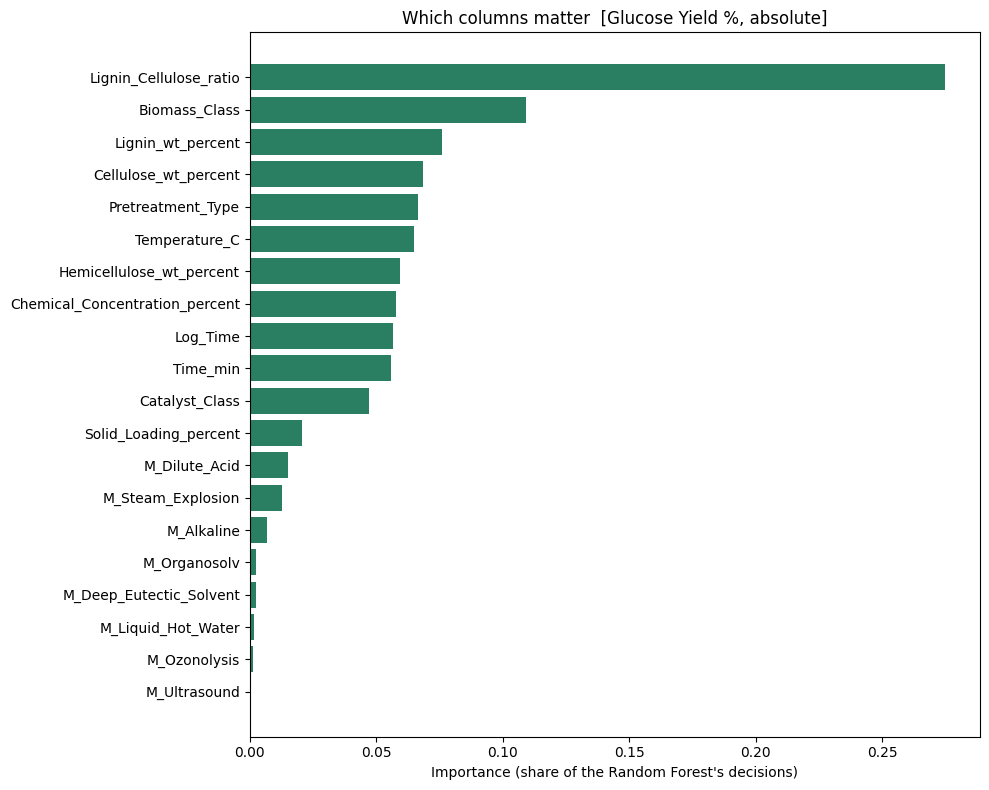


TOP COLUMNS: Lignin_Cellulose_ratio, Biomass_Class, Lignin_wt_percent, Cellulose_wt_percent, Pretreatment_Type, Temperature_C, Hemicellulose_wt_percent, Chemical_Concentration_percent

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

RUN: Sugar Recovery % | mode: absolute
!! Dropped 10 rows with yield outside 0-100% (likely mixed units).
Rows: 154 | Papers: 30 | Biomass: 22 | Methods: 17
Target mean 56.5, SD 30.0

PREDICTORS
  [dropped] pH                                  13.0% filled
  [dropped] M_Microwave                        100.0% filled  (constant)
  [dropped] M_Milling                          100.0% filled  (constant)
  categorical: ['Catalyst_Class', 'Biomass_Class', 'Pretreatment_Type']
  numeric    : ['Cellulose_wt_percent', 'Hemicellulose_wt_percent', 'Lignin_wt_percent', 'Temperature_C', 'Time_min', 'Solid_Loading_percent', 'Chemical_Concentration_percent', 'Lignin_Cellulose_ratio', 'Log_Time', 'M_Dilute_Acid', 'M_Alkaline', 'M_Organ

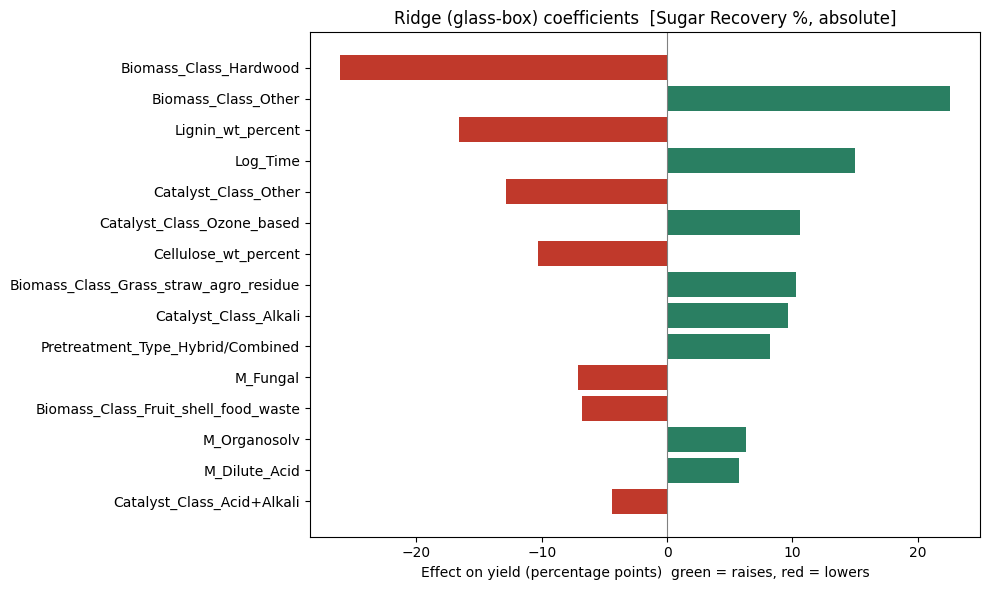

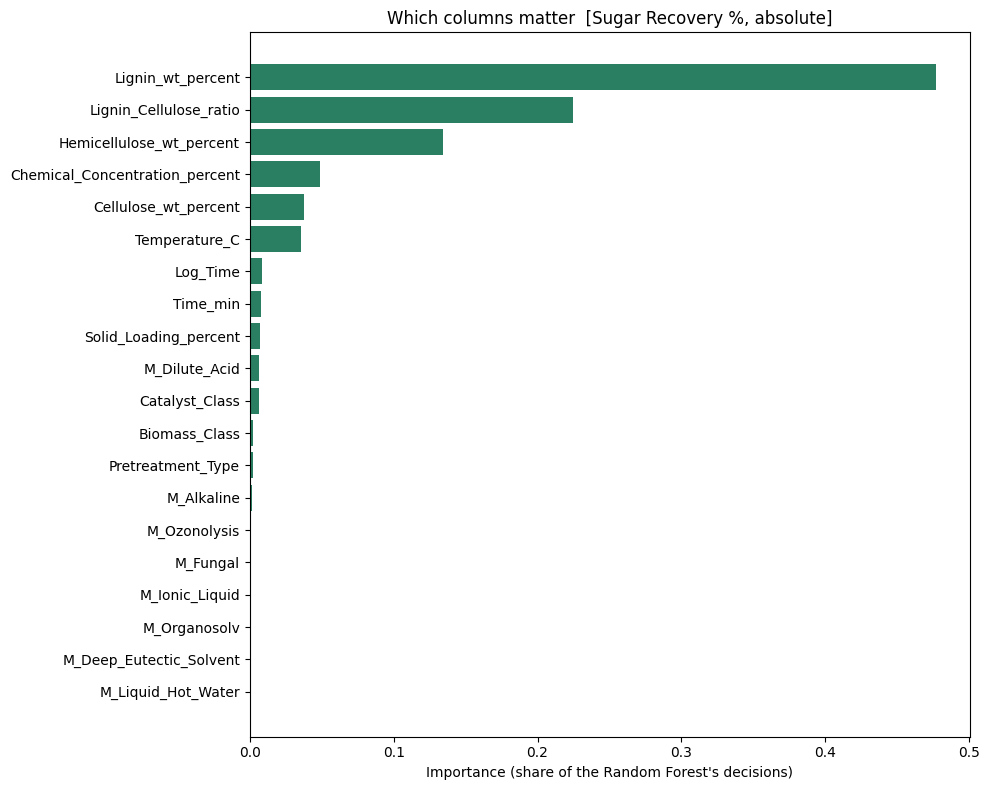


TOP COLUMNS: Lignin_wt_percent, Lignin_Cellulose_ratio, Hemicellulose_wt_percent, Chemical_Concentration_percent, Cellulose_wt_percent, Temperature_C, Log_Time, Time_min

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

RUN: POOLED | mode: absolute
!! Dropped 10 rows with yield outside 0-100% (likely mixed units).
Rows: 565 | Papers: 89 | Biomass: 49 | Methods: 41
Target mean 60.8, SD 25.2

PREDICTORS
  [dropped] pH                                  12.4% filled
  categorical: ['Catalyst_Class', 'Biomass_Class', 'Pretreatment_Type', 'Target_Yield_Type']
  numeric    : ['Cellulose_wt_percent', 'Hemicellulose_wt_percent', 'Lignin_wt_percent', 'Temperature_C', 'Time_min', 'Solid_Loading_percent', 'Chemical_Concentration_percent', 'Lignin_Cellulose_ratio', 'Log_Time', 'M_Dilute_Acid', 'M_Alkaline', 'M_Organosolv', 'M_Deep_Eutectic_Solvent', 'M_Liquid_Hot_Water', 'M_Microwave', 'M_Steam_Explosion', 'M_Ozonolysis', 'M_Fungal', 'M_Ionic_Liquid', 'M_Ultraso

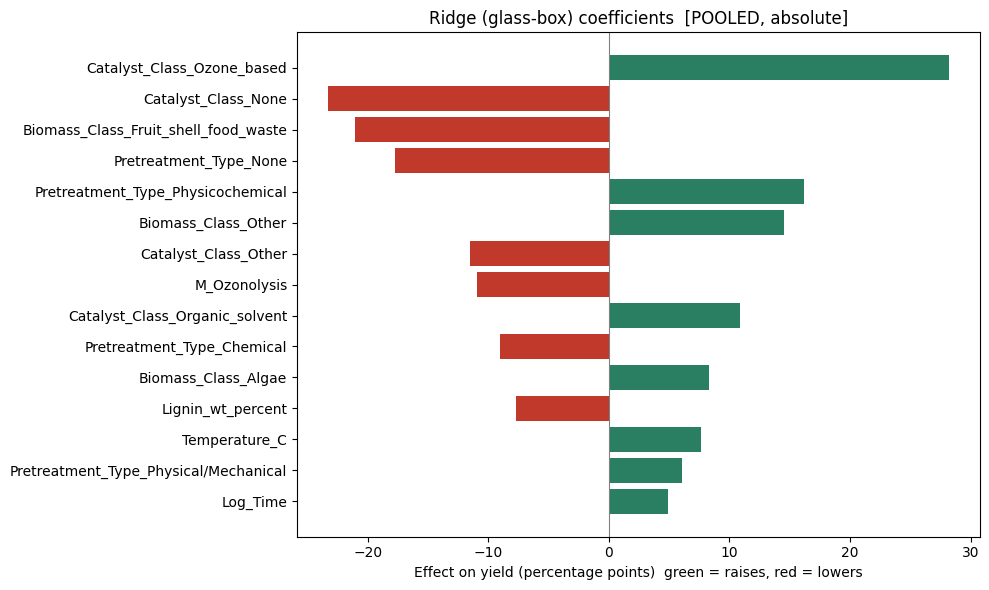

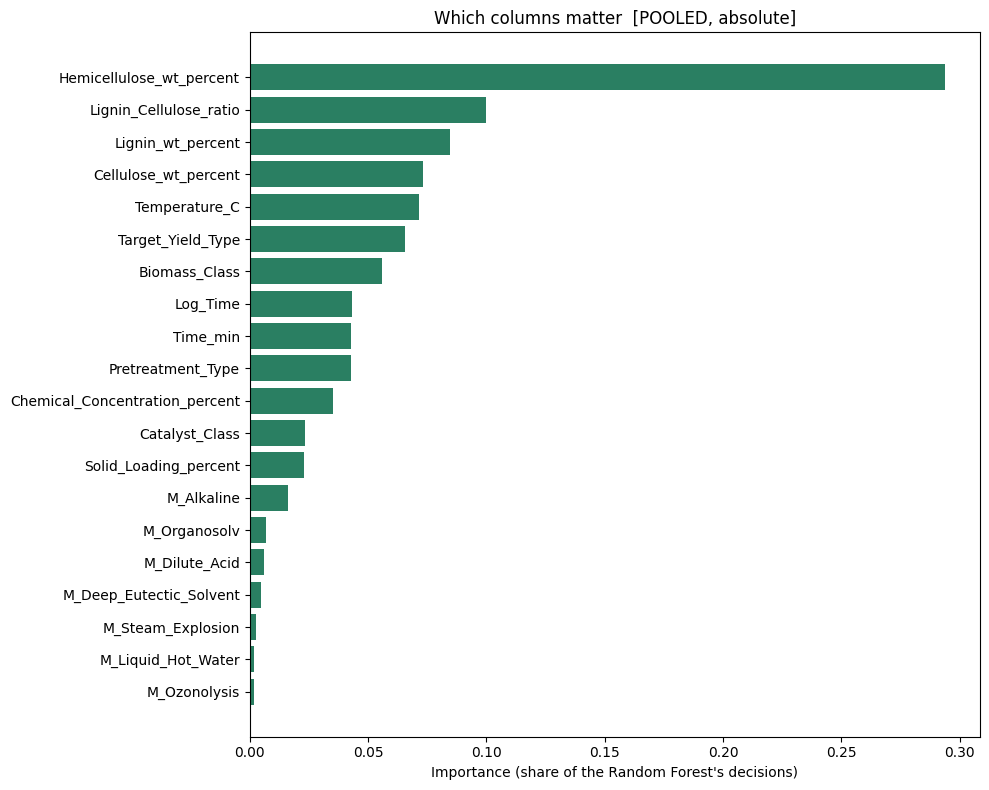


TOP COLUMNS: Hemicellulose_wt_percent, Lignin_Cellulose_ratio, Lignin_wt_percent, Cellulose_wt_percent, Temperature_C, Target_Yield_Type, Biomass_Class, Log_Time

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

RUN: Cellulose Conversion % | mode: within_paper
WITHIN-PAPER mode: target = yield minus that paper's mean (only papers with >=2 rows). R2/RMSE refer to this deviation.
Rows: 237 | Papers: 31 | Biomass: 23 | Methods: 25
Target mean -0.0, SD 15.5

PREDICTORS
  [dropped] pH                                  16.5% filled
  [dropped] M_Milling                          100.0% filled  (constant)
  categorical: ['Catalyst_Class', 'Biomass_Class', 'Pretreatment_Type']
  numeric    : ['Cellulose_wt_percent', 'Hemicellulose_wt_percent', 'Lignin_wt_percent', 'Temperature_C', 'Time_min', 'Solid_Loading_percent', 'Chemical_Concentration_percent', 'Lignin_Cellulose_ratio', 'Log_Time', 'M_Dilute_Acid', 'M_Alkaline', 'M_Organosolv', 'M_Deep_Eutectic_Solvent

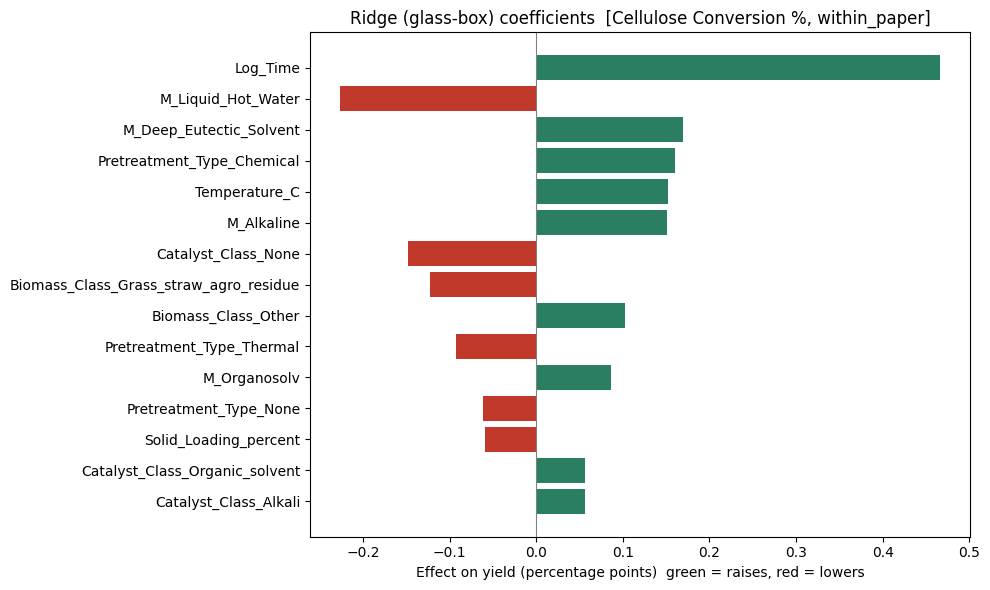

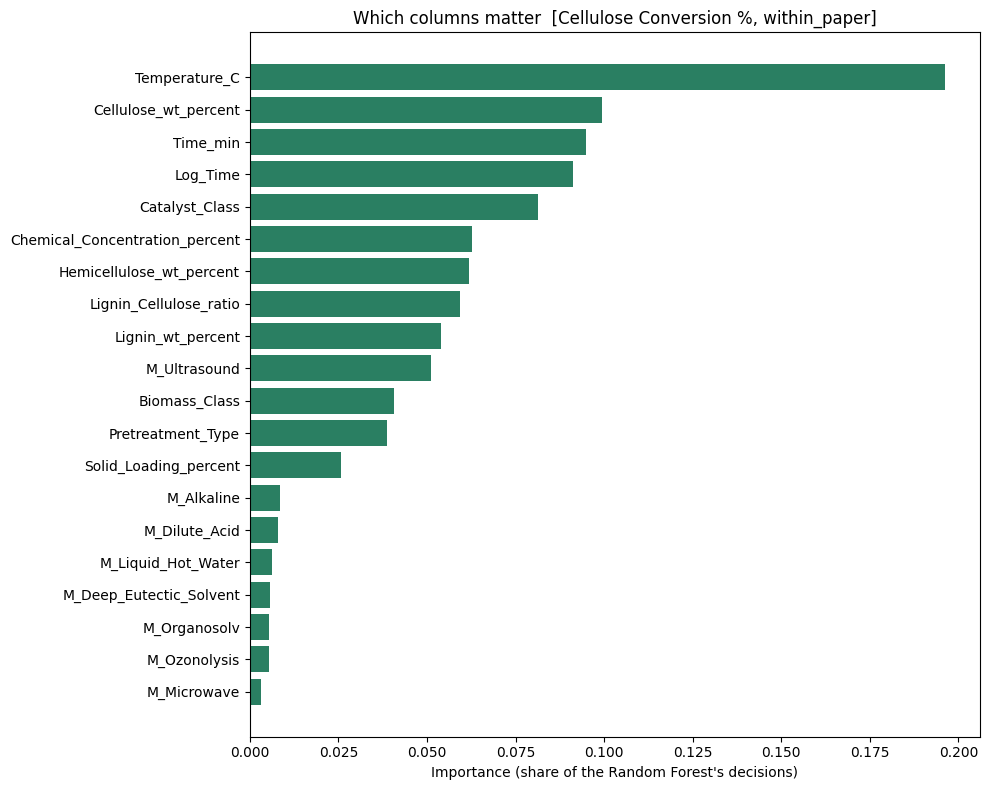


TOP COLUMNS: Temperature_C, Cellulose_wt_percent, Time_min, Log_Time, Catalyst_Class, Chemical_Concentration_percent, Hemicellulose_wt_percent, Lignin_Cellulose_ratio

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

RUN: Glucose Yield % | mode: within_paper
WITHIN-PAPER mode: target = yield minus that paper's mean (only papers with >=2 rows). R2/RMSE refer to this deviation.
Rows: 151 | Papers: 21 | Biomass: 15 | Methods: 19
Target mean -0.0, SD 14.6

PREDICTORS
  [dropped] pH                                   4.6% filled
  [dropped] M_Extrusion                        100.0% filled  (constant)
  categorical: ['Catalyst_Class', 'Biomass_Class', 'Pretreatment_Type']
  numeric    : ['Cellulose_wt_percent', 'Hemicellulose_wt_percent', 'Lignin_wt_percent', 'Temperature_C', 'Time_min', 'Solid_Loading_percent', 'Chemical_Concentration_percent', 'Lignin_Cellulose_ratio', 'Log_Time', 'M_Dilute_Acid', 'M_Alkaline', 'M_Organosolv', 'M_Deep_Eutectic_Solvent',

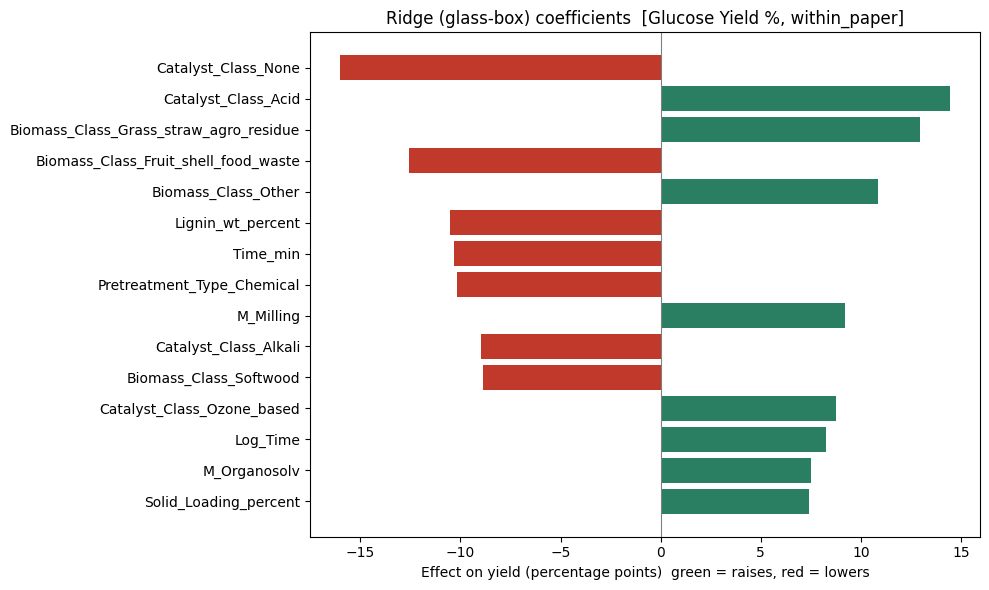

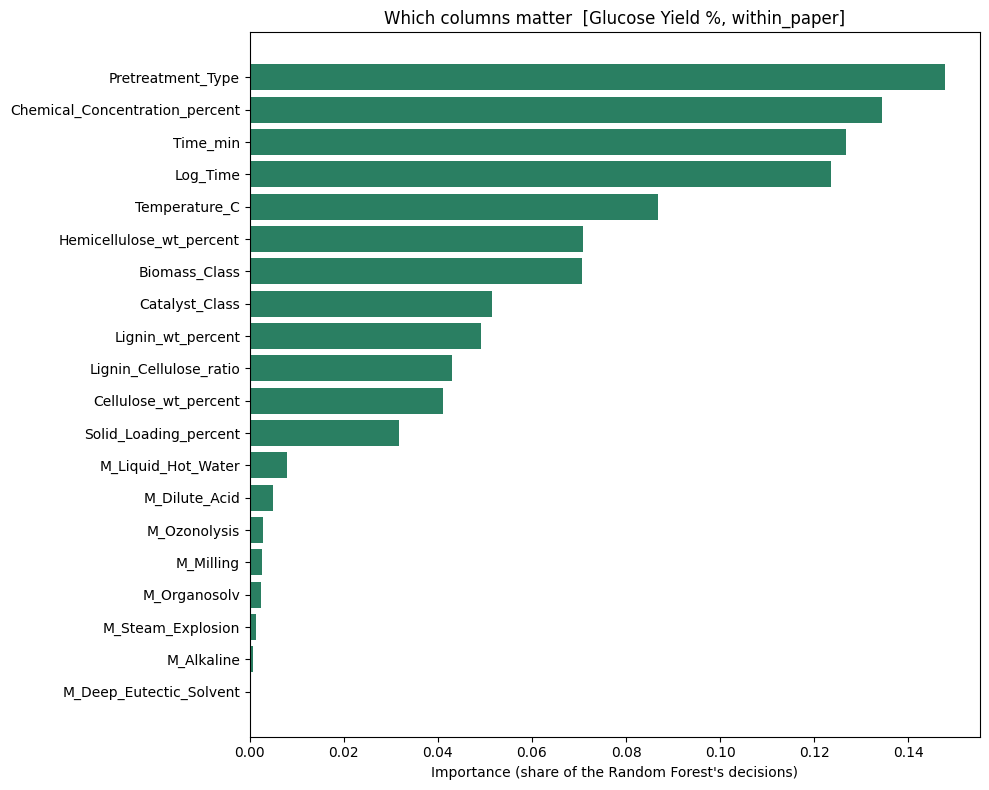


TOP COLUMNS: Pretreatment_Type, Chemical_Concentration_percent, Time_min, Log_Time, Temperature_C, Hemicellulose_wt_percent, Biomass_Class, Catalyst_Class

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

RUN: Sugar Recovery % | mode: within_paper
!! Dropped 10 rows with yield outside 0-100% (likely mixed units).
WITHIN-PAPER mode: target = yield minus that paper's mean (only papers with >=2 rows). R2/RMSE refer to this deviation.
Rows: 143 | Papers: 19 | Biomass: 18 | Methods: 13
Target mean -0.0, SD 10.5

PREDICTORS
  [dropped] pH                                  12.6% filled
  [dropped] M_Microwave                        100.0% filled  (constant)
  [dropped] M_Steam_Explosion                  100.0% filled  (constant)
  [dropped] M_Ultrasound                       100.0% filled  (constant)
  [dropped] M_Milling                          100.0% filled  (constant)
  [dropped] M_Extrusion                        100.0% filled  (constant)
  categorica

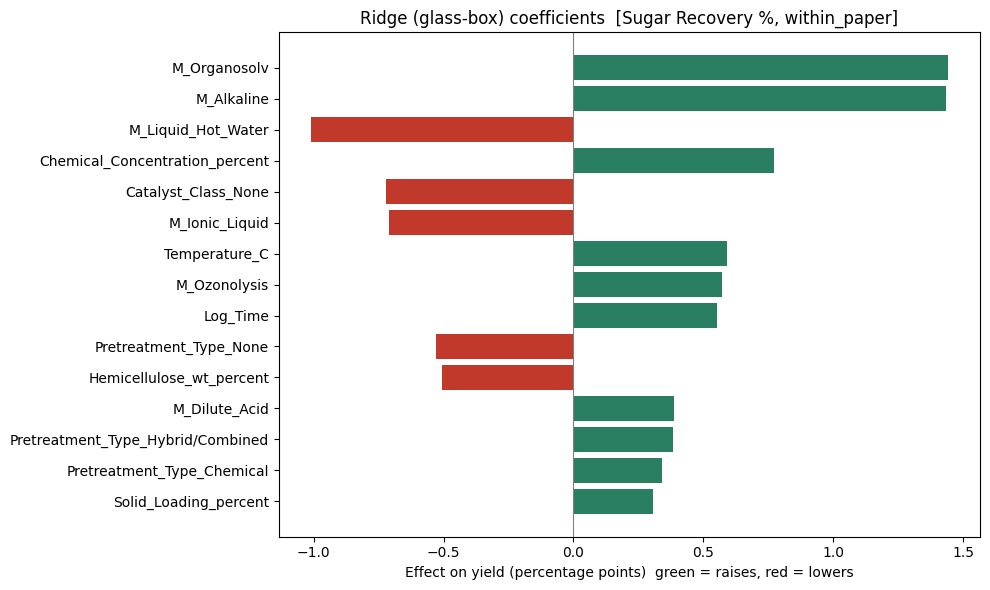

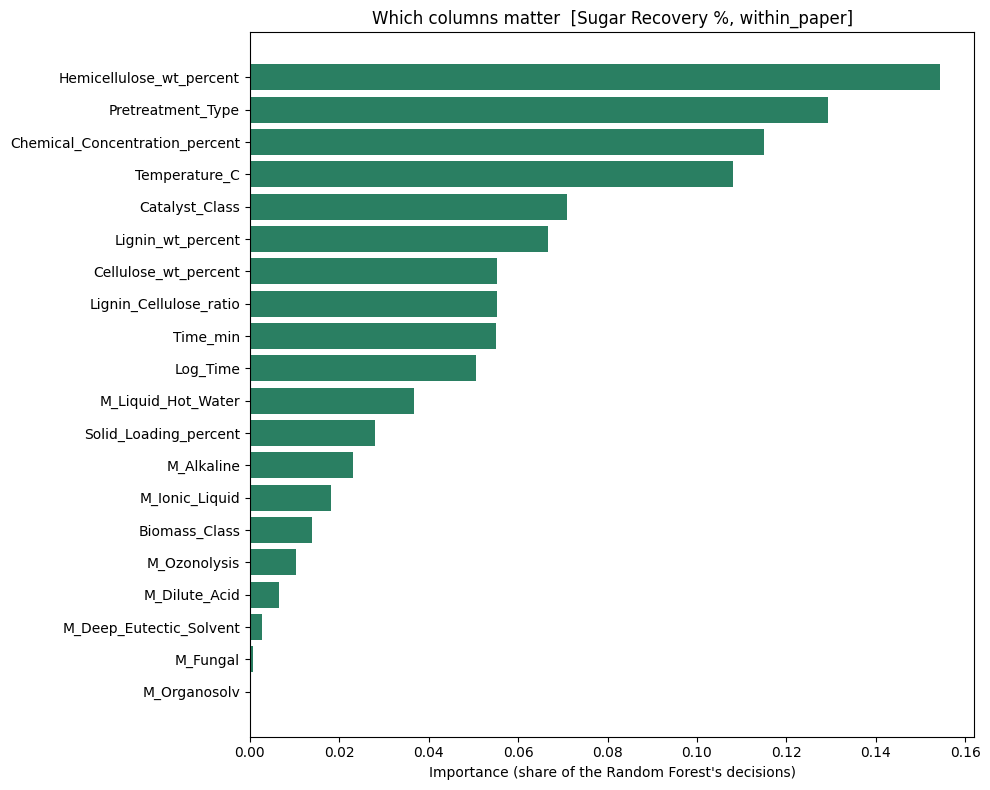


TOP COLUMNS: Hemicellulose_wt_percent, Pretreatment_Type, Chemical_Concentration_percent, Temperature_C, Catalyst_Class, Lignin_wt_percent, Cellulose_wt_percent, Lignin_Cellulose_ratio

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

RUN: POOLED | mode: within_paper
!! Dropped 10 rows with yield outside 0-100% (likely mixed units).
WITHIN-PAPER mode: target = yield minus that paper's mean (only papers with >=2 rows). R2/RMSE refer to this deviation.
Rows: 531 | Papers: 61 | Biomass: 38 | Methods: 33
Target mean -0.0, SD 14.0

PREDICTORS
  [dropped] pH                                  12.1% filled
  categorical: ['Catalyst_Class', 'Biomass_Class', 'Pretreatment_Type', 'Target_Yield_Type']
  numeric    : ['Cellulose_wt_percent', 'Hemicellulose_wt_percent', 'Lignin_wt_percent', 'Temperature_C', 'Time_min', 'Solid_Loading_percent', 'Chemical_Concentration_percent', 'Lignin_Cellulose_ratio', 'Log_Time', 'M_Dilute_Acid', 'M_Alkaline', 'M_Organosolv', 'M

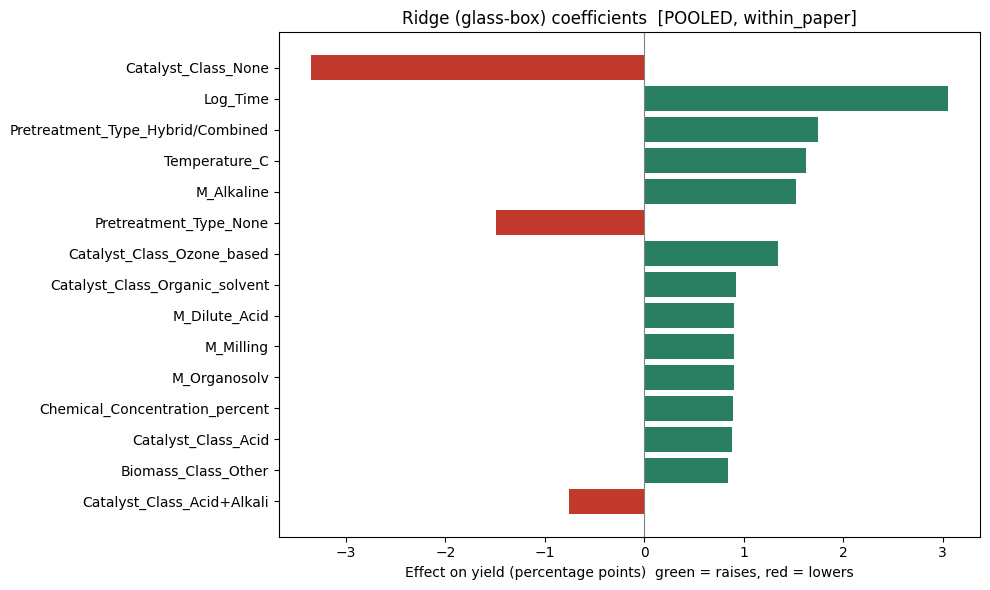

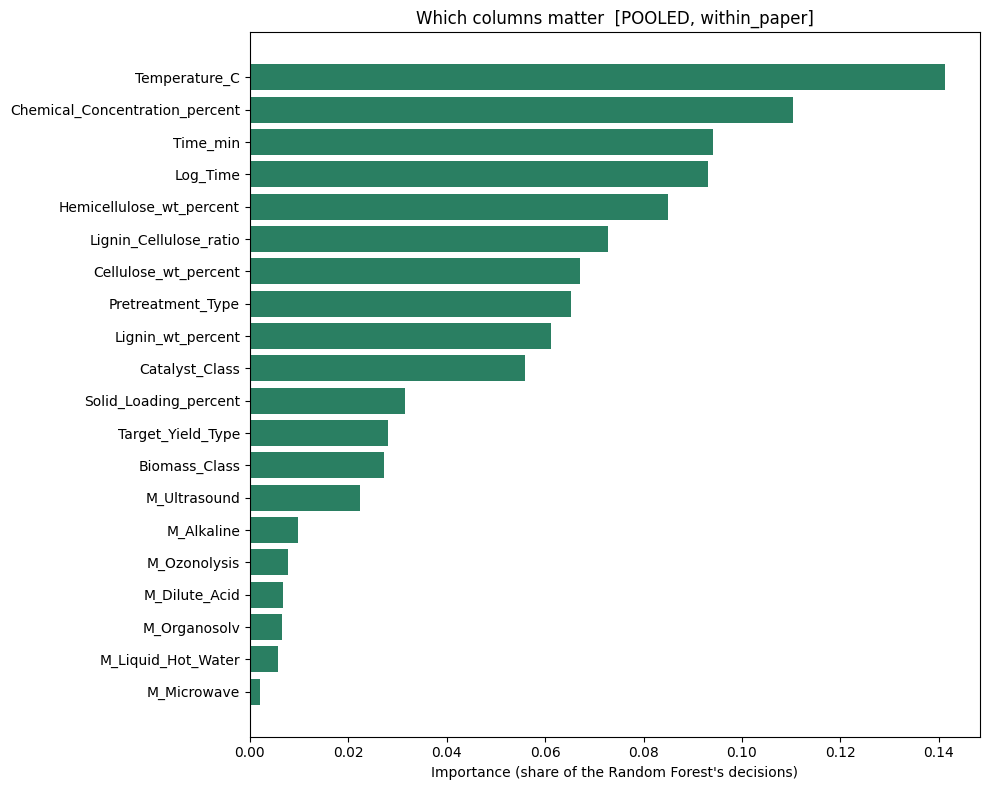


TOP COLUMNS: Temperature_C, Chemical_Concentration_percent, Time_min, Log_Time, Hemicellulose_wt_percent, Lignin_Cellulose_ratio, Cellulose_wt_percent, Pretreatment_Type

Optimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= 0.3).

SUMMARY OF ALL RUNS (paper-grouped validation)
                   Run         Mode  Rows  Papers        Best_model     R2   RMSE  Baseline_R2  Gain_vs_baseline
Cellulose Conversion %     absolute   251      45 Ridge (glass-box) -0.073 24.017       -0.031            -0.042
       Glucose Yield %     absolute   160      30       Extra Trees -0.839 30.368       -0.021            -0.818
      Sugar Recovery %     absolute   154      30     Random Forest -0.102 31.324       -0.180             0.078
                POOLED     absolute   565      89     Random Forest -0.104 26.421       -0.026            -0.078
Cellulose Conversion % within_paper   237      31       Extra Trees -0.060 15.929        0.000            -0.060
       Glucose Yi

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
# ================================================================
# BIOETHANOL / PRETREATMENT YIELD MODELLING  (v3)
# Pretreatment-focused targets | absolute + WITHIN-PAPER modes | glass-box plots
# ================================================================
# Paste into ONE Google Colab cell. Optional glass-box EBM:
#     !pip install interpret
# ================================================================
import re
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution
from sklearn.base import clone, BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor,
                              GradientBoostingRegressor,
                              HistGradientBoostingRegressor)
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
warnings.filterwarnings("ignore")

try:
    from interpret.glassbox import ExplainableBoostingRegressor
    HAS_EBM = True
except Exception:
    HAS_EBM = False
    print("NOTE: 'interpret' not installed -> EBM skipped. "
          "Run:  !pip install interpret")

# ---------------------------------------------------
# 1. CONFIGURATION
# ---------------------------------------------------
FILE_NAME = "/content/FINAL DATASET Changed.csv"
SHEET_NAME = 0
TARGET = "Target_Yield_percent"
YIELD_TYPE_COLUMN = "Target_Yield_Type"
BIOMASS_COL, TYPE_COL, METHOD_COL = "Biomass_Type", "Pretreatment_Type", "Pretreatment_Method"
PAPER_COL = "Paper_ID"
SEVERITY_COL = "Energy_Proxy_Severity_Factor"

# Each entry = one modelling run. One yield type  -> separate model.
# Several yield types -> POOLED model (yield type becomes a feature).
# Pretreatment effectiveness is measured by cellulose conversion / glucose /
# sugar recovery (they depend directly on pretreatment). Ethanol yield also
# depends on enzymes and fermentation, so it is NOT run by default.
# To add it, append ["Ethanol Yield %"] to RUNS.
RUNS = [
    ["Cellulose Conversion %"],
    ["Glucose Yield %"],
    ["Sugar Recovery %"],
    ["Cellulose Conversion %", "Glucose Yield %", "Sugar Recovery %"],   # pooled
]
# "absolute"     : predict the yield itself (hard: labs differ a lot)
# "within_paper" : predict yield minus that paper's own average yield, i.e.
#                  "which conditions beat the other conditions in the SAME paper"
TARGET_MODES = ["absolute", "within_paper"]
ADD_MISSING_INDICATORS = False   # False = model cannot learn "which paper omitted X"
OPTIMIZABLE_YIELD_TYPES = ["Glucose Yield %", "Ethanol Yield %",
                           "Sugar Recovery %", "Cellulose Conversion %"]
DROP_OUT_OF_RANGE = True      # drop yields <0 or >100 (mixed units) before modelling
MIN_ROWS_PER_RUN = 30
RANDOM_STATE = 42
N_FOLDS = 5
N_REPEATS = 3                 # repeated paper-grouped CV (more stable than 1 run)
OPTIMIZE_MIN_R2 = 0.30        # optimise only if validated R2 reaches this
MIN_COMPLETENESS = 0.20
MIN_ROWS_PER_COMBINATION = 5
MIN_VALUES_FOR_OPTIMIZATION = 5
LOWER_PERCENTILE, UPPER_PERCENTILE = 5, 95
OPTIMIZER_MAXITER, OPTIMIZER_POPSIZE = 60, 10
MIN_ROWS_PER_FLAG = 5         # a method component needs this many rows to get a 0/1 flag

# Very high-cardinality one-hots hurt on small data. Biomass is replaced by
# Biomass_Class; the specific method is replaced by 0/1 component flags.
USE_BIOMASS_ONEHOT = False
USE_METHOD_ONEHOT = False
USE_TYPE_ONEHOT = True

CATEGORICAL_BASE = ["Catalyst_Class", "Biomass_Class"]
NUMERIC_BASE = ["Cellulose_wt_percent", "Hemicellulose_wt_percent",
                "Lignin_wt_percent", "Moisture_wt_percent",
                "Temperature_C", "Pressure_MPa", "Time_min",
                "Solid_Loading_percent", "Chemical_Concentration_percent",
                "pH", "Energy_Proxy_Severity_Factor",
                "Lignin_Cellulose_ratio", "Log_Time"]
RAW_NUMERIC = ["Cellulose_wt_percent", "Hemicellulose_wt_percent",
               "Lignin_wt_percent", "Moisture_wt_percent", "Temperature_C",
               "Pressure_MPa", "Time_min", "Solid_Loading_percent",
               "Chemical_Concentration_percent", "pH", SEVERITY_COL]
OPTIMIZABLE_COLUMNS = ["Temperature_C", "Time_min",
                       "Chemical_Concentration_percent", "Solid_Loading_percent"]
COMPOSITION_COLUMNS = ["Cellulose_wt_percent", "Hemicellulose_wt_percent",
                       "Lignin_wt_percent", "Moisture_wt_percent"]
SEVERITY_TYPES = ["Thermal", "Physicochemical"]
SEVERITY_TERMS = ["hydrothermal", "steam explosion", "steam treatment",
                  "liquid hot water", "hot water", "autohydrolysis"]

# Heuristic biomass classes - CHECK these against your biomass list.
BIOMASS_CLASS_RULES = [
    ("Algae", ["algae", "macroalgae", "microalgae", "seaweed", "azolla", "spirulina"]),
    ("Softwood", ["softwood", "pine", "spruce", "fir", "cedar"]),
    ("Hardwood", ["hardwood", "poplar", "eucalyptus", "birch", "willow", "oak", "beech"]),
    ("Fruit_shell_food_waste", ["peel", "fruit bunch", "shell", "pomace", "kitchen", "food waste"]),
    ("Grass_straw_agro_residue", ["straw", "stover", "bagasse", "grass", "stalk", "stillage",
                                  "spent grain", "bran", "husk", "sugarcane", "switchgrass",
                                  "miscanthus", "cob", "hull"]),
]

def slug(s):
    return re.sub(r"[^A-Za-z0-9]+", "_", str(s)).strip("_")

# ---------------------------------------------------
# 2. LOAD
# ---------------------------------------------------
def find_file():
    for c in [FILE_NAME, "/content/" + FILE_NAME, "/content/drive/MyDrive/" + FILE_NAME]:
        if Path(c).exists():
            return Path(c)
    try:
        from google.colab import files
        print("Dataset not found. Please upload it now...")
        return Path(list(files.upload().keys())[0])
    except ImportError:
        raise FileNotFoundError(f"Dataset not found: {FILE_NAME}")

def load_dataset():
    path = find_file()
    na = ["NaN", "nan", ""]
    if path.suffix.lower() == ".csv":
        try:
            df = pd.read_csv(path, na_values=na, keep_default_na=False, encoding="utf-8")
        except UnicodeDecodeError:
            print("!! UTF-8 failed, retrying with cp1252")
            df = pd.read_csv(path, na_values=na, keep_default_na=False, encoding="cp1252")
    else:
        df = pd.read_excel(path, sheet_name=SHEET_NAME, na_values=na, keep_default_na=False)
    df.columns = df.columns.astype(str).str.strip()
    print("Dataset shape:", df.shape)
    return df

# ---------------------------------------------------
# 3. GLOBAL CLEANING + FEATURE ENGINEERING (all yield types, ~all papers)
# ---------------------------------------------------
def severity_applicable(method, ptype):
    m = str(method).lower()
    return (str(ptype) in SEVERITY_TYPES and "+" not in m
            and any(t in m for t in SEVERITY_TERMS))

def sat_pressure_mpa(T):
    T = np.asarray(T, float)
    p = np.where(T < 100, 10 ** (8.07131 - 1730.63 / (233.426 + T)),
                 10 ** (8.14019 - 1810.94 / (244.485 + T)))
    return p * 0.000133322

def catalyst_class(name):
    """Group ~120 catalyst strings into a few chemistry classes."""
    n = str(name).lower().replace(" ", "")
    if n in ("none", "nan", "water", "h2o", ""):
        return "None"
    if any(k in n for k in ("choline", "chcl", "[", "ionic", "urea")):
        return "DES_or_IonicLiquid"
    acid = any(k in n for k in ("h2so4", "hcl", "hno3", "h3po4", "acid", "c2h2o4", "oxalic"))
    alk = any(k in n for k in ("naoh", "koh", "nh4oh", "ammonia", "ca(oh)2", "na2co3", "na2s", "nacs", "lime"))
    if acid and alk:
        return "Acid+Alkali"
    if "o3" in n:
        return "Ozone_based"
    if "h2o2" in n or "peroxide" in n:
        return "Peroxide_based"
    if acid:
        return "Acid"
    if alk:
        return "Alkali"
    if any(k in n for k in ("ethanol", "acetone", "glycerol", "methanol", "organosolv")):
        return "Organic_solvent"
    return "Other"

def biomass_class(name):
    n = str(name).lower()
    for cls, kws in BIOMASS_CLASS_RULES:
        for kw in kws:
            if re.search(r"\b" + re.escape(kw) + r"s?\b", n):
                return cls
    return "Other"

def add_derived(frame):
    if {"Lignin_wt_percent", "Cellulose_wt_percent"} <= set(frame.columns):
        c = frame["Cellulose_wt_percent"].where(frame["Cellulose_wt_percent"] > 0)
        frame["Lignin_Cellulose_ratio"] = frame["Lignin_wt_percent"] / c
    if "Time_min" in frame.columns:
        frame["Log_Time"] = np.log1p(frame["Time_min"].clip(lower=0))
    return frame

def clean_global(raw):
    df = raw.copy()
    required = [TARGET, YIELD_TYPE_COLUMN, BIOMASS_COL, TYPE_COL, METHOD_COL, PAPER_COL]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Required columns missing: {missing}")
    for c in df.columns:
        df[c] = df[c].apply(lambda x: x.strip() if isinstance(x, str) else x)
        df[c] = df[c].replace("", np.nan)
    # stray repeated header rows (your counts showed 'Target_Yield_Type': 1)
    n0 = len(df)
    df = df[(df[YIELD_TYPE_COLUMN] != YIELD_TYPE_COLUMN) & (df[PAPER_COL] != PAPER_COL)]
    if len(df) < n0:
        print(f"Removed {n0 - len(df)} stray header row(s) inside the data.")
    for c in RAW_NUMERIC + [TARGET]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.dropna(subset=[TARGET, BIOMASS_COL, TYPE_COL, METHOD_COL]).reset_index(drop=True)

    # composition: fill from the SAME biomass type (feature-only, no target used)
    for c in COMPOSITION_COLUMNS:
        if c in df.columns:
            df[c] = df[c].fillna(df.groupby(BIOMASS_COL)[c].transform("median"))
    # pressure from temperature for steam/hot-water methods (saturated steam)
    if "Pressure_MPa" in df.columns and "Temperature_C" in df.columns:
        steam = df[METHOD_COL].str.lower().apply(lambda m: any(t in m for t in SEVERITY_TERMS))
        mask = (df["Pressure_MPa"].isna() & df["Temperature_C"].ge(100)
                & steam & df[TYPE_COL].isin(SEVERITY_TYPES))
        df.loc[mask, "Pressure_MPa"] = sat_pressure_mpa(df.loc[mask, "Temperature_C"])
        print(f"Pressure filled from temperature for {int(mask.sum())} rows.")
    # severity log10(R0) for single thermal methods
    if SEVERITY_COL in df.columns:
        app = df.apply(lambda r: severity_applicable(r[METHOD_COL], r[TYPE_COL]), axis=1)
        mask = (df[SEVERITY_COL].isna() & app
                & df["Time_min"].notna() & df["Temperature_C"].notna())
        df.loc[mask, SEVERITY_COL] = np.log10(
            df.loc[mask, "Time_min"] * np.exp((df.loc[mask, "Temperature_C"] - 100) / 14.75))
        print(f"Severity factor computed for {int(mask.sum())} rows.")

    df = add_derived(df)
    df["Biomass_Class"] = df[BIOMASS_COL].apply(biomass_class)
    df["Catalyst_Class"] = df["Catalyst_Chemical"].apply(catalyst_class)
    print("Catalyst classes:", df["Catalyst_Class"].value_counts().to_dict())

    # multi-hot method components: "A + B" shares signal with "A" and "B"
    tokens = df[METHOD_COL].str.split("+").explode().str.strip()
    counts = tokens.value_counts()
    flag_cols = []
    for t, cnt in counts.items():
        if cnt >= MIN_ROWS_PER_FLAG and t.lower() != "none":
            col = "M_" + slug(t)
            df[col] = df[METHOD_COL].apply(
                lambda m, t=t: int(t in [x.strip() for x in str(m).split("+")]))
            flag_cols.append(col)
    print("Method component flags:", flag_cols)

    cov = (df.groupby(YIELD_TYPE_COLUMN)
             .agg(Rows=(TARGET, "size"), Papers=(PAPER_COL, "nunique"),
                  Biomass=(BIOMASS_COL, "nunique"))
             .sort_values("Papers", ascending=False))
    print("\nDATA COVERAGE PER YIELD TYPE")
    print(cov.to_string())
    print(f"TOTAL: {len(df)} rows, {df[PAPER_COL].nunique()} papers")
    print("Biomass classes:", df["Biomass_Class"].value_counts().to_dict())
    return df, flag_cols

def subset_for_run(clean, yield_types, mode="absolute"):
    df = clean[clean[YIELD_TYPE_COLUMN].isin(yield_types)].copy()
    odd = ((df[TARGET] < 0) | (df[TARGET] > 100)).sum()
    if odd:
        if DROP_OUT_OF_RANGE:
            df = df[(df[TARGET] >= 0) & (df[TARGET] <= 100)]
            print(f"!! Dropped {odd} rows with yield outside 0-100% (likely mixed units).")
        else:
            print(f"!! {odd} rows outside 0-100% kept.")
    df = df.reset_index(drop=True)
    if mode == "within_paper":
        grp = [PAPER_COL, YIELD_TYPE_COLUMN]
        df = df[df.groupby(grp)[TARGET].transform("size") >= 2].copy()
        df["Yield_abs"] = df[TARGET]
        df[TARGET] = df[TARGET] - df.groupby(grp)[TARGET].transform("mean")
        df = df.reset_index(drop=True)
        print("WITHIN-PAPER mode: target = yield minus that paper's mean "
              "(only papers with >=2 rows). R2/RMSE refer to this deviation.")
    if len(df) < MIN_ROWS_PER_RUN:
        raise ValueError(f"only {len(df)} usable rows")
    print(f"Rows: {len(df)} | Papers: {df[PAPER_COL].nunique()} | "
          f"Biomass: {df[BIOMASS_COL].nunique()} | Methods: {df[METHOD_COL].nunique()}")
    print(f"Target mean {df[TARGET].mean():.1f}, SD {df[TARGET].std():.1f}")
    return df

# ---------------------------------------------------
# 4. FEATURES + PIPELINES
# ---------------------------------------------------
def select_features(df, flag_cols, pooled):
    cat_cand = list(CATEGORICAL_BASE)
    if USE_BIOMASS_ONEHOT: cat_cand.append(BIOMASS_COL)
    if USE_TYPE_ONEHOT: cat_cand.append(TYPE_COL)
    if USE_METHOD_ONEHOT: cat_cand.append(METHOD_COL)
    if pooled: cat_cand.append(YIELD_TYPE_COLUMN)
    num_cand = NUMERIC_BASE + flag_cols
    categorical, numeric = [], []
    print("\nPREDICTORS")
    for col in cat_cand + num_cand:
        if col not in df.columns:
            continue
        frac = df[col].notna().mean()
        const = df[col].nunique(dropna=True) < 2
        keep = frac >= MIN_COMPLETENESS and not const
        if not keep:
            print(f"  [dropped] {col:<34s} {frac:6.1%} filled{'  (constant)' if const else ''}")
            continue
        (categorical if col in cat_cand else numeric).append(col)
    print("  categorical:", categorical)
    print("  numeric    :", numeric)
    return {"categorical": categorical, "numeric": numeric, "all": categorical + numeric}

class EBMRegressorWrapper(BaseEstimator, RegressorMixin):
    """sklearn-style wrapper: EBM handles NaN & categories natively."""
    def __init__(self, cat_cols=None, interactions=3, learning_rate=0.02,
                 max_bins=32, min_samples_leaf=5, outer_bags=4, random_state=42):
        self.cat_cols = cat_cols
        self.interactions = interactions
        self.learning_rate = learning_rate
        self.max_bins = max_bins
        self.min_samples_leaf = min_samples_leaf
        self.outer_bags = outer_bags
        self.random_state = random_state
    def _prep(self, X):
        X = X.copy()
        cats = list(self.cat_cols or [])
        for c in X.columns:
            if c in cats:
                X[c] = X[c].fillna("Unknown").astype(str)
            else:
                X[c] = pd.to_numeric(X[c], errors="coerce").astype(float)
        return X
    def fit(self, X, y):
        self.model_ = ExplainableBoostingRegressor(
            interactions=self.interactions, learning_rate=self.learning_rate,
            max_bins=self.max_bins, min_samples_leaf=self.min_samples_leaf,
            outer_bags=self.outer_bags, random_state=self.random_state)
        self.model_.fit(self._prep(X), np.asarray(y))
        return self
    def predict(self, X):
        return self.model_.predict(self._prep(X))

def make_pipeline(model, features):
    if isinstance(model, EBMRegressorWrapper):
        return model
    num = Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=ADD_MISSING_INDICATORS)),
                    ("scaler", StandardScaler())])
    cat = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
                    ("encoder", OneHotEncoder(handle_unknown="ignore"))])
    pre = ColumnTransformer([("numeric", num, features["numeric"]),
                             ("categorical", cat, features["categorical"])])
    return Pipeline([("preprocessor", pre), ("model", model)])

def get_models(features):
    m = {
        "Mean baseline": DummyRegressor(strategy="mean"),
        "Ridge (glass-box)": RidgeCV(alphas=np.logspace(-1, 3, 20)),
        "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                               random_state=RANDOM_STATE, n_jobs=-1),
        "Extra Trees": ExtraTreesRegressor(n_estimators=300, min_samples_leaf=3,
                                           random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.04,
                                                       max_depth=3, subsample=0.8,
                                                       random_state=RANDOM_STATE),
        "HistGradientBoosting": HistGradientBoostingRegressor(
            max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=10,
            l2_regularization=1.0, random_state=RANDOM_STATE),
    }
    if HAS_EBM:
        m["EBM (glass-box)"] = EBMRegressorWrapper(cat_cols=features["categorical"],
                                                   random_state=RANDOM_STATE)
    return m

# ---------------------------------------------------
# 5. REPEATED PAPER-GROUPED VALIDATION
# ---------------------------------------------------
def grouped_splits(groups, n_splits, seed):
    """Whole groups (papers) are held out; assignment reshuffled per seed."""
    uniq = np.unique(groups)
    rng = np.random.RandomState(seed)
    rng.shuffle(uniq)
    fold_of = {g: i % n_splits for i, g in enumerate(uniq)}
    f = np.array([fold_of[g] for g in groups])
    for k in range(n_splits):
        yield np.where(f != k)[0], np.where(f == k)[0]

def get_groups(df):
    if df[PAPER_COL].notna().all() and df[PAPER_COL].nunique() >= 3:
        return df[PAPER_COL].astype(str).to_numpy(), "Paper-grouped"
    print("WARNING: Paper_ID unusable; row-level CV. Scores will be OPTIMISTIC.")
    return np.arange(len(df)).astype(str), "Row-level"

def train_and_compare(df, features, prefix, clip=True):
    X, y = df[features["all"]], df[TARGET]
    groups, cv_name = get_groups(df)
    n_splits = min(N_FOLDS, len(np.unique(groups)))
    print(f"\nValidation: {cv_name}, {n_splits} folds x {N_REPEATS} repeats "
          f"({len(np.unique(groups))} groups)")
    rows, oof_store = [], {}
    for name, model in get_models(features).items():
        print("Evaluating:", name)
        try:
            r2s, rmses, maes, errs, last = [], [], [], [], None
            for r in range(N_REPEATS):
                pred = np.full(len(y), np.nan)
                for tr, te in grouped_splits(groups, n_splits, RANDOM_STATE + r):
                    fit = make_pipeline(clone(model), features).fit(X.iloc[tr], y.iloc[tr])
                    pred[te] = fit.predict(X.iloc[te])
                if clip:
                    pred = np.clip(pred, 0, 100)
                r2s.append(r2_score(y, pred))
                rmses.append(np.sqrt(mean_squared_error(y, pred)))
                maes.append(mean_absolute_error(y, pred))
                errs.append(np.abs(y.to_numpy() - pred))
                last = pred
        except Exception as exc:
            print(f"  skipped {name}: {exc}")
            continue
        oof_store[name] = np.concatenate(errs)
        rows.append({"Model": name, "Validation": cv_name,
                     "R2_mean": np.mean(r2s), "R2_SD_over_repeats": np.std(r2s),
                     "RMSE": np.mean(rmses), "MAE": np.mean(maes)})
    comp = pd.DataFrame(rows).sort_values(["R2_mean", "RMSE"], ascending=[False, True]).reset_index(drop=True)
    base_r2 = comp.loc[comp["Model"] == "Mean baseline", "R2_mean"].iloc[0]
    comp["R2_gain_vs_baseline"] = comp["R2_mean"] - base_r2
    comp.to_csv(f"{prefix}_model_comparison.csv", index=False)
    print("\nMODEL COMPARISON (out-of-fold, paper-grouped)")
    print(comp.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
    cand = comp[comp["Model"] != "Mean baseline"]
    best_name = cand.iloc[0]["Model"]
    best_r2, best_rmse = cand.iloc[0]["R2_mean"], cand.iloc[0]["RMSE"]
    if best_r2 <= base_r2 + 0.02:
        print("WARNING: no model clearly beats the mean baseline. Predictions are unreliable.")
    elif best_r2 < 0.3:
        print("WARNING: low validated R2. Treat results as exploratory.")
    half_width = float(np.percentile(oof_store[best_name], 90))
    print(f"Best: {best_name} | R2 {best_r2:.3f} | RMSE {best_rmse:.2f} | "
          f"90% of errors within +/- {half_width:.1f} points")
    validate_unseen_biomass(df, features, best_name, prefix, clip)
    fitted = make_pipeline(get_models(features)[best_name], features).fit(X, y)
    return best_name, fitted, half_width, best_r2, best_rmse, base_r2

def validate_unseen_biomass(df, features, model_name, prefix, clip=True):
    if df[BIOMASS_COL].nunique() < N_FOLDS:
        return
    X, y = df[features["all"]], df[TARGET]
    groups = df[BIOMASS_COL].astype(str).to_numpy()
    pred = np.full(len(y), np.nan)
    for tr, te in grouped_splits(groups, N_FOLDS, RANDOM_STATE):
        try:
            fit = make_pipeline(clone(get_models(features)[model_name]), features)
            fit.fit(X.iloc[tr], y.iloc[tr])
            pred[te] = np.clip(fit.predict(X.iloc[te]), 0, 100) if clip else fit.predict(X.iloc[te])
        except Exception as exc:
            print("Unseen-biomass fold failed:", exc)
    ok = ~np.isnan(pred)
    if ok.sum() >= 2:
        r2 = r2_score(y[ok], pred[ok])
        rmse = np.sqrt(mean_squared_error(y[ok], pred[ok]))
        print(f"Unseen-biomass transfer: R2 {r2:.3f} | RMSE {rmse:.2f}")
        pd.DataFrame([{"R2": r2, "RMSE": rmse, "Rows": int(ok.sum())}]).to_csv(
            f"{prefix}_unseen_biomass_validation.csv", index=False)

# ---------------------------------------------------
# 6. GLASS-BOX EXPLANATIONS
# ---------------------------------------------------
def explain_glassbox(df, features, prefix):
    X, y = df[features["all"]], df[TARGET]
    ridge = make_pipeline(RidgeCV(alphas=np.logspace(-1, 3, 20)), features).fit(X, y)
    names = ridge.named_steps["preprocessor"].get_feature_names_out()
    coef = pd.DataFrame({
        "Feature": [n.replace("numeric__", "").replace("categorical__", "") for n in names],
        "Coefficient": ridge.named_steps["model"].coef_})
    coef = coef.reindex(coef["Coefficient"].abs().sort_values(ascending=False).index)
    coef.to_csv(f"{prefix}_ridge_coefficients.csv", index=False)
    print("\nRIDGE: yield-% change per +1 SD (numeric) or per category (one-hot)")
    print(coef.head(15).to_string(index=False, float_format=lambda v: f"{v:+.2f}"))

    if HAS_EBM:
        try:
            w = EBMRegressorWrapper(cat_cols=features["categorical"],
                                    random_state=RANDOM_STATE).fit(X, y)
            expl = w.model_.explain_global()
            d = expl.data()
            imp = pd.DataFrame({"Term": d["names"], "Importance": d["scores"]}
                               ).sort_values("Importance", ascending=False)
            imp.to_csv(f"{prefix}_ebm_term_importance.csv", index=False)
            print("\nEBM TERM IMPORTANCE (top 12)")
            print(imp.head(12).to_string(index=False, float_format=lambda v: f"{v:.2f}"))
            top = imp.head(9)["Term"].tolist()
            fig, axes = plt.subplots(3, 3, figsize=(15, 11))
            for ax in axes.ravel():
                ax.axis("off")
            for ax, term in zip(axes.ravel(), top):
                ax.axis("on")
                sd = expl.data(d["names"].index(term))
                x, s = list(sd["names"]), list(sd["scores"])
                if sd.get("type") != "univariate":
                    ax.set_title(term + " (interaction)", fontsize=9)
                    continue
                if len(x) == len(s) + 1:
                    ax.step(x, s + [s[-1]], where="post")
                else:
                    ax.bar(range(len(x)), s)
                    ax.set_xticks(range(len(x)))
                    ax.set_xticklabels(x, rotation=60, ha="right", fontsize=7)
                ax.axhline(0, color="grey", lw=0.5)
                ax.set_title(term, fontsize=9)
                ax.set_ylabel("effect on yield (%)")
            plt.tight_layout()
            plt.savefig(f"{prefix}_ebm_shapes.png", dpi=200)
            plt.show()
        except Exception as exc:
            print("EBM explanation failed:", exc)

def plot_importance(df, features, prefix, title_suffix=""):
    """Bar-chart ('histogram style') of which COLUMNS matter, from a Random Forest.
    One-hot pieces are added back together, so 'Catalyst_Class' is one bar."""
    X, y = df[features["all"]], df[TARGET]
    rf = make_pipeline(RandomForestRegressor(n_estimators=500, min_samples_leaf=3,
                                             random_state=RANDOM_STATE, n_jobs=-1), features).fit(X, y)
    names = rf.named_steps["preprocessor"].get_feature_names_out()
    imp = rf.named_steps["model"].feature_importances_
    rows = {}
    for n, v in zip(names, imp):
        n = n.replace("numeric__", "").replace("categorical__", "")
        base = n
        for c in features["categorical"]:
            if n.startswith(c + "_"):
                base = c
                break
        if n.startswith("missingindicator_"):
            base = n.replace("missingindicator_", "") + " (missing flag)"
        rows[base] = rows.get(base, 0.0) + float(v)
    t = (pd.DataFrame({"Column": list(rows), "Importance": list(rows.values())})
           .sort_values("Importance", ascending=False).reset_index(drop=True))
    t.to_csv(f"{prefix}_column_importance.csv", index=False)
    top = t.head(20)
    plt.figure(figsize=(10, 8))
    plt.barh(top["Column"][::-1], top["Importance"][::-1], color="#2a7f62")
    plt.xlabel("Importance (share of the Random Forest's decisions)")
    plt.title(f"Which columns matter  {title_suffix}")
    plt.tight_layout()
    plt.savefig(f"{prefix}_feature_importance.png", dpi=200)
    plt.show()
    print("\nTOP COLUMNS:", ", ".join(top["Column"].head(8)))

def plot_ridge(prefix, title_suffix=""):
    try:
        c = pd.read_csv(f"{prefix}_ridge_coefficients.csv").head(15)
        plt.figure(figsize=(10, 6))
        plt.barh(c["Feature"][::-1], c["Coefficient"][::-1],
                 color=["#2a7f62" if v > 0 else "#c0392b" for v in c["Coefficient"][::-1]])
        plt.axvline(0, color="grey", lw=0.8)
        plt.xlabel("Effect on yield (percentage points)  green = raises, red = lowers")
        plt.title(f"Ridge (glass-box) coefficients  {title_suffix}")
        plt.tight_layout()
        plt.savefig(f"{prefix}_ridge_coefficients.png", dpi=200)
        plt.show()
    except Exception as exc:
        print("Ridge plot failed:", exc)

# ---------------------------------------------------
# 7. OPTIMISATION (single yield type, only if the model is validated)
# ---------------------------------------------------
def safe_median(s):
    v = pd.to_numeric(s, errors="coerce").dropna()
    return float(v.median()) if len(v) else np.nan

def safe_mode(s):
    v = s.dropna()
    return v.mode().iloc[0] if len(v) else np.nan

def get_bounds(series):
    v = pd.to_numeric(series, errors="coerce").dropna()
    v = v[np.isfinite(v)]
    if len(v) < MIN_VALUES_FOR_OPTIMIZATION or v.nunique() < MIN_VALUES_FOR_OPTIMIZATION:
        return None
    lo, hi = np.percentile(v, [LOWER_PERCENTILE, UPPER_PERCENTILE])
    return (float(lo), float(hi)) if np.isfinite(lo) and np.isfinite(hi) and hi > lo else None

def optimize_all_combinations(df, features, model, half_width, prefix):
    combos = df[[BIOMASS_COL, TYPE_COL, METHOD_COL]].drop_duplicates()
    print(f"\nOptimising {len(combos)} biomass x method combinations...")
    results = []
    for _, cid in combos.iterrows():
        biomass, ptype, method = cid[BIOMASS_COL], cid[TYPE_COL], cid[METHOD_COL]
        combo = df[(df[BIOMASS_COL] == biomass) & (df[TYPE_COL] == ptype) & (df[METHOD_COL] == method)]
        method_data = df[(df[TYPE_COL] == ptype) & (df[METHOD_COL] == method)]
        biomass_data = df[df[BIOMASS_COL] == biomass]
        n = len(combo)
        support = "ADEQUATE" if n >= MIN_ROWS_PER_COMBINATION else "LOW"
        baseline = {}
        for col in features["categorical"]:
            if col == BIOMASS_COL: baseline[col] = biomass
            elif col == TYPE_COL: baseline[col] = ptype
            elif col == METHOD_COL: baseline[col] = method
            else:
                v = safe_mode(combo[col])
                baseline[col] = v if pd.notna(v) else safe_mode(method_data[col])
        for col in features["numeric"]:
            if col in COMPOSITION_COLUMNS:
                baseline[col] = safe_median(biomass_data[col])
            else:
                v = safe_median(combo[col])
                baseline[col] = v if pd.notna(v) else safe_median(method_data[col])
        bounds_by_col, bsrc = {}, {}
        for col in OPTIMIZABLE_COLUMNS:
            if col not in features["numeric"]:
                continue
            b, src = get_bounds(combo[col]), "biomass-method"
            if b is None:
                b, src = get_bounds(method_data[col]), "method-level"
            if b is not None:
                bounds_by_col[col], bsrc[col] = b, src
        names = list(bounds_by_col)
        bounds = [bounds_by_col[c] for c in names]
        recompute_sev = (SEVERITY_COL in features["numeric"]
                         and severity_applicable(method, ptype)
                         and method_data[SEVERITY_COL].notna().mean() >= 0.5
                         and {"Time_min", "Temperature_C"} <= set(features["all"]))

        def make_frame(x, n_rows):
            frame = pd.DataFrame({c: [baseline[c]] * n_rows for c in features["all"]})
            for i, col in enumerate(names):
                frame[col] = x[i]
            for col in features["numeric"]:
                frame[col] = pd.to_numeric(frame[col], errors="coerce")
            if recompute_sev:
                with np.errstate(over="ignore", invalid="ignore"):
                    frame[SEVERITY_COL] = np.log10(
                        frame["Time_min"] * np.exp((frame["Temperature_C"] - 100) / 14.75))
            tmp = add_derived(frame.copy())
            for c in ("Lignin_Cellulose_ratio", "Log_Time"):
                if c in features["all"] and c in tmp.columns:
                    frame[c] = tmp[c]
            for col in features["categorical"]:
                frame[col] = frame[col].astype(object)
            return frame[features["all"]]

        def objective(x):
            x = np.asarray(x)
            if x.ndim == 1:
                x = x.reshape(-1, 1)
            return -np.clip(model.predict(make_frame(x, x.shape[1])), 0, 100)

        if names:
            try:
                res = differential_evolution(objective, bounds, seed=RANDOM_STATE,
                                             maxiter=OPTIMIZER_MAXITER, popsize=OPTIMIZER_POPSIZE,
                                             tol=1e-6, polish=False, vectorized=True,
                                             updating="deferred")
                best_x, predicted = np.asarray(res.x), float(-res.fun)
                status = "OPTIMIZED" if support == "ADEQUATE" else "OPTIMIZED_LOW_SUPPORT"
            except Exception as exc:
                print(f"Optimisation failed {biomass}/{method}: {exc}")
                best_x, predicted, status = np.array([]), np.nan, "OPTIMIZATION_FAILED"
        else:
            best_x = np.array([])
            predicted = float(np.clip(model.predict(make_frame(np.empty((0, 1)), 1))[0], 0, 100))
            status = "PREDICTION_ONLY_NO_SUPPORTED_RANGE"
        rec = {"Biomass_Type": biomass, "Pretreatment_Type": ptype, "Pretreatment_Method": method,
               "Observed_rows": n, "Support_status": support, "Optimization_status": status,
               "Predicted_Yield_percent": predicted,
               "Interval_low_90pct": max(0.0, predicted - half_width),
               "Interval_high_90pct": min(100.0, predicted + half_width),
               "Observed_max_yield": combo[TARGET].max(),
               "Observed_mean_yield": combo[TARGET].mean(),
               "Optimized_variables": "; ".join(names)}
        for col, val in zip(names, best_x):
            rec[f"Optimal_{col}"] = float(val)
            rec[f"Bounds_{col}"] = f"{bounds_by_col[col][0]:.4g} to {bounds_by_col[col][1]:.4g}"
        for col in features["numeric"]:
            if col not in names:
                rec[f"Held_{col}"] = baseline[col]
        results.append(rec)
    out = pd.DataFrame(results).sort_values([BIOMASS_COL, "Predicted_Yield_percent"],
                                            ascending=[True, False])
    out.to_csv(f"{prefix}_all_biomass_method_optimization.csv", index=False)
    picks = []
    for _, g in out.dropna(subset=["Predicted_Yield_percent"]).groupby(BIOMASS_COL):
        ad = g[g["Support_status"] == "ADEQUATE"]
        pool = ad if len(ad) else g
        row = pool.loc[pool["Predicted_Yield_percent"].idxmax()].copy()
        row["Chosen_from"] = "ADEQUATE" if len(ad) else "LOW-support only"
        picks.append(row)
    best = pd.DataFrame(picks)
    best.to_csv(f"{prefix}_best_method_per_biomass.csv", index=False)
    print(best[["Biomass_Type", "Pretreatment_Method", "Predicted_Yield_percent",
                "Interval_low_90pct", "Interval_high_90pct", "Observed_rows",
                "Chosen_from"]].to_string(index=False, float_format=lambda v: f"{v:.1f}"))

# ---------------------------------------------------
# 9. MIXED-EFFECTS (meta-analysis style) MODEL: the glass-box answer
# ---------------------------------------------------
def run_mixed_effects(clean, flag_cols):
    """yield ~ conditions + method flags + (random intercept per paper).
    The paper random effect absorbs lab-to-lab differences, so the coefficients
    show what changes yield INSIDE papers, with p-values and confidence bands.
    Needs:  pip install statsmodels   (preinstalled in Colab)"""
    try:
        import statsmodels.formula.api as smf
    except Exception:
        print("statsmodels not available -> mixed-effects model skipped.")
        return
    types = ["Cellulose Conversion %", "Glucose Yield %", "Sugar Recovery %"]
    d = clean[clean[YIELD_TYPE_COLUMN].isin(types)].copy()
    d = d[(d[TARGET] >= 0) & (d[TARGET] <= 100)]
    d["Temp_per_50C"] = (d["Temperature_C"] - 100) / 50
    d["Log10_time_min"] = np.log10(d["Time_min"].clip(lower=1))
    d["Conc_per_10pct"] = d["Chemical_Concentration_percent"].clip(upper=30) / 10
    d["Solid_per_10pct"] = d["Solid_Loading_percent"] / 10
    d["ytype"] = d[YIELD_TYPE_COLUMN]
    use = ["Temp_per_50C", "Log10_time_min", "Conc_per_10pct", "Solid_per_10pct"]
    d = d.dropna(subset=use + [TARGET, PAPER_COL])
    flags = [f for f in flag_cols if d[f].sum() >= 15 and (len(d) - d[f].sum()) >= 15]
    formula = TARGET + " ~ " + " + ".join(use + flags) + " + C(ytype)"
    try:
        res = smf.mixedlm(formula, d, groups=d[PAPER_COL]).fit(reml=True)
    except Exception as exc:
        print("Mixed model failed:", exc)
        return
    ci = res.conf_int()
    t = pd.DataFrame({"Effect_on_yield_points": res.params, "Low95": ci[0],
                      "High95": ci[1], "p_value": res.pvalues})
    t = t.drop(index=[i for i in t.index if i in ("Group Var", "Intercept")], errors="ignore")
    t.to_csv("mixed_effects_coefficients.csv")
    share = res.cov_re.iloc[0, 0] / (res.cov_re.iloc[0, 0] + res.scale)
    print("\n" + "=" * 70 + "\nMIXED-EFFECTS MODEL (paper = random effect)\n" + "=" * 70)
    print(f"{len(d)} rows, {d[PAPER_COL].nunique()} papers. "
          f"{share:.0%} of yield variance is between-paper (lab) differences.")
    print("Units: Temp per +50 C | Log10_time per x10 time | Conc per +10 % | "
          "Solid per +10 % | M_* = method used vs not used")
    print(t.round(3).to_string())
    print("p < 0.05 = effect is statistically reliable inside papers.")
    tt = t[~t.index.str.startswith("C(ytype)")].sort_values("Effect_on_yield_points")
    plt.figure(figsize=(9, 6))
    ypos = np.arange(len(tt))
    plt.errorbar(tt["Effect_on_yield_points"], ypos,
                 xerr=[tt["Effect_on_yield_points"] - tt["Low95"],
                       tt["High95"] - tt["Effect_on_yield_points"]],
                 fmt="o", color="#2a7f62", ecolor="grey", capsize=3)
    plt.yticks(ypos, tt.index)
    plt.axvline(0, color="red", lw=0.8)
    plt.xlabel("Change in yield (percentage points) with 95% confidence band")
    plt.title("What changes yield inside the same paper (mixed-effects)")
    plt.tight_layout()
    plt.savefig("mixed_effects_effects.png", dpi=200)
    plt.show()

# ---------------------------------------------------
# 10. MAIN
# ---------------------------------------------------
def main():
    raw = load_dataset()
    clean, flag_cols = clean_global(raw)
    run_mixed_effects(clean, flag_cols)
    summary = []
    for mode in TARGET_MODES:
        for yield_types in RUNS:
            pooled = len(yield_types) > 1
            label = "POOLED" if pooled else yield_types[0]
            prefix = f"{slug(label)}_{mode}"
            print("\n" + "=" * 70 + f"\nRUN: {label} | mode: {mode}\n" + "=" * 70)
            try:
                df = subset_for_run(clean, yield_types, mode)
                features = select_features(df, flag_cols, pooled)
                name, model, hw, r2, rmse, base = train_and_compare(
                    df, features, prefix, clip=(mode == "absolute"))
            except Exception as exc:
                print(f"RUN SKIPPED ({label}, {mode}): {exc}")
                continue
            explain_glassbox(df, features, prefix)
            plot_ridge(prefix, f"[{label}, {mode}]")
            plot_importance(df, features, prefix, f"[{label}, {mode}]")
            if (mode == "absolute" and not pooled
                    and yield_types[0] in OPTIMIZABLE_YIELD_TYPES and r2 >= OPTIMIZE_MIN_R2):
                optimize_all_combinations(df, features, model, hw, prefix)
            else:
                print("\nOptimisation SKIPPED (needs: absolute mode, single yield type, validated R2 >= "
                      f"{OPTIMIZE_MIN_R2}).")
            summary.append({"Run": label, "Mode": mode, "Rows": len(df),
                            "Papers": df[PAPER_COL].nunique(), "Best_model": name,
                            "R2": r2, "RMSE": rmse, "Baseline_R2": base,
                            "Gain_vs_baseline": r2 - base})
    if summary:
        s_ = pd.DataFrame(summary)
        s_.to_csv("summary_all_runs.csv", index=False)
        print("\n" + "=" * 70 + "\nSUMMARY OF ALL RUNS (paper-grouped validation)\n" + "=" * 70)
        print(s_.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
    try:
        from google.colab import files
        for f in list(Path(".").glob("*.csv")) + list(Path(".").glob("*.png")):
            files.download(str(f))
    except Exception:
        pass

if __name__ == "__main__":
    main()